# Autoencoders and Variational Autoencoders

This notebook presents autoencoder compression, a standard VAE, a flow-VAE and a beta-VAE study on MNIST and Fashion-MNIST. The saved experiments compare reconstruction, likelihood bounds, generation and latent-space behaviour.

## Part 1: Autoencoder Compression

A simple deterministic autoencoder was trained with six latent sizes. Reconstruction errors and the same input images were compared across models.


In [ ]:
import gzip, json, math, random, struct, time, urllib.request
from datetime import datetime, timezone
from functools import lru_cache
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset, Subset, random_split
from IPython.display import display, Markdown

SEED = 42
DATASET_NAMES = ['mnist', 'fashion_mnist']
LATENT_SIZES = [2, 8, 16, 32, 64, 128]
EPOCHS = 20
BATCH_SIZE = 256
LEARNING_RATE = 1e-3
SMOKE_TEST = False  # Debug only;
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
HERE = Path.cwd()
HW = HERE/'HW1' if (HERE/'HW1'/'VAE.ipynb').exists() else HERE
ROOT = HW.parent
DATA_DIR = ROOT/'.local'/'datasets'
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
RESULTS = HW/'results'/'autoencoder'/('smoke' if SMOKE_TEST else 'full')/RUN_ID
CHECKPOINTS = ROOT/'.local'/'hw1'/'autoencoder'/'checkpoints'/RUN_ID
RESULTS.mkdir(parents=True,exist_ok=True)
CHECKPOINTS.mkdir(parents=True,exist_ok=True)
def seed_all(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
seed_all()
environment=dict(torch=str(torch.__version__),numpy=np.__version__,pandas=pd.__version__,
                 device=str(DEVICE),gpu=torch.cuda.get_device_name(0) if DEVICE.type=='cuda' else None)
(RESULTS/'environment.json').write_text(json.dumps(environment,indent=2))
print(environment)
print('Results:',RESULTS)


{'torch': '2.11.0+cu128', 'numpy': '2.4.1', 'pandas': '2.3.3', 'device': 'cuda', 'gpu': 'NVIDIA GeForce RTX 4070'}
Results: c:\Users\Admin\Desktop\GEN_AI_CV\HW1\results\autoencoder\full\20261112T202249208190Z


## 1. Data and reconstruction metrics

Each official training set was split into 50,000 training and 10,000 validation images with a fixed seed. The official 10,000-image test set was used for final evaluation. Pixels were scaled to [0,1].

Training minimized mean squared error per pixel:

$$\mathrm{MSE}=\frac{1}{N\cdot784}\sum_{n=1}^{N}\sum_{i=1}^{784}(x_{ni}-\hat{x}_{ni})^2.$$

The tables also report MAE and aggregate PSNR, $10\log_{10}(1/\mathrm{MSE})$. Lower MSE/MAE and higher PSNR are better. PSNR was calculated from dataset-wide MSE, not averaged per image. Batch errors were weighted by the number of examples.


In [26]:
# Native IDX loading avoids any dependency on torchvision compiled operators.
DATASETS = {
    'mnist': 'https://ossci-datasets.s3.amazonaws.com/mnist/',
    'fashion_mnist': 'https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/'
}
def load_idx_dataset(name, train=True):
    folder = DATA_DIR / name / 'raw'
    folder.mkdir(parents=True, exist_ok=True)
    split = 'train' if train else 't10k'
    arrays = []
    for is_image, suffix in [(True, 'images-idx3-ubyte'), (False, 'labels-idx1-ubyte')]:
        filename = f'{split}-{suffix}.gz'
        path = folder / filename
        legacy=ROOT/'.local'/'hw1'/'data'/name/'raw'/filename
        if not path.exists() and legacy.exists():
            path=legacy  # Reuse existing data read-only while HW1 runs.
        if not path.exists():
            temporary = path.with_suffix('.download')
            try:
                print('Downloading', name, filename)
                with urllib.request.urlopen(DATASETS[name] + filename, timeout=120) as response:
                    temporary.write_bytes(response.read())
                # Reading through EOF validates the gzip CRC before caching the download.
                with gzip.open(temporary, 'rb') as stream:
                    stream.read()
                temporary.replace(path)
            finally:
                temporary.unlink(missing_ok=True)
        with gzip.open(path, 'rb') as stream:
            magic, count = struct.unpack('>II', stream.read(8))
            if is_image:
                if magic != 2051:
                    raise ValueError('Invalid image IDX header')
                rows, cols = struct.unpack('>II', stream.read(8))
                assert (rows, cols) == (28, 28)
                data = np.frombuffer(stream.read(), dtype=np.uint8).copy().reshape(count, 1, rows, cols)
                arrays.append(torch.from_numpy(data).float() / 255.)
            else:
                if magic != 2049:
                    raise ValueError('Invalid label IDX header')
                data = np.frombuffer(stream.read(), dtype=np.uint8).copy().reshape(count)
                arrays.append(torch.from_numpy(data).long())
    assert len(arrays[0]) == len(arrays[1]) == (60000 if train else 10000)
    return TensorDataset(*arrays)



load_idx_dataset=lru_cache(maxsize=4)(load_idx_dataset)
def training_loaders(name):
    full=load_idx_dataset(name,train=True)
    train,val=random_split(full,[50000,10000],generator=torch.Generator().manual_seed(SEED))
    if SMOKE_TEST:
        train,val=Subset(train,range(256)),Subset(val,range(128))
    opts=dict(batch_size=BATCH_SIZE,num_workers=0,pin_memory=DEVICE.type=='cuda')
    return (DataLoader(train,shuffle=True,generator=torch.Generator().manual_seed(SEED),**opts),
            DataLoader(val,shuffle=False,**opts))
def testing_loader(name):
    ds=load_idx_dataset(name,train=False)
    if SMOKE_TEST: ds=Subset(ds,range(128))
    return DataLoader(ds,batch_size=BATCH_SIZE,shuffle=False,num_workers=0)


## 2. Architecture and compression

**Encoder:** flatten 1×28×28 → Linear 784→256 → ReLU → Linear 256→128 → ReLU → Linear 128→d.

**Decoder:** Linear d→128 → ReLU → Linear 128→256 → ReLU → Linear 256→784 → Sigmoid → reshape to 1×28×28.

The bottleneck contains d real values, with no skip connections. Sigmoid keeps reconstructed pixels in [0,1]. Only the bottleneck size changes, although larger d also increases the parameter count.

The ratio 784/d describes dimensionality reduction, not compressed file size. A float32 latent value needs four bytes, and storage also requires a shared decoder. No quantization or entropy coding was used.


In [27]:
class Autoencoder(nn.Module):
    def __init__(self,latent_dim):
        super().__init__()
        self.encoder=nn.Sequential(nn.Flatten(),nn.Linear(784,256),nn.ReLU(),
                                   nn.Linear(256,128),nn.ReLU(),nn.Linear(128,latent_dim))
        self.decoder=nn.Sequential(nn.Linear(latent_dim,128),nn.ReLU(),
                                   nn.Linear(128,256),nn.ReLU(),nn.Linear(256,784),nn.Sigmoid())
    def encode(self,x): return self.encoder(x)
    def decode(self,z): return self.decoder(z).reshape(-1,1,28,28)
    def forward(self,x): return self.decode(self.encode(x))

# Small CPU checks only.
for size in (2,128):
    model=Autoencoder(size)
    x=torch.rand(3,1,28,28)
    y=model(x)
    assert model.encode(x).shape==(3,size) and y.shape==x.shape
    assert ((y>=0)&(y<=1)).all()
    (y-x).square().mean().backward()
    assert all(p.grad is not None and torch.isfinite(p.grad).all() for p in model.parameters())
print('Passed: bottleneck/output shapes, output bounds, finite gradients.')


Passed: bottleneck/output shapes, output bounds, finite gradients.


## 3. Training and latent-size comparison

Latent sizes 2, 8, 16, 32, 64 and 128 were trained from scratch for 20 epochs on each dataset. Training used Adam and MSE, with fixed splits and batch order. Each checkpoint was selected by validation MSE.


mnist | d=2 | 1/20 | train MSE 0.069128, val MSE 0.053597 | 0.9s


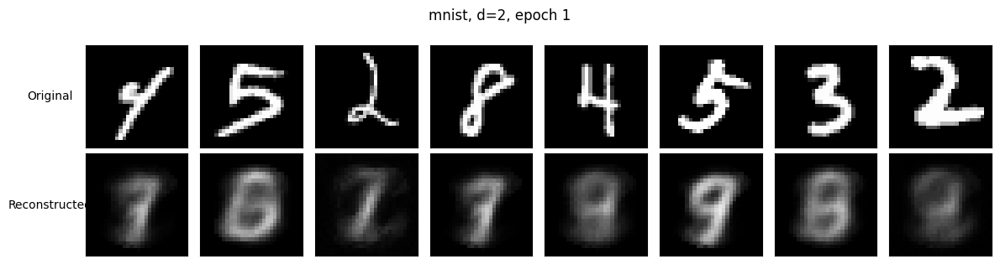

mnist | d=2 | 2/20 | train MSE 0.051515, val MSE 0.049442 | 0.7s
mnist | d=2 | 3/20 | train MSE 0.048122, val MSE 0.046581 | 0.8s
mnist | d=2 | 4/20 | train MSE 0.045466, val MSE 0.044544 | 0.8s
mnist | d=2 | 5/20 | train MSE 0.043802, val MSE 0.043311 | 0.8s
mnist | d=2 | 6/20 | train MSE 0.042736, val MSE 0.042530 | 0.8s
mnist | d=2 | 7/20 | train MSE 0.041960, val MSE 0.041913 | 0.8s
mnist | d=2 | 8/20 | train MSE 0.041328, val MSE 0.041595 | 0.8s
mnist | d=2 | 9/20 | train MSE 0.040828, val MSE 0.041044 | 0.8s
mnist | d=2 | 10/20 | train MSE 0.040426, val MSE 0.040738 | 0.8s


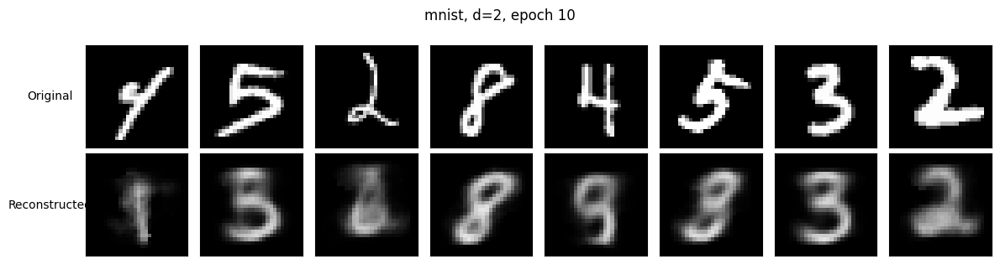

mnist | d=2 | 11/20 | train MSE 0.040036, val MSE 0.040485 | 0.8s
mnist | d=2 | 12/20 | train MSE 0.039714, val MSE 0.040184 | 0.8s
mnist | d=2 | 13/20 | train MSE 0.039424, val MSE 0.039967 | 0.8s
mnist | d=2 | 14/20 | train MSE 0.039198, val MSE 0.039720 | 0.8s
mnist | d=2 | 15/20 | train MSE 0.038898, val MSE 0.039568 | 0.8s
mnist | d=2 | 16/20 | train MSE 0.038647, val MSE 0.039248 | 0.8s
mnist | d=2 | 17/20 | train MSE 0.038457, val MSE 0.039298 | 0.8s
mnist | d=2 | 18/20 | train MSE 0.038256, val MSE 0.039140 | 0.8s
mnist | d=2 | 19/20 | train MSE 0.038094, val MSE 0.039027 | 0.8s
mnist | d=2 | 20/20 | train MSE 0.037907, val MSE 0.039003 | 0.8s


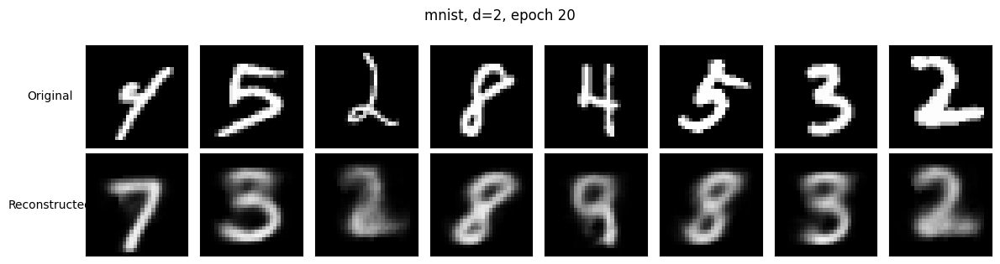

mnist | d=8 | 1/20 | train MSE 0.070035, val MSE 0.045628 | 0.7s


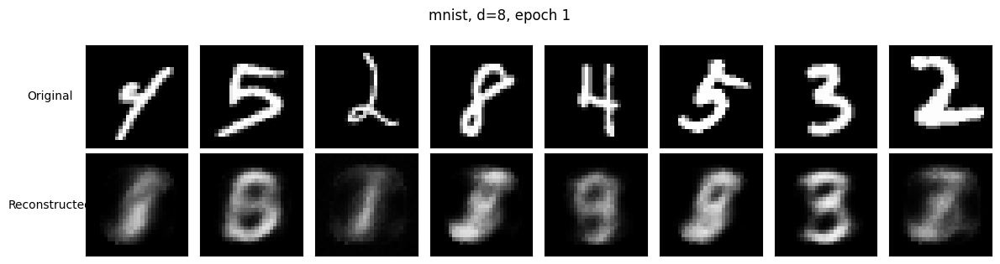

mnist | d=8 | 2/20 | train MSE 0.036047, val MSE 0.030801 | 0.8s
mnist | d=8 | 3/20 | train MSE 0.028565, val MSE 0.027004 | 0.8s
mnist | d=8 | 4/20 | train MSE 0.026069, val MSE 0.025436 | 0.8s
mnist | d=8 | 5/20 | train MSE 0.024618, val MSE 0.024130 | 0.8s
mnist | d=8 | 6/20 | train MSE 0.023634, val MSE 0.023370 | 0.8s
mnist | d=8 | 7/20 | train MSE 0.022797, val MSE 0.022607 | 0.7s
mnist | d=8 | 8/20 | train MSE 0.022092, val MSE 0.022054 | 0.8s
mnist | d=8 | 9/20 | train MSE 0.021520, val MSE 0.021537 | 0.7s
mnist | d=8 | 10/20 | train MSE 0.021038, val MSE 0.021268 | 0.8s


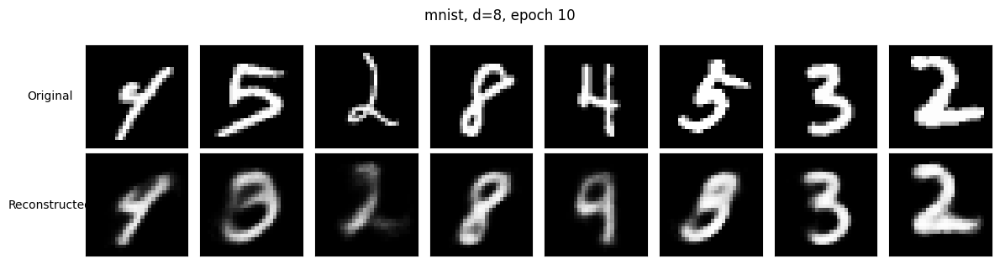

mnist | d=8 | 11/20 | train MSE 0.020621, val MSE 0.020783 | 0.8s
mnist | d=8 | 12/20 | train MSE 0.020294, val MSE 0.020495 | 0.8s
mnist | d=8 | 13/20 | train MSE 0.019946, val MSE 0.020309 | 0.8s
mnist | d=8 | 14/20 | train MSE 0.019679, val MSE 0.020017 | 0.8s
mnist | d=8 | 15/20 | train MSE 0.019390, val MSE 0.019763 | 0.8s
mnist | d=8 | 16/20 | train MSE 0.019169, val MSE 0.019650 | 0.8s
mnist | d=8 | 17/20 | train MSE 0.018971, val MSE 0.019436 | 0.8s
mnist | d=8 | 18/20 | train MSE 0.018761, val MSE 0.019297 | 0.8s
mnist | d=8 | 19/20 | train MSE 0.018571, val MSE 0.019073 | 0.8s
mnist | d=8 | 20/20 | train MSE 0.018389, val MSE 0.018873 | 0.8s


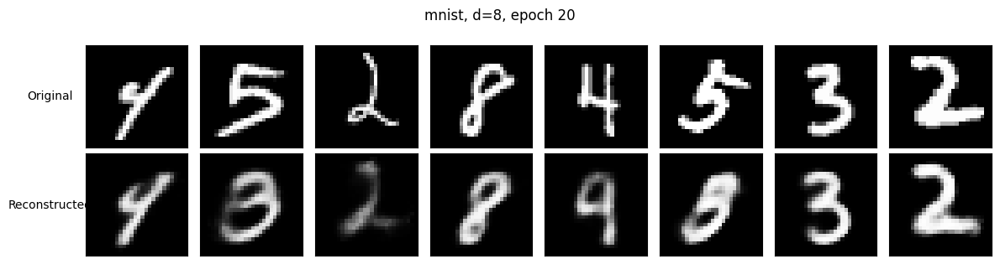

mnist | d=16 | 1/20 | train MSE 0.069570, val MSE 0.043283 | 0.8s


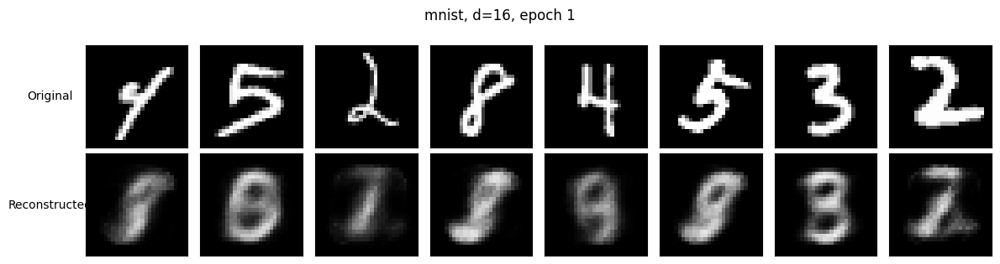

mnist | d=16 | 2/20 | train MSE 0.035521, val MSE 0.030345 | 0.8s
mnist | d=16 | 3/20 | train MSE 0.027828, val MSE 0.025648 | 0.8s
mnist | d=16 | 4/20 | train MSE 0.024146, val MSE 0.022942 | 0.7s
mnist | d=16 | 5/20 | train MSE 0.021828, val MSE 0.020935 | 0.8s
mnist | d=16 | 6/20 | train MSE 0.019590, val MSE 0.018686 | 0.8s
mnist | d=16 | 7/20 | train MSE 0.017648, val MSE 0.017093 | 0.7s
mnist | d=16 | 8/20 | train MSE 0.016503, val MSE 0.016277 | 0.8s
mnist | d=16 | 9/20 | train MSE 0.015749, val MSE 0.015723 | 0.7s
mnist | d=16 | 10/20 | train MSE 0.015098, val MSE 0.015090 | 0.7s


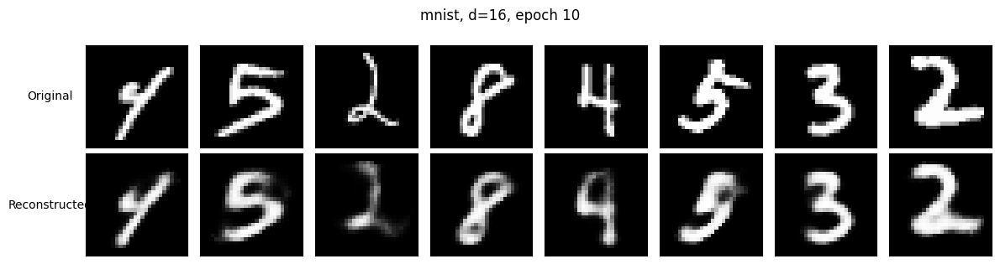

mnist | d=16 | 11/20 | train MSE 0.014523, val MSE 0.014620 | 0.8s
mnist | d=16 | 12/20 | train MSE 0.014036, val MSE 0.014052 | 0.8s
mnist | d=16 | 13/20 | train MSE 0.013575, val MSE 0.013879 | 0.8s
mnist | d=16 | 14/20 | train MSE 0.013219, val MSE 0.013315 | 0.8s
mnist | d=16 | 15/20 | train MSE 0.012880, val MSE 0.013063 | 0.8s
mnist | d=16 | 16/20 | train MSE 0.012627, val MSE 0.012842 | 0.8s
mnist | d=16 | 17/20 | train MSE 0.012376, val MSE 0.012645 | 0.7s
mnist | d=16 | 18/20 | train MSE 0.012150, val MSE 0.012413 | 0.8s
mnist | d=16 | 19/20 | train MSE 0.011956, val MSE 0.012240 | 0.8s
mnist | d=16 | 20/20 | train MSE 0.011778, val MSE 0.012048 | 0.8s


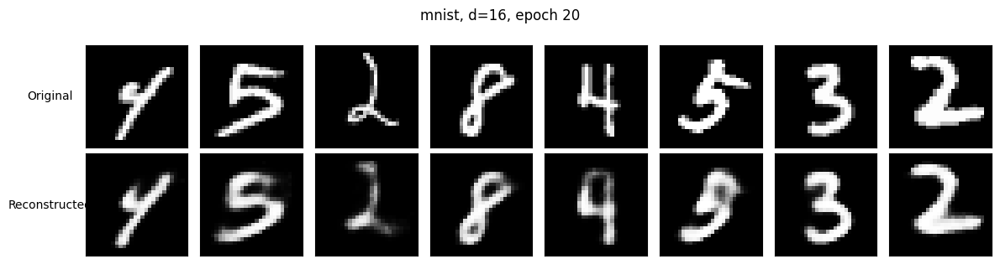

mnist | d=32 | 1/20 | train MSE 0.070272, val MSE 0.042840 | 0.8s


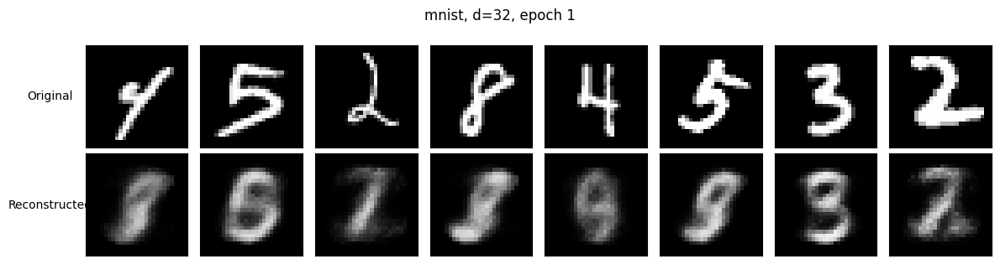

mnist | d=32 | 2/20 | train MSE 0.034691, val MSE 0.030070 | 0.8s
mnist | d=32 | 3/20 | train MSE 0.027306, val MSE 0.024679 | 0.8s
mnist | d=32 | 4/20 | train MSE 0.022931, val MSE 0.021628 | 0.8s
mnist | d=32 | 5/20 | train MSE 0.020138, val MSE 0.018950 | 0.8s
mnist | d=32 | 6/20 | train MSE 0.017845, val MSE 0.017109 | 0.7s
mnist | d=32 | 7/20 | train MSE 0.016342, val MSE 0.015950 | 0.8s
mnist | d=32 | 8/20 | train MSE 0.015306, val MSE 0.014924 | 0.8s
mnist | d=32 | 9/20 | train MSE 0.014263, val MSE 0.014087 | 0.8s
mnist | d=32 | 10/20 | train MSE 0.013373, val MSE 0.013268 | 0.8s


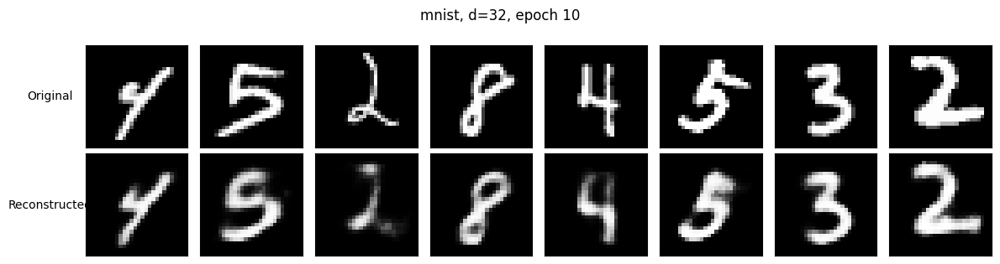

mnist | d=32 | 11/20 | train MSE 0.012659, val MSE 0.012800 | 0.8s
mnist | d=32 | 12/20 | train MSE 0.012062, val MSE 0.011918 | 0.8s
mnist | d=32 | 13/20 | train MSE 0.011517, val MSE 0.011598 | 0.8s
mnist | d=32 | 14/20 | train MSE 0.011090, val MSE 0.011131 | 0.8s
mnist | d=32 | 15/20 | train MSE 0.010692, val MSE 0.010826 | 0.8s
mnist | d=32 | 16/20 | train MSE 0.010353, val MSE 0.010442 | 0.8s
mnist | d=32 | 17/20 | train MSE 0.010039, val MSE 0.010304 | 0.8s
mnist | d=32 | 18/20 | train MSE 0.009772, val MSE 0.009915 | 0.8s
mnist | d=32 | 19/20 | train MSE 0.009501, val MSE 0.009620 | 0.7s
mnist | d=32 | 20/20 | train MSE 0.009248, val MSE 0.009366 | 0.8s


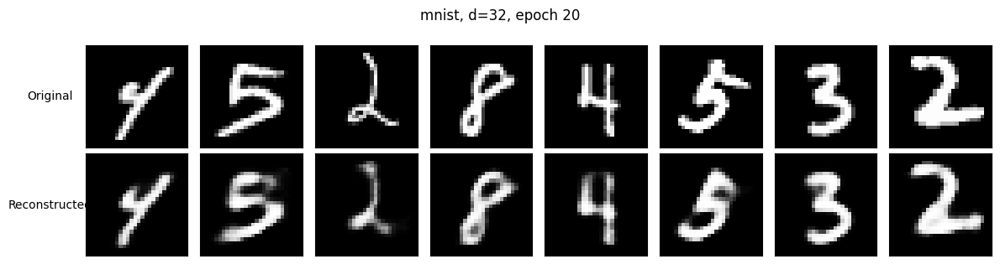

mnist | d=64 | 1/20 | train MSE 0.072570, val MSE 0.047084 | 0.8s


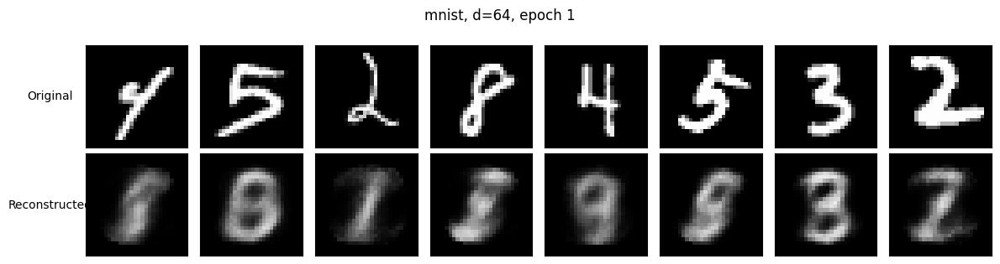

mnist | d=64 | 2/20 | train MSE 0.036264, val MSE 0.029921 | 0.8s
mnist | d=64 | 3/20 | train MSE 0.026571, val MSE 0.024251 | 0.7s
mnist | d=64 | 4/20 | train MSE 0.022639, val MSE 0.021439 | 0.7s
mnist | d=64 | 5/20 | train MSE 0.019856, val MSE 0.018670 | 0.8s
mnist | d=64 | 6/20 | train MSE 0.017700, val MSE 0.017045 | 0.7s
mnist | d=64 | 7/20 | train MSE 0.016237, val MSE 0.015899 | 0.7s
mnist | d=64 | 8/20 | train MSE 0.015064, val MSE 0.014721 | 0.7s
mnist | d=64 | 9/20 | train MSE 0.014140, val MSE 0.014065 | 0.7s
mnist | d=64 | 10/20 | train MSE 0.013197, val MSE 0.012960 | 0.8s


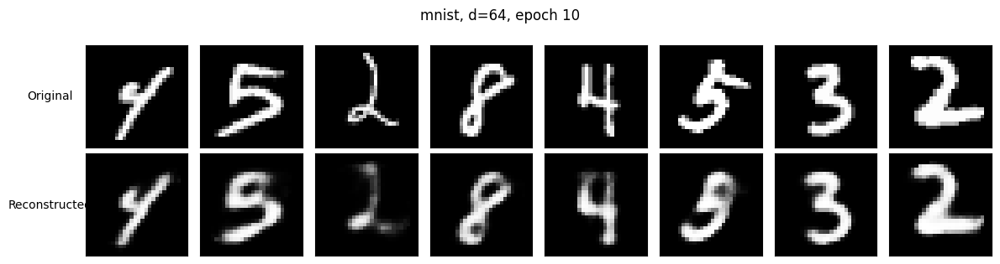

mnist | d=64 | 11/20 | train MSE 0.012408, val MSE 0.012402 | 0.8s
mnist | d=64 | 12/20 | train MSE 0.011801, val MSE 0.011862 | 0.8s
mnist | d=64 | 13/20 | train MSE 0.011260, val MSE 0.011493 | 0.8s
mnist | d=64 | 14/20 | train MSE 0.010787, val MSE 0.010749 | 0.8s
mnist | d=64 | 15/20 | train MSE 0.010320, val MSE 0.010380 | 0.8s
mnist | d=64 | 16/20 | train MSE 0.009937, val MSE 0.010050 | 0.7s
mnist | d=64 | 17/20 | train MSE 0.009584, val MSE 0.009743 | 0.8s
mnist | d=64 | 18/20 | train MSE 0.009257, val MSE 0.009374 | 0.8s
mnist | d=64 | 19/20 | train MSE 0.009013, val MSE 0.009200 | 0.8s
mnist | d=64 | 20/20 | train MSE 0.008760, val MSE 0.008928 | 0.8s


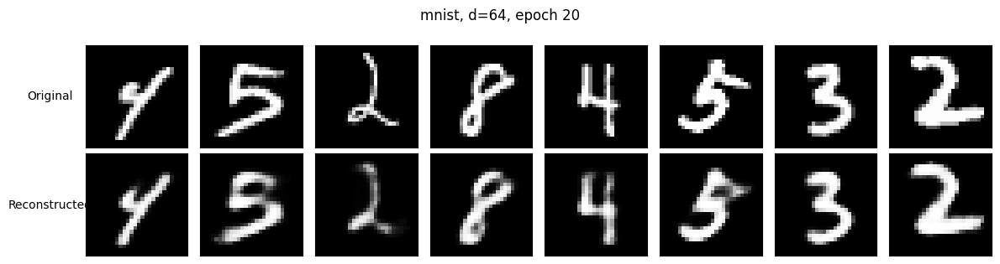

mnist | d=128 | 1/20 | train MSE 0.070490, val MSE 0.042627 | 0.8s


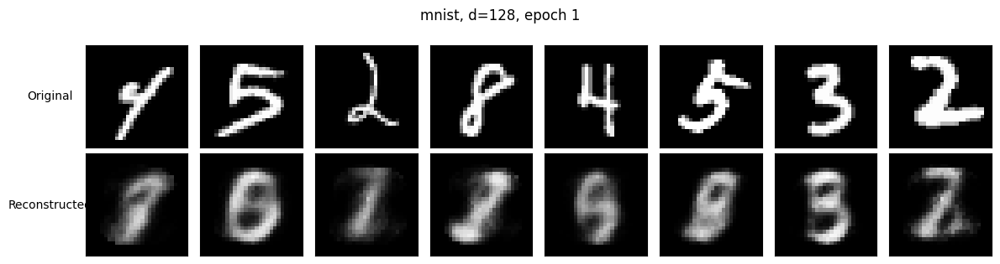

mnist | d=128 | 2/20 | train MSE 0.034036, val MSE 0.028590 | 0.8s
mnist | d=128 | 3/20 | train MSE 0.025787, val MSE 0.023662 | 0.7s
mnist | d=128 | 4/20 | train MSE 0.022015, val MSE 0.020708 | 0.7s
mnist | d=128 | 5/20 | train MSE 0.019216, val MSE 0.018129 | 0.8s
mnist | d=128 | 6/20 | train MSE 0.016881, val MSE 0.016242 | 0.7s
mnist | d=128 | 7/20 | train MSE 0.015226, val MSE 0.014702 | 0.7s
mnist | d=128 | 8/20 | train MSE 0.013961, val MSE 0.013690 | 0.7s
mnist | d=128 | 9/20 | train MSE 0.012998, val MSE 0.012883 | 0.8s
mnist | d=128 | 10/20 | train MSE 0.012151, val MSE 0.012250 | 0.7s


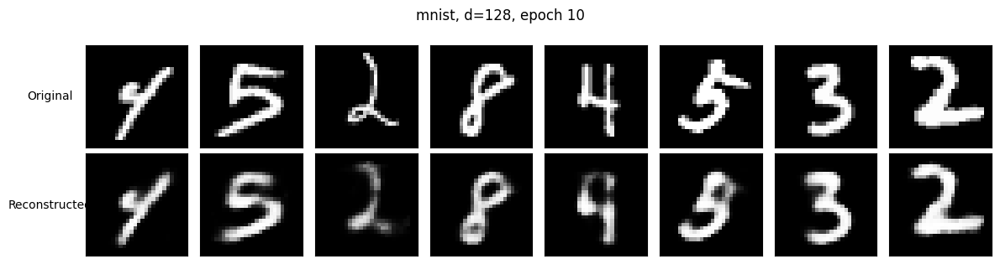

mnist | d=128 | 11/20 | train MSE 0.011448, val MSE 0.011395 | 0.7s
mnist | d=128 | 12/20 | train MSE 0.010826, val MSE 0.010809 | 0.7s
mnist | d=128 | 13/20 | train MSE 0.010268, val MSE 0.010357 | 0.7s
mnist | d=128 | 14/20 | train MSE 0.009735, val MSE 0.009926 | 0.8s
mnist | d=128 | 15/20 | train MSE 0.009335, val MSE 0.009480 | 0.8s
mnist | d=128 | 16/20 | train MSE 0.008946, val MSE 0.008955 | 0.8s
mnist | d=128 | 17/20 | train MSE 0.008618, val MSE 0.008771 | 0.7s
mnist | d=128 | 18/20 | train MSE 0.008315, val MSE 0.008495 | 0.8s
mnist | d=128 | 19/20 | train MSE 0.008040, val MSE 0.008377 | 0.7s
mnist | d=128 | 20/20 | train MSE 0.007795, val MSE 0.007940 | 0.7s


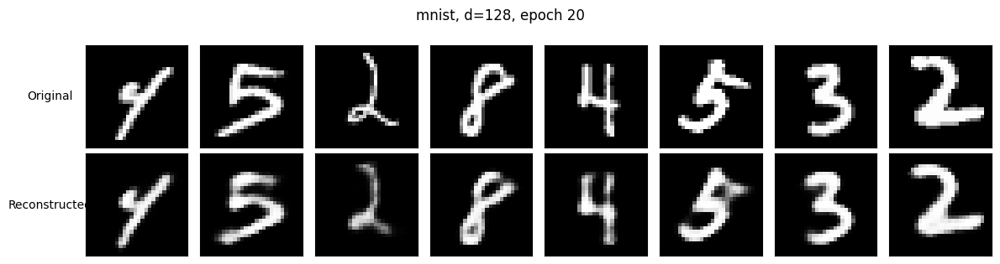

fashion_mnist | d=2 | 1/20 | train MSE 0.057709, val MSE 0.037969 | 0.8s


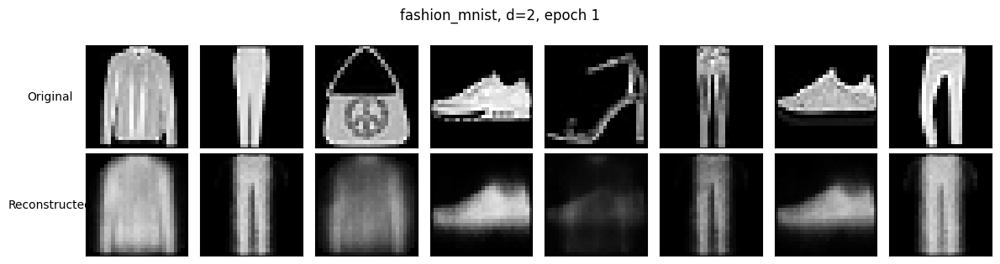

fashion_mnist | d=2 | 2/20 | train MSE 0.035344, val MSE 0.034206 | 0.8s
fashion_mnist | d=2 | 3/20 | train MSE 0.033168, val MSE 0.032495 | 0.8s
fashion_mnist | d=2 | 4/20 | train MSE 0.031871, val MSE 0.031619 | 0.8s
fashion_mnist | d=2 | 5/20 | train MSE 0.031023, val MSE 0.030736 | 0.8s
fashion_mnist | d=2 | 6/20 | train MSE 0.030282, val MSE 0.030142 | 0.7s
fashion_mnist | d=2 | 7/20 | train MSE 0.029723, val MSE 0.029778 | 0.8s
fashion_mnist | d=2 | 8/20 | train MSE 0.029430, val MSE 0.029304 | 0.8s
fashion_mnist | d=2 | 9/20 | train MSE 0.028982, val MSE 0.029040 | 0.8s
fashion_mnist | d=2 | 10/20 | train MSE 0.028766, val MSE 0.028687 | 0.8s


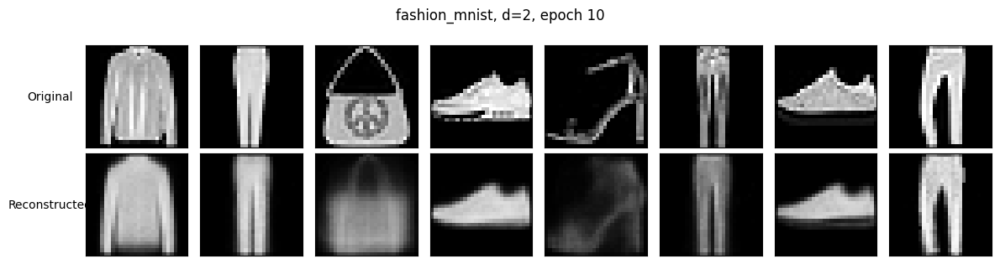

fashion_mnist | d=2 | 11/20 | train MSE 0.028460, val MSE 0.028618 | 0.8s
fashion_mnist | d=2 | 12/20 | train MSE 0.028301, val MSE 0.028443 | 0.8s
fashion_mnist | d=2 | 13/20 | train MSE 0.027998, val MSE 0.027875 | 0.8s
fashion_mnist | d=2 | 14/20 | train MSE 0.027726, val MSE 0.027907 | 0.8s
fashion_mnist | d=2 | 15/20 | train MSE 0.027613, val MSE 0.027615 | 0.7s
fashion_mnist | d=2 | 16/20 | train MSE 0.027486, val MSE 0.027491 | 0.8s
fashion_mnist | d=2 | 17/20 | train MSE 0.027274, val MSE 0.028091 | 0.8s
fashion_mnist | d=2 | 18/20 | train MSE 0.027175, val MSE 0.027270 | 0.8s
fashion_mnist | d=2 | 19/20 | train MSE 0.026998, val MSE 0.027085 | 0.8s
fashion_mnist | d=2 | 20/20 | train MSE 0.026786, val MSE 0.026953 | 0.7s


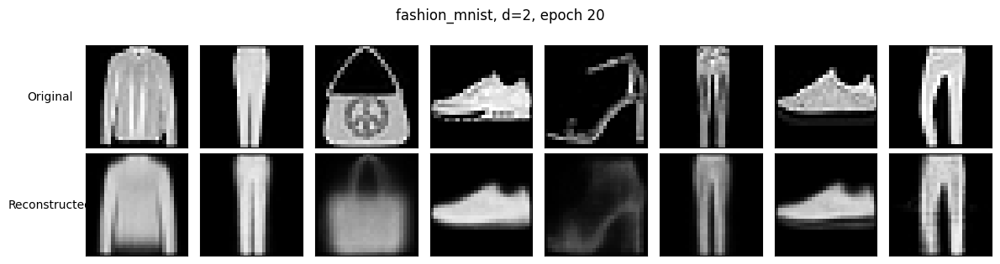

fashion_mnist | d=8 | 1/20 | train MSE 0.052345, val MSE 0.029796 | 0.8s


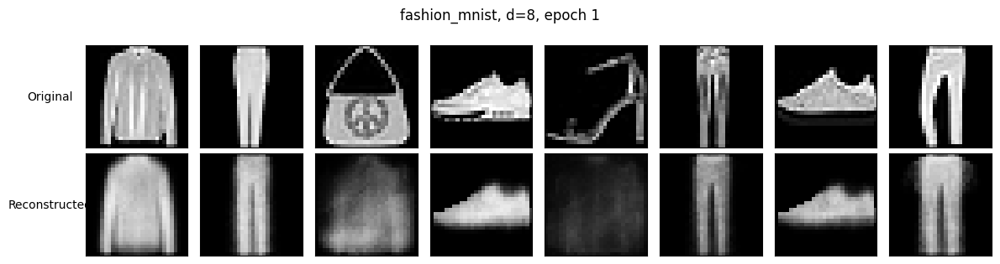

fashion_mnist | d=8 | 2/20 | train MSE 0.025024, val MSE 0.022744 | 0.8s
fashion_mnist | d=8 | 3/20 | train MSE 0.021410, val MSE 0.020890 | 0.7s
fashion_mnist | d=8 | 4/20 | train MSE 0.019832, val MSE 0.019417 | 0.8s
fashion_mnist | d=8 | 5/20 | train MSE 0.018713, val MSE 0.018474 | 0.8s
fashion_mnist | d=8 | 6/20 | train MSE 0.017961, val MSE 0.017865 | 0.8s
fashion_mnist | d=8 | 7/20 | train MSE 0.017299, val MSE 0.017341 | 0.7s
fashion_mnist | d=8 | 8/20 | train MSE 0.016747, val MSE 0.016668 | 0.7s
fashion_mnist | d=8 | 9/20 | train MSE 0.016326, val MSE 0.016389 | 0.8s
fashion_mnist | d=8 | 10/20 | train MSE 0.015993, val MSE 0.016085 | 0.8s


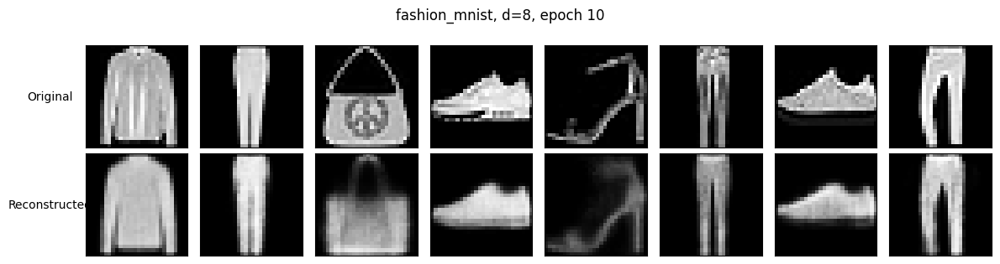

fashion_mnist | d=8 | 11/20 | train MSE 0.015744, val MSE 0.015905 | 0.8s
fashion_mnist | d=8 | 12/20 | train MSE 0.015517, val MSE 0.015706 | 0.8s
fashion_mnist | d=8 | 13/20 | train MSE 0.015321, val MSE 0.015420 | 0.7s
fashion_mnist | d=8 | 14/20 | train MSE 0.015140, val MSE 0.015391 | 0.8s
fashion_mnist | d=8 | 15/20 | train MSE 0.014994, val MSE 0.015171 | 0.8s
fashion_mnist | d=8 | 16/20 | train MSE 0.014841, val MSE 0.015052 | 0.7s
fashion_mnist | d=8 | 17/20 | train MSE 0.014711, val MSE 0.014902 | 0.7s
fashion_mnist | d=8 | 18/20 | train MSE 0.014619, val MSE 0.014894 | 0.7s
fashion_mnist | d=8 | 19/20 | train MSE 0.014503, val MSE 0.014718 | 0.7s
fashion_mnist | d=8 | 20/20 | train MSE 0.014393, val MSE 0.014669 | 0.7s


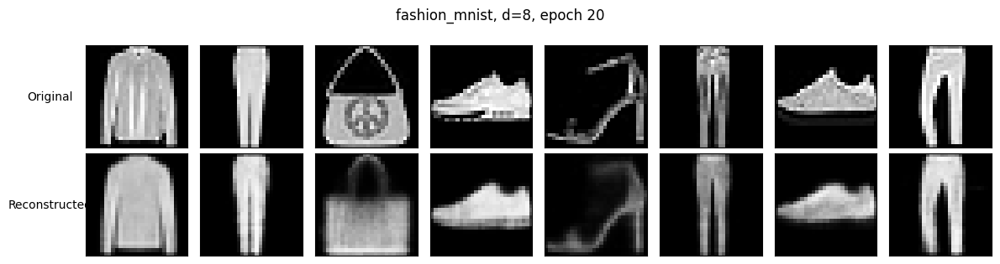

fashion_mnist | d=16 | 1/20 | train MSE 0.052187, val MSE 0.029867 | 0.7s


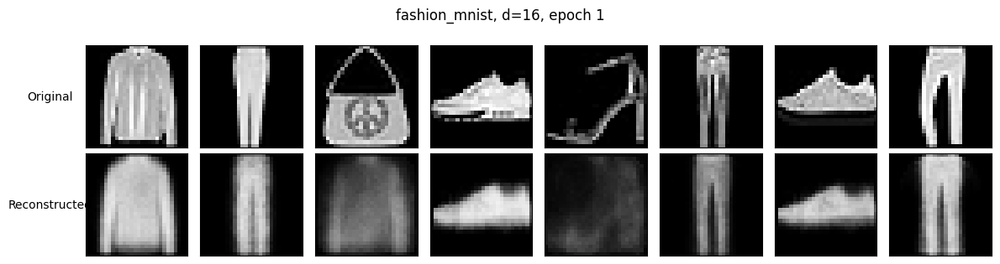

fashion_mnist | d=16 | 2/20 | train MSE 0.024711, val MSE 0.022294 | 0.8s
fashion_mnist | d=16 | 3/20 | train MSE 0.020900, val MSE 0.020053 | 0.8s
fashion_mnist | d=16 | 4/20 | train MSE 0.019080, val MSE 0.018675 | 0.9s
fashion_mnist | d=16 | 5/20 | train MSE 0.017909, val MSE 0.018029 | 0.9s
fashion_mnist | d=16 | 6/20 | train MSE 0.017148, val MSE 0.016969 | 0.9s
fashion_mnist | d=16 | 7/20 | train MSE 0.016480, val MSE 0.016347 | 1.1s
fashion_mnist | d=16 | 8/20 | train MSE 0.015851, val MSE 0.015739 | 1.0s
fashion_mnist | d=16 | 9/20 | train MSE 0.015370, val MSE 0.015426 | 1.0s
fashion_mnist | d=16 | 10/20 | train MSE 0.014968, val MSE 0.014943 | 0.9s


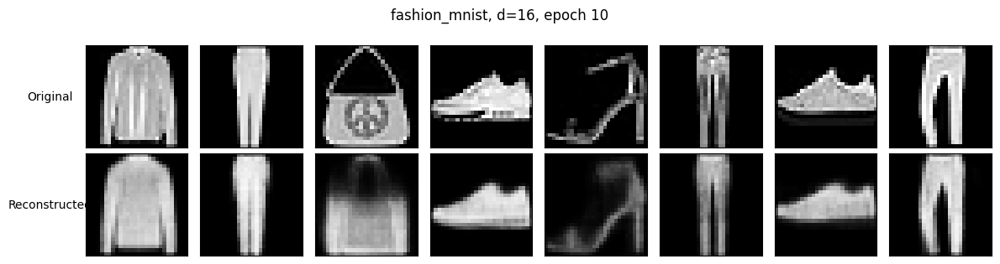

fashion_mnist | d=16 | 11/20 | train MSE 0.014586, val MSE 0.014678 | 0.9s
fashion_mnist | d=16 | 12/20 | train MSE 0.014212, val MSE 0.014299 | 1.0s
fashion_mnist | d=16 | 13/20 | train MSE 0.013878, val MSE 0.014412 | 0.8s
fashion_mnist | d=16 | 14/20 | train MSE 0.013582, val MSE 0.013707 | 0.9s
fashion_mnist | d=16 | 15/20 | train MSE 0.013294, val MSE 0.013469 | 0.8s
fashion_mnist | d=16 | 16/20 | train MSE 0.013057, val MSE 0.013165 | 0.8s
fashion_mnist | d=16 | 17/20 | train MSE 0.012865, val MSE 0.012943 | 0.8s
fashion_mnist | d=16 | 18/20 | train MSE 0.012627, val MSE 0.012734 | 0.8s
fashion_mnist | d=16 | 19/20 | train MSE 0.012481, val MSE 0.012754 | 0.8s
fashion_mnist | d=16 | 20/20 | train MSE 0.012346, val MSE 0.012693 | 0.8s


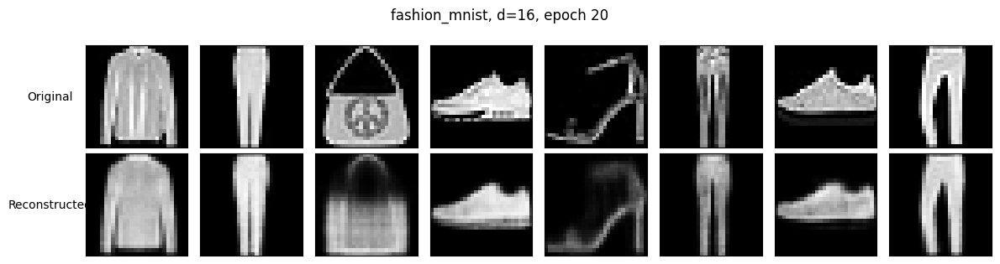

fashion_mnist | d=32 | 1/20 | train MSE 0.053525, val MSE 0.029108 | 0.9s


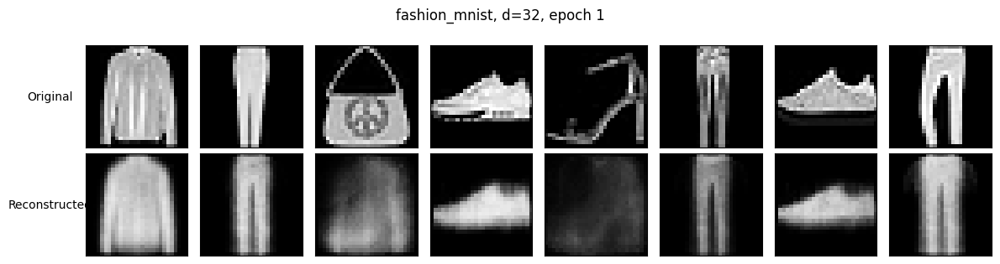

fashion_mnist | d=32 | 2/20 | train MSE 0.024880, val MSE 0.022816 | 0.8s
fashion_mnist | d=32 | 3/20 | train MSE 0.021425, val MSE 0.020255 | 0.8s
fashion_mnist | d=32 | 4/20 | train MSE 0.019257, val MSE 0.018745 | 0.8s
fashion_mnist | d=32 | 5/20 | train MSE 0.018118, val MSE 0.017811 | 0.8s
fashion_mnist | d=32 | 6/20 | train MSE 0.017177, val MSE 0.016836 | 0.8s
fashion_mnist | d=32 | 7/20 | train MSE 0.016332, val MSE 0.016151 | 0.8s
fashion_mnist | d=32 | 8/20 | train MSE 0.015704, val MSE 0.015540 | 0.8s
fashion_mnist | d=32 | 9/20 | train MSE 0.015078, val MSE 0.015011 | 0.8s
fashion_mnist | d=32 | 10/20 | train MSE 0.014610, val MSE 0.014532 | 0.8s


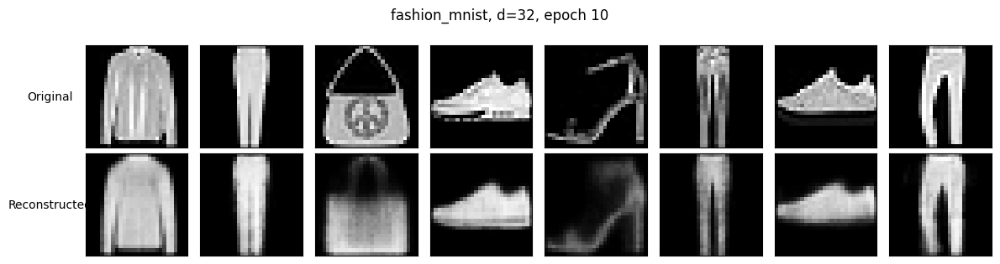

fashion_mnist | d=32 | 11/20 | train MSE 0.014216, val MSE 0.014197 | 0.8s
fashion_mnist | d=32 | 12/20 | train MSE 0.013792, val MSE 0.013766 | 0.8s
fashion_mnist | d=32 | 13/20 | train MSE 0.013487, val MSE 0.013597 | 0.8s
fashion_mnist | d=32 | 14/20 | train MSE 0.013205, val MSE 0.013349 | 0.7s
fashion_mnist | d=32 | 15/20 | train MSE 0.012940, val MSE 0.012972 | 0.8s
fashion_mnist | d=32 | 16/20 | train MSE 0.012671, val MSE 0.012754 | 0.8s
fashion_mnist | d=32 | 17/20 | train MSE 0.012460, val MSE 0.012550 | 0.8s
fashion_mnist | d=32 | 18/20 | train MSE 0.012200, val MSE 0.012437 | 0.8s
fashion_mnist | d=32 | 19/20 | train MSE 0.012012, val MSE 0.012099 | 0.7s
fashion_mnist | d=32 | 20/20 | train MSE 0.011825, val MSE 0.011927 | 0.8s


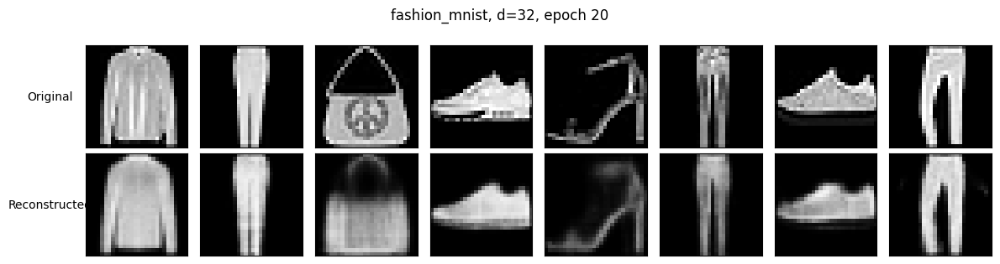

fashion_mnist | d=64 | 1/20 | train MSE 0.054260, val MSE 0.030175 | 0.8s


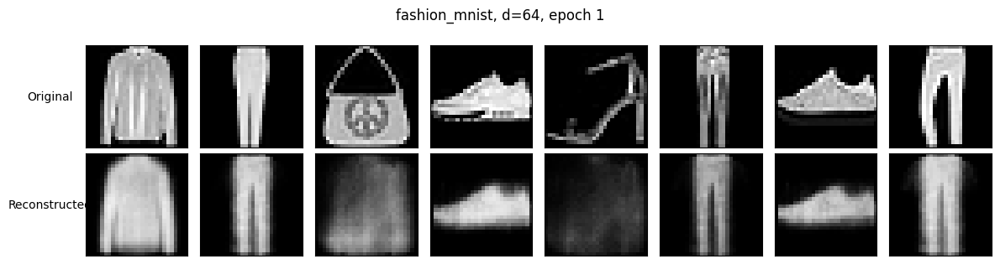

fashion_mnist | d=64 | 2/20 | train MSE 0.025804, val MSE 0.023482 | 0.7s
fashion_mnist | d=64 | 3/20 | train MSE 0.022140, val MSE 0.021240 | 0.8s
fashion_mnist | d=64 | 4/20 | train MSE 0.020003, val MSE 0.019172 | 0.7s
fashion_mnist | d=64 | 5/20 | train MSE 0.018503, val MSE 0.018425 | 0.8s
fashion_mnist | d=64 | 6/20 | train MSE 0.017545, val MSE 0.017521 | 0.7s
fashion_mnist | d=64 | 7/20 | train MSE 0.016803, val MSE 0.016580 | 0.7s
fashion_mnist | d=64 | 8/20 | train MSE 0.016085, val MSE 0.016036 | 0.8s
fashion_mnist | d=64 | 9/20 | train MSE 0.015464, val MSE 0.015278 | 0.8s
fashion_mnist | d=64 | 10/20 | train MSE 0.014879, val MSE 0.014830 | 0.8s


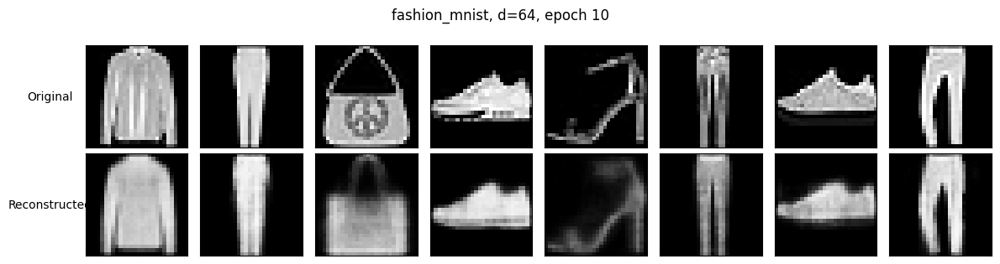

fashion_mnist | d=64 | 11/20 | train MSE 0.014370, val MSE 0.014225 | 0.8s
fashion_mnist | d=64 | 12/20 | train MSE 0.013892, val MSE 0.013858 | 0.8s
fashion_mnist | d=64 | 13/20 | train MSE 0.013470, val MSE 0.013461 | 0.8s
fashion_mnist | d=64 | 14/20 | train MSE 0.013171, val MSE 0.013150 | 0.8s
fashion_mnist | d=64 | 15/20 | train MSE 0.012859, val MSE 0.012926 | 0.8s
fashion_mnist | d=64 | 16/20 | train MSE 0.012617, val MSE 0.012766 | 0.7s
fashion_mnist | d=64 | 17/20 | train MSE 0.012363, val MSE 0.012568 | 0.8s
fashion_mnist | d=64 | 18/20 | train MSE 0.012152, val MSE 0.012282 | 0.8s
fashion_mnist | d=64 | 19/20 | train MSE 0.011980, val MSE 0.012040 | 0.7s
fashion_mnist | d=64 | 20/20 | train MSE 0.011741, val MSE 0.011949 | 0.8s


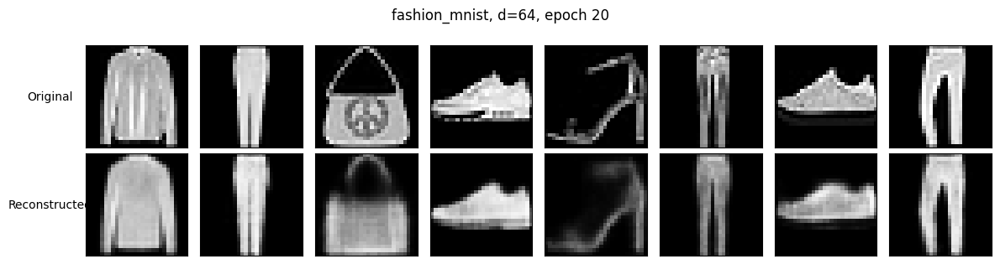

fashion_mnist | d=128 | 1/20 | train MSE 0.055735, val MSE 0.032762 | 0.8s


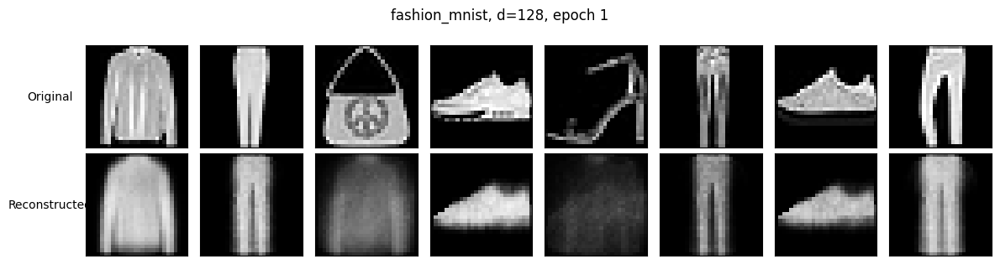

fashion_mnist | d=128 | 2/20 | train MSE 0.027012, val MSE 0.023371 | 0.8s
fashion_mnist | d=128 | 3/20 | train MSE 0.021946, val MSE 0.020909 | 0.7s
fashion_mnist | d=128 | 4/20 | train MSE 0.019758, val MSE 0.019003 | 0.8s
fashion_mnist | d=128 | 5/20 | train MSE 0.018205, val MSE 0.017740 | 0.8s
fashion_mnist | d=128 | 6/20 | train MSE 0.017202, val MSE 0.017078 | 0.8s
fashion_mnist | d=128 | 7/20 | train MSE 0.016380, val MSE 0.016432 | 0.8s
fashion_mnist | d=128 | 8/20 | train MSE 0.015768, val MSE 0.015544 | 0.7s
fashion_mnist | d=128 | 9/20 | train MSE 0.015105, val MSE 0.015023 | 0.7s
fashion_mnist | d=128 | 10/20 | train MSE 0.014628, val MSE 0.014634 | 0.7s


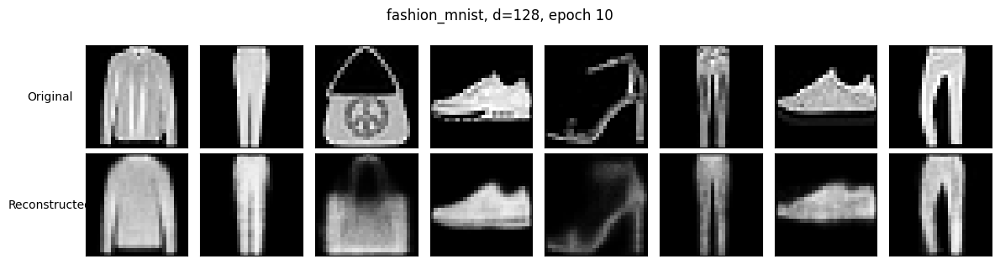

fashion_mnist | d=128 | 11/20 | train MSE 0.014188, val MSE 0.014109 | 0.7s
fashion_mnist | d=128 | 12/20 | train MSE 0.013730, val MSE 0.013737 | 0.8s
fashion_mnist | d=128 | 13/20 | train MSE 0.013350, val MSE 0.013442 | 0.7s
fashion_mnist | d=128 | 14/20 | train MSE 0.013032, val MSE 0.013045 | 0.8s
fashion_mnist | d=128 | 15/20 | train MSE 0.012732, val MSE 0.012891 | 0.8s
fashion_mnist | d=128 | 16/20 | train MSE 0.012447, val MSE 0.012549 | 0.8s
fashion_mnist | d=128 | 17/20 | train MSE 0.012217, val MSE 0.012404 | 0.8s
fashion_mnist | d=128 | 18/20 | train MSE 0.011970, val MSE 0.012153 | 0.8s
fashion_mnist | d=128 | 19/20 | train MSE 0.011801, val MSE 0.012029 | 0.8s
fashion_mnist | d=128 | 20/20 | train MSE 0.011635, val MSE 0.011746 | 0.7s


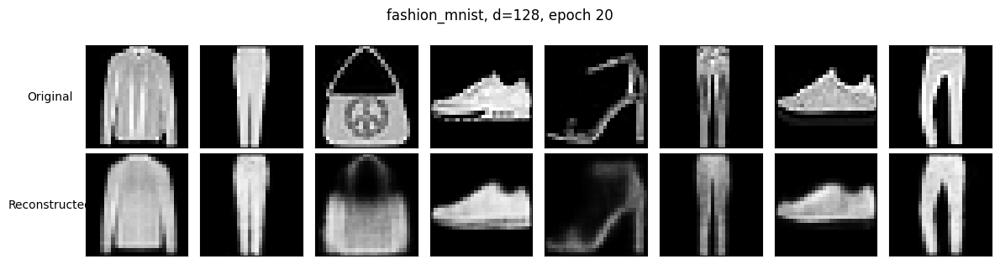

,dataset,latent_dim,val_mse,best_epoch,parameters,dimension_ratio,float32_code_bytes,raw_uint8_to_code_byte_ratio,seconds
0,mnist,2,0.039003,20,469010,392.000,8,98.00000,15.818454
1,mnist,8,0.018873,20,470552,98.000,32,24.50000,15.344352
2,mnist,16,0.012048,20,472608,49.000,64,12.25000,15.284106
3,mnist,32,0.009366,20,476720,24.500,128,6.12500,15.377221
4,mnist,64,0.008928,20,484944,12.250,256,3.06250,15.116013
5,mnist,128,0.007940,20,501392,6.125,512,1.53125,15.045305
6,fashion_mnist,2,0.026953,20,469010,392.000,8,98.00000,15.519883
7,fashion_mnist,8,0.014669,20,470552,98.000,32,24.50000,15.147511
8,fashion_mnist,16,0.012693,20,472608,49.000,64,12.25000,17.282985
9,fashion_mnist,32,0.011927,20,476720,24.500,128,6.12500,15.825163


In [28]:
def metrics(squared,absolute,count):
    mse=squared/count
    return dict(mse=mse,mae=absolute/count,psnr_db=10*math.log10(1/max(mse,1e-12)))
@torch.no_grad()
def evaluate(model,loader):
    model.eval()
    squared,absolute,count=0.,0.,0
    for x,_ in loader:
        x=x.to(DEVICE)
        delta=model(x)-x
        squared+=delta.square().flatten(1).mean(1).sum().item()
        absolute+=delta.abs().flatten(1).mean(1).sum().item()
        count+=len(x)
    return metrics(squared,absolute,count)

def reconstruction_panel(rows,title,path):
    fig,axes=plt.subplots(len(rows),8,figsize=(12,1.6*len(rows)),squeeze=False)
    for index,(label,images) in enumerate(rows):
        for ax,image in zip(axes[index],images):
            ax.imshow(image.detach().cpu().squeeze(),cmap='gray',vmin=0,vmax=1)
            ax.set_xticks([])
            ax.set_yticks([])
        axes[index,0].set_ylabel(label,rotation=0,labelpad=30,va='center')
    fig.suptitle(('SMOKE TEST | ' if SMOKE_TEST else '')+title)
    fig.tight_layout()
    fig.savefig(path,dpi=130,bbox_inches='tight')
    plt.show()
    plt.close(fig)

def train_autoencoder(dataset,latent_dim):
    seed_all()
    train,val=training_loaders(dataset)
    model=Autoencoder(latent_dim).to(DEVICE)
    seed_all()
    optimizer=torch.optim.Adam(model.parameters(),lr=LEARNING_RATE)
    folder=RESULTS/dataset/f'latent_{latent_dim}'
    folder.mkdir(parents=True,exist_ok=True)
    checkpoint=CHECKPOINTS/f'{dataset}_latent_{latent_dim}.pt'
    epochs=2 if SMOKE_TEST else EPOCHS
    metadata=dict(dataset=dataset,latent_dim=latent_dim,epochs=epochs,seed=SEED,
                  batch_size=BATCH_SIZE,learning_rate=LEARNING_RATE,loss='MSE',
                  train_size=len(train.dataset),validation_size=len(val.dataset),
                  parameters=sum(p.numel() for p in model.parameters()),smoke_test=SMOKE_TEST)
    (folder/'config.json').write_text(json.dumps(metadata,indent=2))
    examples=next(iter(val))[0][:8]
    best,history=float('inf'),[]
    for epoch in range(1,epochs+1):
        started=time.perf_counter()
        model.train()
        total,count=0.,0
        for x,_ in train:
            x=x.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            loss=(model(x)-x).square().mean()
            if not torch.isfinite(loss): raise FloatingPointError('Non-finite loss')
            loss.backward()
            optimizer.step()
            total+=loss.item()*len(x)
            count+=len(x)
        validation=evaluate(model,val)
        row=dict(epoch=epoch,train_mse=total/count,val_mse=validation['mse'],
                 seconds=time.perf_counter()-started)
        history.append(row)
        pd.DataFrame(history).to_csv(folder/'history.csv',index=False)
        if validation['mse']<best:
            best=validation['mse']
            torch.save(dict(model=model.state_dict(),latent_dim=latent_dim,epoch=epoch),checkpoint)
        print(f'{dataset} | d={latent_dim} | {epoch}/{epochs} | train MSE {row["train_mse"]:.6f}, val MSE {row["val_mse"]:.6f} | {row["seconds"]:.1f}s',flush=True)
        if epoch==1 or epoch%10==0 or epoch==epochs:
            model.eval()
            with torch.no_grad(): predictions=model(examples.to(DEVICE)).cpu()
            reconstruction_panel([('Original',examples),('Reconstructed',predictions)],
                                 f'{dataset}, d={latent_dim}, epoch {epoch}',folder/f'epoch_{epoch:03d}.png')
    saved=torch.load(checkpoint,map_location=DEVICE,weights_only=True)
    return dict(dataset=dataset,latent_dim=latent_dim,val_mse=best,best_epoch=saved['epoch'],
                parameters=metadata['parameters'],dimension_ratio=784/latent_dim,float32_code_bytes=4*latent_dim,
                raw_uint8_to_code_byte_ratio=784/(4*latent_dim),seconds=sum(r['seconds'] for r in history),
                checkpoint=str(checkpoint))

runs=[]
for dataset in DATASET_NAMES:
    for latent_dim in LATENT_SIZES:
        runs.append(train_autoencoder(dataset,latent_dim))
        pd.DataFrame([{k:v for k,v in r.items() if k!='checkpoint'} for r in runs]).to_csv(RESULTS/'validation_comparison.csv',index=False)
display(pd.DataFrame([{k:v for k,v in r.items() if k!='checkpoint'} for r in runs]))


## 4. Test reconstruction metrics

Every validation-selected checkpoint was evaluated on the test set. A constant mean-image predictor, fitted only on training images, provided a simple reference. The test sweep describes performance across sizes; model selection used validation MSE.


In [29]:
test_rows=[]
for dataset in DATASET_NAMES:
    train,_=training_loaders(dataset)
    image_sum,count=torch.zeros(1,1,28,28),0
    for x,_ in train:
        image_sum+=x.sum(0,keepdim=True)
        count+=len(x)
    mean_image=image_sum/count
    squared,absolute,count=0.,0.,0
    for x,_ in testing_loader(dataset):
        delta=x-mean_image
        squared+=delta.square().flatten(1).mean(1).sum().item()
        absolute+=delta.abs().flatten(1).mean(1).sum().item()
        count+=len(x)
    test_rows.append(dict(dataset=dataset,method='mean_image',latent_dim=0,
                          **metrics(squared,absolute,count),smoke_test=SMOKE_TEST))
    for run in (r for r in runs if r['dataset']==dataset):
        model=Autoencoder(run['latent_dim']).to(DEVICE)
        model.load_state_dict(torch.load(run['checkpoint'],map_location=DEVICE,weights_only=True)['model'])
        test_rows.append(dict(dataset=dataset,method='autoencoder',latent_dim=run['latent_dim'],
                              **evaluate(model,testing_loader(dataset)),smoke_test=SMOKE_TEST))
test_results=pd.DataFrame(test_rows)
test_results.to_csv(RESULTS/'test_results.csv',index=False)
display(test_results)


,dataset,method,latent_dim,mse,mae,psnr_db,smoke_test
0,mnist,mean_image,0,0.067470,0.150324,11.708892,False
1,mnist,autoencoder,2,0.038845,0.091319,14.106615,False
2,mnist,autoencoder,8,0.018482,0.050581,17.332574,False
3,mnist,autoencoder,16,0.011701,0.036879,19.317727,False
4,mnist,autoencoder,32,0.009069,0.031133,20.424530,False
5,mnist,autoencoder,64,0.008654,0.030271,20.627770,False
6,mnist,autoencoder,128,0.007676,0.028283,21.148559,False
7,fashion_mnist,mean_image,0,0.086642,0.231119,10.622722,False
8,fashion_mnist,autoencoder,2,0.026848,0.092773,15.710912,False
9,fashion_mnist,autoencoder,8,0.014627,0.063909,18.348540,False


## 5. Reconstruction error versus latent size

The plot compares reconstruction error across latent sizes on both datasets. Larger latent spaces generally reduced error, with smaller gains at higher sizes. The trend was not strictly monotonic for every Fashion-MNIST model.


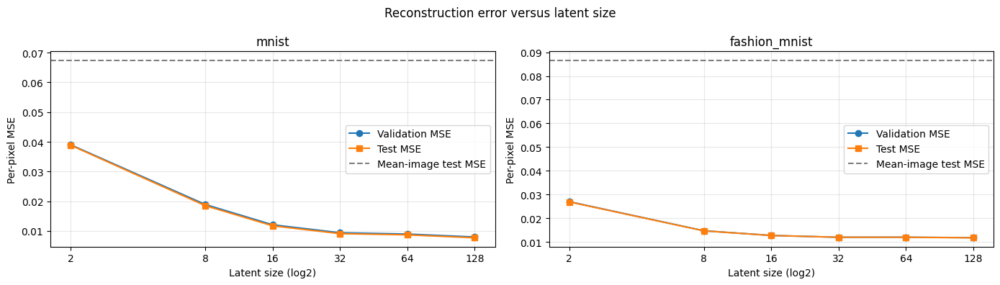

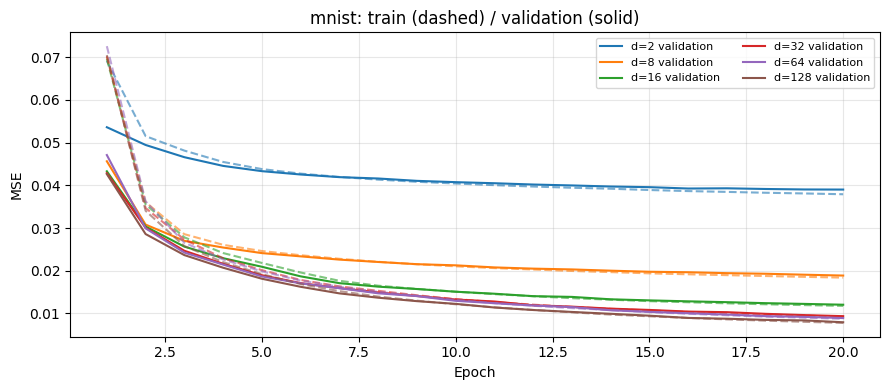

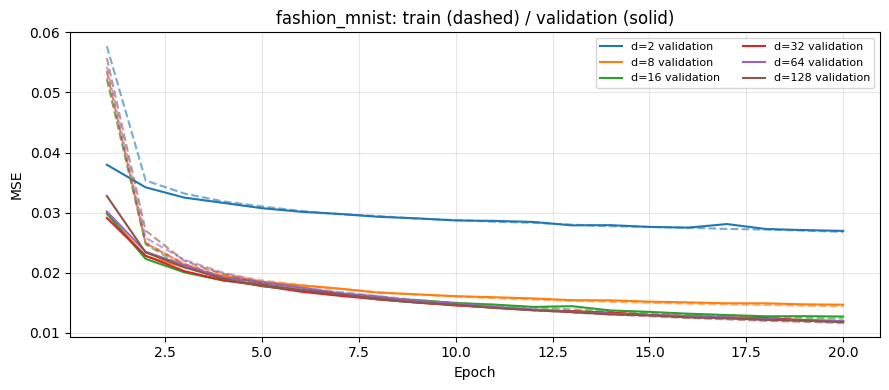

In [30]:
fig,axes=plt.subplots(1,len(DATASET_NAMES),figsize=(7*len(DATASET_NAMES),4),squeeze=False)
for ax,dataset in zip(axes.flat,DATASET_NAMES):
    vals=pd.DataFrame([r for r in runs if r['dataset']==dataset]).sort_values('latent_dim')
    tests=test_results.loc[(test_results.dataset==dataset)&(test_results.method=='autoencoder')].sort_values('latent_dim')
    reference=test_results.loc[(test_results.dataset==dataset)&(test_results.method=='mean_image'),'mse'].iloc[0]
    ax.plot(vals.latent_dim,vals.val_mse,'o-',label='Validation MSE')
    ax.plot(tests.latent_dim,tests.mse,'s-',label='Test MSE')
    ax.axhline(reference,linestyle='--',color='gray',label='Mean-image test MSE')
    ax.set_xscale('log',base=2)
    ax.set_xticks(LATENT_SIZES,labels=[str(d) for d in LATENT_SIZES])
    ax.set(title=dataset,xlabel='Latent size (log2)',ylabel='Per-pixel MSE')
    ax.grid(alpha=0.3)
    ax.legend()
fig.suptitle(('SMOKE TEST | ' if SMOKE_TEST else '')+'Reconstruction error versus latent size')
fig.tight_layout()
fig.savefig(RESULTS/'reconstruction_error_vs_latent.png',dpi=130)
plt.show()
plt.close(fig)
for dataset in DATASET_NAMES:
    fig,ax=plt.subplots(figsize=(9,4))
    for size in LATENT_SIZES:
        history=pd.read_csv(RESULTS/dataset/f'latent_{size}'/'history.csv')
        line,=ax.plot(history.epoch,history.val_mse,label=f'd={size} validation')
        ax.plot(history.epoch,history.train_mse,'--',color=line.get_color(),alpha=0.6)
    ax.set(title=dataset+': train (dashed) / validation (solid)',xlabel='Epoch',ylabel='MSE')
    ax.grid(alpha=0.3)
    ax.legend(ncol=2,fontsize=8)
    fig.tight_layout()
    fig.savefig(RESULTS/f'{dataset}_learning_curves.png',dpi=130)
    plt.show()
    plt.close(fig)


## 6. Original images and reconstructions

Each model reconstructed the same held-out images. Small bottlenecks lost fine details, while larger ones preserved more structure. These panels show the visual effect of the compression–reconstruction tradeoff.


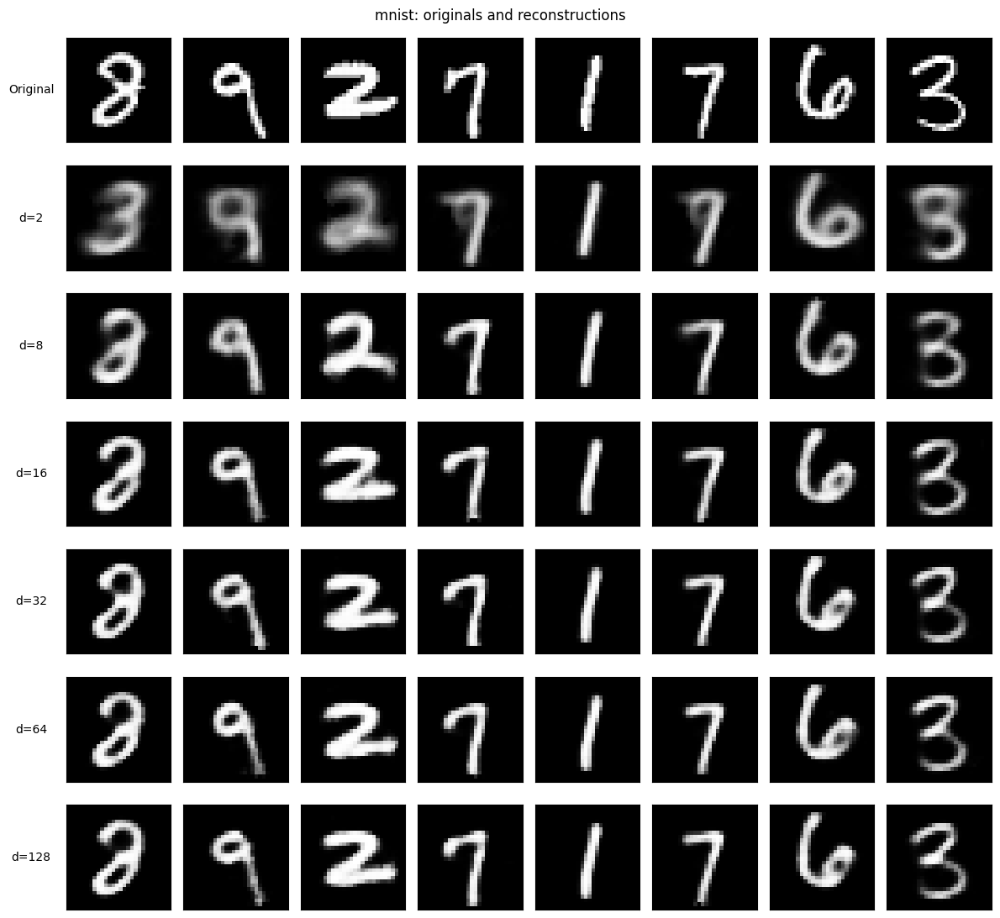

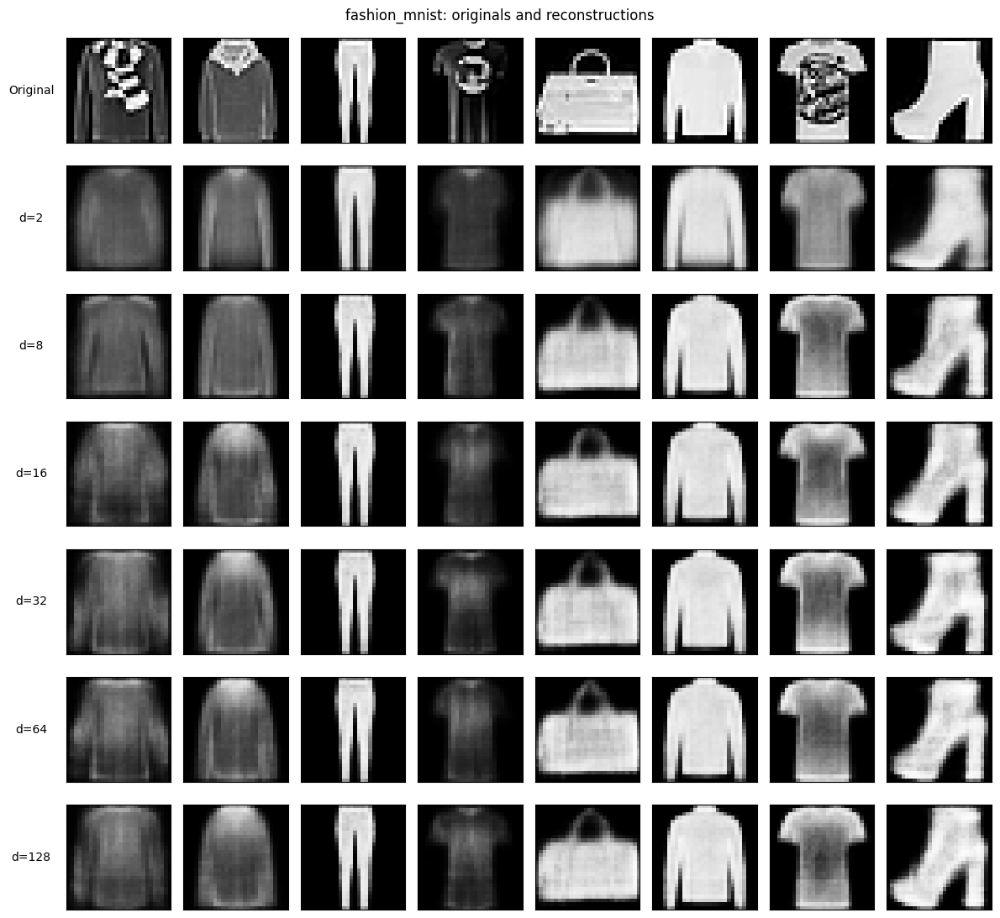

In [31]:
for dataset in DATASET_NAMES:
    test_data=testing_loader(dataset).dataset
    indices=torch.randperm(len(test_data),generator=torch.Generator().manual_seed(123))[:8]
    examples=torch.stack([test_data[int(i)][0] for i in indices])
    rows=[('Original',examples)]
    for size in LATENT_SIZES:
        run=next(r for r in runs if r['dataset']==dataset and r['latent_dim']==size)
        model=Autoencoder(size).to(DEVICE)
        model.load_state_dict(torch.load(run['checkpoint'],map_location=DEVICE,weights_only=True)['model'])
        model.eval()
        with torch.no_grad(): predictions=model(examples.to(DEVICE)).cpu()
        rows.append((f'd={size}',predictions))
    reconstruction_panel(rows,dataset+': originals and reconstructions',RESULTS/f'{dataset}_reconstruction_comparison.png')


## Part 2: Variational Autoencoder

A convolutional VAE was trained on both datasets. Its encoder learned a diagonal-Gaussian posterior, and training optimized the evidence lower bound (ELBO). The results include held-out reconstructions and new images sampled from a standard normal prior.


In [33]:
from torch.nn import functional as F

VAE_LATENT_DIM = 32
VAE_EPOCHS = 30
VAE_LEARNING_RATE = 1e-3
VAE_IMPORTANCE_SAMPLES = 16  # Test likelihood-bound estimate; validation uses 1 sample.
VAE_RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
VAE_RESULTS = HW/'results'/'vae'/('smoke' if SMOKE_TEST else 'full')/VAE_RUN_ID
VAE_CHECKPOINTS = ROOT/'.local'/'hw1'/'vae'/'checkpoints'/VAE_RUN_ID
VAE_RESULTS.mkdir(parents=True,exist_ok=True)
VAE_CHECKPOINTS.mkdir(parents=True,exist_ok=True)
(VAE_RESULTS/'environment.json').write_text(json.dumps(environment,indent=2))
print('VAE device:',DEVICE)
print('VAE results:',VAE_RESULTS)


VAE device: cuda
VAE results: c:\Users\Admin\Desktop\GEN_AI_CV\HW1\results\vae\full\20261112T195949996736Z


### 2.1 Observation model and ELBO

The model used a Bernoulli image likelihood. Grayscale images were dynamically binarized: $x_i\sim\mathrm{Bernoulli}(g_i)$, where $g_i\in[0,1]$ is the original pixel. Training used new binary draws; validation and test used fixed seeds. All likelihood bounds therefore describe binary observations rather than original grayscale values.

The encoder predicted $\mu$ and diagonal log-variance. Latents were sampled with the reparameterization trick:

$$z=\mu+\exp(0.5\log\sigma^2)\odot\epsilon,\qquad\epsilon\sim\mathcal N(0,I).$$

The standard VAE used KL weight 1:

$$-\mathrm{ELBO}(x)=\mathbb E_q[-\log p_\theta(x|z)]+\mathrm{KL}(q_\phi(z|x)\Vert\mathcal N(0,I)).$$

Reconstruction NLL was calculated with BCE-with-logits summed over 784 pixels. Gaussian KL was summed over latent coordinates:

$$\mathrm{KL}=\tfrac12\sum_j(\mu_j^2+\exp(\log\sigma_j^2)-1-\log\sigma_j^2).$$


### 2.2 Convolutional architecture

Unlike the compression baseline, the VAE used convolutions to model spatial structure.

| Component | Layers / output |
|---|---|
| Encoder | Conv 1→32, kernel 4/stride 2/padding 1: 28→14; ReLU; Conv 32→64 with the same settings: 14→7; ReLU |
| Posterior heads | Flatten 64×7×7 → Linear 256 → ReLU → separate mean and log-variance heads, each size 32 |
| Decoder | Latent → Linear 256 → ReLU → Linear 64×7×7 → ReLU; reshape |
| Upsampling | Transposed Conv 64→32: 7→14; ReLU; Transposed Conv 32→1: 14→28 |
| Output | Logits for stable BCE training; sigmoid gives Bernoulli probabilities |


In [34]:
class ConvVAE(nn.Module):
    def __init__(self,latent_dim=32):
        super().__init__()
        self.latent_dim=latent_dim
        self.encoder=nn.Sequential(
            nn.Conv2d(1,32,4,stride=2,padding=1),nn.ReLU(),
            nn.Conv2d(32,64,4,stride=2,padding=1),nn.ReLU(),
            nn.Flatten(),nn.Linear(64*7*7,256),nn.ReLU())
        self.mu_head=nn.Linear(256,latent_dim)
        self.logvar_head=nn.Linear(256,latent_dim)
        self.decoder=nn.Sequential(
            nn.Linear(latent_dim,256),nn.ReLU(),nn.Linear(256,64*7*7),nn.ReLU(),
            nn.Unflatten(1,(64,7,7)),nn.ConvTranspose2d(64,32,4,stride=2,padding=1),nn.ReLU(),
            nn.ConvTranspose2d(32,1,4,stride=2,padding=1))
    def encode(self,x):
        hidden=self.encoder(x)
        return self.mu_head(hidden),self.logvar_head(hidden).clamp(-12,8)
    def reparameterize(self,mu,logvar,generator=None):
        noise=torch.randn(mu.shape,device=mu.device,dtype=mu.dtype,generator=generator)
        return mu+torch.exp(0.5*logvar)*noise
    def decode(self,z):
        return self.decoder(z)  # logits, not probabilities
    def forward(self,x,generator=None):
        mu,logvar=self.encode(x)
        return self.decode(self.reparameterize(mu,logvar,generator)),mu,logvar
    @torch.no_grad()
    def sample(self,n=64,seed=123):
        device=next(self.parameters()).device
        generator=torch.Generator(device=device).manual_seed(seed)
        z=torch.randn(n,self.latent_dim,device=device,generator=generator)
        probabilities=torch.sigmoid(self.decode(z))
        pixels=torch.bernoulli(probabilities,generator=generator)
        return probabilities,pixels

def vae_terms(logits,target,mu,logvar):
    reconstruction=F.binary_cross_entropy_with_logits(logits,target,reduction='none').flatten(1).sum(1)
    kl=0.5*(mu.square()+logvar.exp()-1-logvar).sum(1)
    return reconstruction,kl

# Numerical checks use CPU only.
def check_vae():
    model=ConvVAE(latent_dim=4)
    x=torch.randint(0,2,(3,1,28,28)).float()
    logits,mu,logvar=model(x)
    reconstruction,kl=vae_terms(logits,x,mu,logvar)
    assert logits.shape==x.shape and mu.shape==logvar.shape==(3,4)
    assert reconstruction.shape==kl.shape==(3,)
    torch.testing.assert_close(vae_terms(logits,x,torch.zeros_like(mu),torch.zeros_like(logvar))[1],torch.zeros(3))
    normal=torch.distributions.Normal(mu,torch.exp(0.5*logvar))
    prior=torch.distributions.Normal(torch.zeros_like(mu),torch.ones_like(mu))
    torch.testing.assert_close(kl,torch.distributions.kl_divergence(normal,prior).sum(1))
    (reconstruction+kl).mean().backward()
    assert all(p.grad is not None and torch.isfinite(p.grad).all() for p in model.parameters())
    first=model.reparameterize(mu.detach(),logvar.detach(),torch.Generator().manual_seed(1))
    second=model.reparameterize(mu.detach(),logvar.detach(),torch.Generator().manual_seed(1))
    torch.testing.assert_close(first,second)
    probabilities,pixels=model.sample(n=4)
    assert probabilities.shape==pixels.shape==(4,1,28,28)
    assert ((pixels==0)|(pixels==1)).all()
    print('Passed: shapes, Gaussian KL, reparameterization reproducibility, finite gradients and prior samples.')
check_vae()


Passed: shapes, Gaussian KL, reparameterization reproducibility, finite gradients and prior samples.


### 2.3 Validation and importance-weighted evaluation

Evaluation used repeatable binarization and posterior sampling. Reconstruction NLL, KL and negative ELBO are reported in nats/image. Test evaluation also used an importance-weighted bound with K=16:

$$\mathbb E\left[\log\frac1K\sum_{k=1}^K\frac{p_\theta(x|z_k)p(z_k)}{q_\phi(z_k|x)}\right]\leq\log p(x),\qquad z_k\sim q_\phi(z|x).$$

The calculation used log-sum-exp. Its negative is a bound estimate, not exact NLL. The bound tightens with K in expectation, but individual Monte Carlo estimates can fluctuate. Training used the standard ELBO rather than an IWAE objective.

Separate random generators kept binary test images unchanged when K changed. Importance samples were decoded sequentially to reduce memory use.


In [35]:
@torch.no_grad()
def evaluate_vae(model,loader,importance_samples=1,seed=2026):
    model.eval()
    binary_rng=torch.Generator(device=DEVICE).manual_seed(seed)
    latent_rng=torch.Generator(device=DEVICE).manual_seed(seed+1)
    totals=dict(reconstruction_nll=0.,kl=0.,negative_elbo=0.,negative_iwae_estimate=0.,gray_mse=0.)
    count=0
    for gray,_ in loader:
        gray=gray.to(DEVICE)
        x=torch.bernoulli(gray,generator=binary_rng)
        mu,logvar=model.encode(x)
        kl=0.5*(mu.square()+logvar.exp()-1-logvar).sum(1)
        reconstruction_sum=torch.zeros(len(x),device=DEVICE)
        log_weights=[]
        for _ in range(importance_samples):
            z=model.reparameterize(mu,logvar,latent_rng)
            logits=model.decode(z)
            reconstruction=F.binary_cross_entropy_with_logits(logits,x,reduction='none').flatten(1).sum(1)
            log_pz=-0.5*(z.square()+math.log(2*math.pi)).sum(1)
            log_qz=-0.5*((z-mu).square()*torch.exp(-logvar)+logvar+math.log(2*math.pi)).sum(1)
            log_weights.append(-reconstruction+log_pz-log_qz)
            reconstruction_sum+=reconstruction
        reconstruction=reconstruction_sum/importance_samples
        negative_iwae=-(torch.logsumexp(torch.stack(log_weights),dim=0)-math.log(importance_samples))
        gray_mu,_=model.encode(gray)
        gray_reconstruction=torch.sigmoid(model.decode(gray_mu))
        gray_mse=(gray_reconstruction-gray).square().flatten(1).mean(1)
        values=dict(reconstruction_nll=reconstruction,kl=kl,negative_elbo=reconstruction+kl,
                    negative_iwae_estimate=negative_iwae,gray_mse=gray_mse)
        for key,value in values.items():
            if not torch.isfinite(value).all(): raise FloatingPointError(f'Non-finite {key}')
            totals[key]+=value.sum().item()
        count+=len(x)
    return {key:value/count for key,value in totals.items()}

def vae_panel(rows,title,path,columns=8):
    fig,axes=plt.subplots(len(rows),columns,figsize=(1.5*columns,1.6*len(rows)),squeeze=False)
    for index,(label,images) in enumerate(rows):
        for ax,image in zip(axes[index],images[:columns]):
            ax.imshow(image.detach().cpu().squeeze(),cmap='gray',vmin=0,vmax=1)
            ax.set_xticks([])
            ax.set_yticks([])
        axes[index,0].set_ylabel(label,rotation=0,labelpad=45,va='center',fontsize=9)
    fig.suptitle(('SMOKE TEST | ' if SMOKE_TEST else '')+title)
    fig.tight_layout()
    fig.savefig(path,dpi=130,bbox_inches='tight')
    plt.show()
    plt.close(fig)

@torch.no_grad()
def vae_reconstruction_preview(model,gray,title,path):
    model.eval()
    gray=gray.to(DEVICE)
    generator=torch.Generator(device=DEVICE).manual_seed(1234)
    binary=torch.bernoulli(gray,generator=generator)
    binary_mu,_=model.encode(binary)
    gray_mu,_=model.encode(gray)
    vae_panel([('Original gray',gray),('Binary input',binary),
               ('Recon. binary input',torch.sigmoid(model.decode(binary_mu))),
               ('Recon. gray input',torch.sigmoid(model.decode(gray_mu)))],title,path)

@torch.no_grad()
def vae_sample_grid(model,title,path):
    model.eval()
    probabilities,pixels=model.sample(n=64)
    probability_rows=[(f'Prior means {i+1}',probabilities[i*8:(i+1)*8]) for i in range(8)]
    vae_panel(probability_rows,title+' | decoder probabilities',path)
    return probabilities,pixels


### 2.4 Training on both datasets

Both models were trained from scratch for 30 epochs with Adam at 1e-3 and gradient clipping at 5. Architecture, latent size and training budget were the same. Each checkpoint was selected by validation negative ELBO.


mnist VAE | 1/30 | train -ELBO 205.30, val -ELBO 163.39 | val KL 11.04 | 1.5s


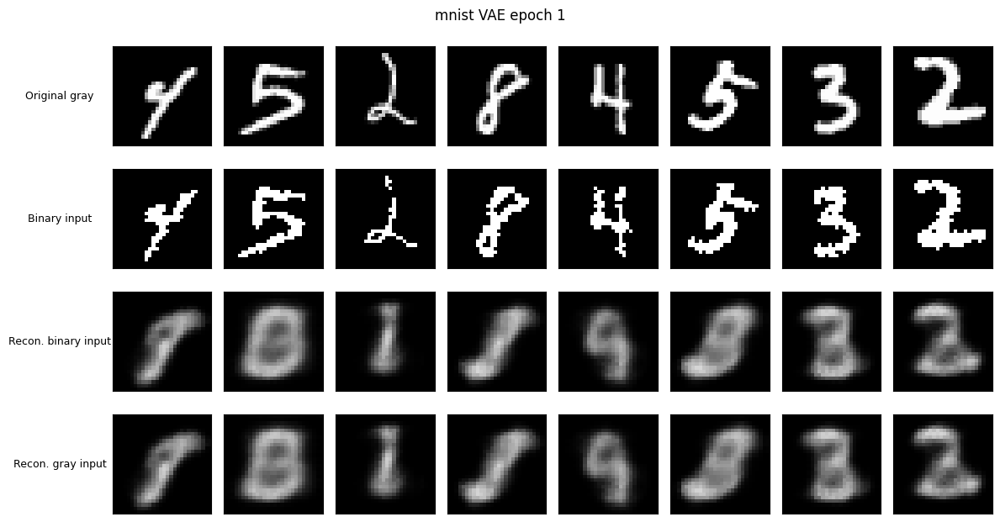

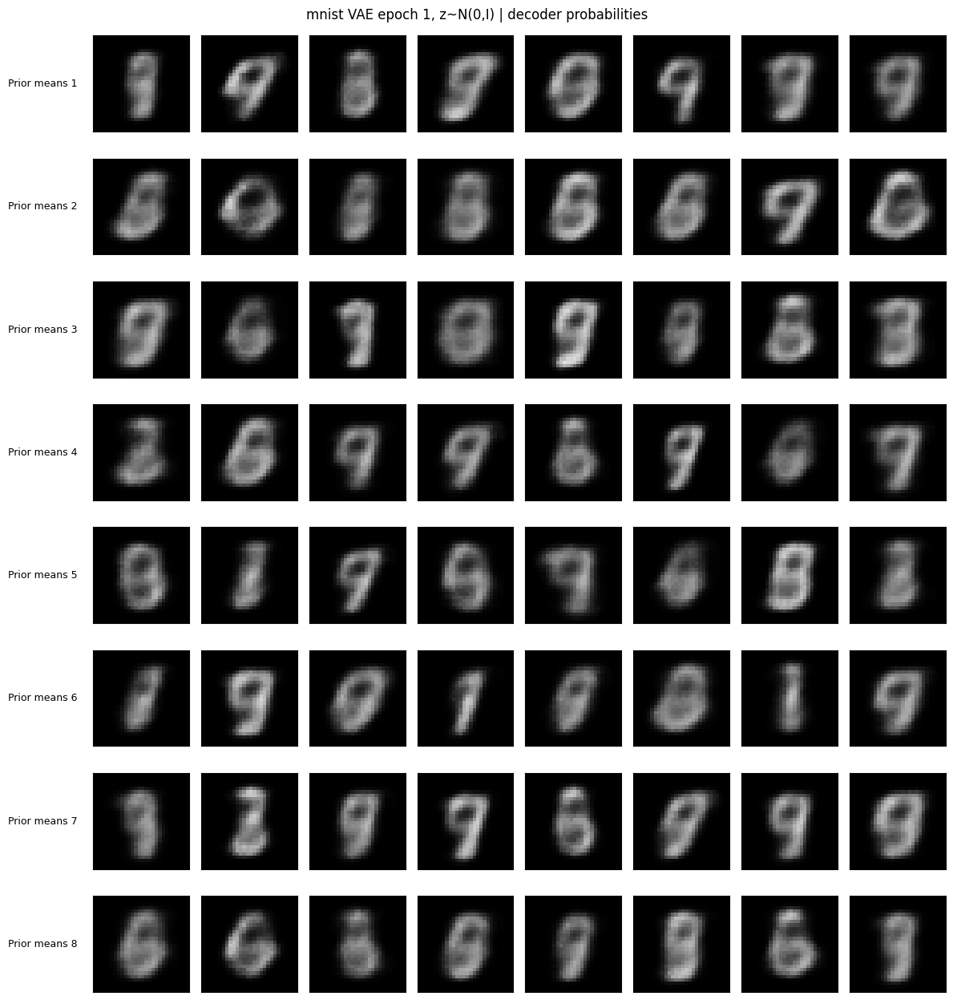

mnist VAE | 2/30 | train -ELBO 149.18, val -ELBO 138.69 | val KL 15.70 | 1.5s
mnist VAE | 3/30 | train -ELBO 131.43, val -ELBO 125.45 | val KL 17.61 | 1.5s
mnist VAE | 4/30 | train -ELBO 120.75, val -ELBO 117.28 | val KL 19.45 | 1.5s
mnist VAE | 5/30 | train -ELBO 114.40, val -ELBO 112.48 | val KL 19.67 | 1.5s
mnist VAE | 6/30 | train -ELBO 110.61, val -ELBO 109.33 | val KL 20.55 | 1.5s
mnist VAE | 7/30 | train -ELBO 107.83, val -ELBO 106.79 | val KL 21.04 | 1.4s
mnist VAE | 8/30 | train -ELBO 105.61, val -ELBO 105.04 | val KL 21.08 | 1.5s
mnist VAE | 9/30 | train -ELBO 104.07, val -ELBO 103.70 | val KL 21.52 | 1.4s
mnist VAE | 10/30 | train -ELBO 102.98, val -ELBO 102.53 | val KL 21.64 | 1.4s


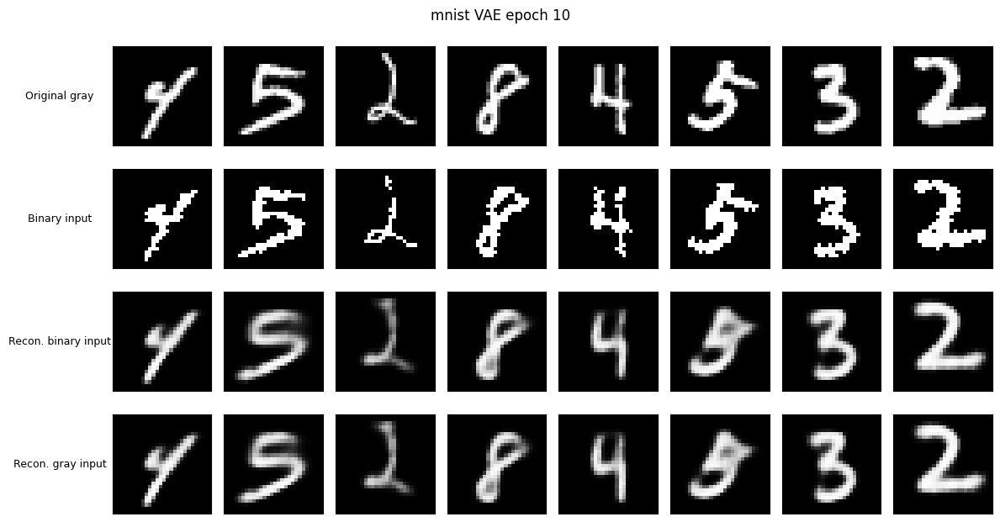

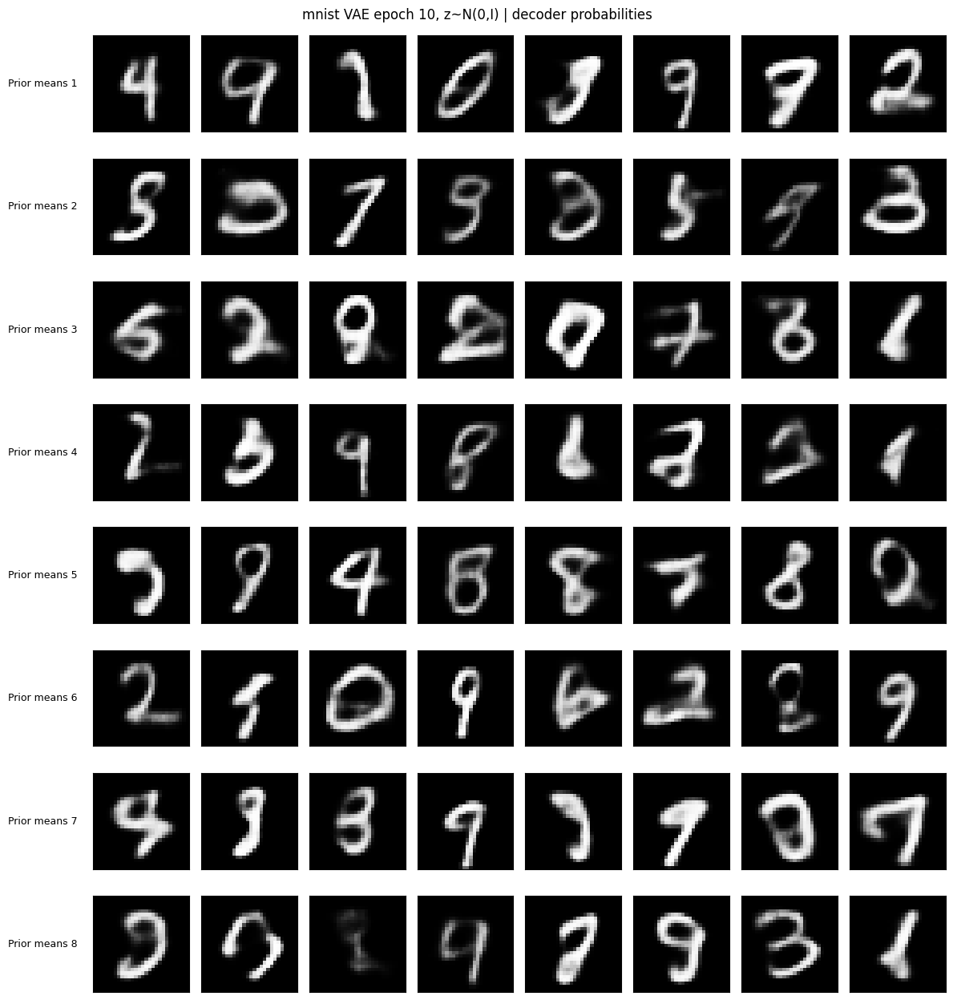

mnist VAE | 11/30 | train -ELBO 102.12, val -ELBO 102.38 | val KL 21.84 | 1.4s
mnist VAE | 12/30 | train -ELBO 101.28, val -ELBO 101.34 | val KL 22.13 | 1.5s
mnist VAE | 13/30 | train -ELBO 100.68, val -ELBO 100.80 | val KL 21.57 | 1.5s
mnist VAE | 14/30 | train -ELBO 100.09, val -ELBO 100.31 | val KL 21.74 | 1.4s
mnist VAE | 15/30 | train -ELBO 99.49, val -ELBO 99.65 | val KL 21.66 | 1.4s
mnist VAE | 16/30 | train -ELBO 99.16, val -ELBO 99.98 | val KL 21.90 | 1.4s
mnist VAE | 17/30 | train -ELBO 98.74, val -ELBO 99.56 | val KL 22.08 | 1.4s
mnist VAE | 18/30 | train -ELBO 98.45, val -ELBO 98.76 | val KL 22.34 | 1.4s
mnist VAE | 19/30 | train -ELBO 98.15, val -ELBO 98.91 | val KL 22.48 | 1.4s
mnist VAE | 20/30 | train -ELBO 97.90, val -ELBO 98.52 | val KL 22.29 | 1.4s


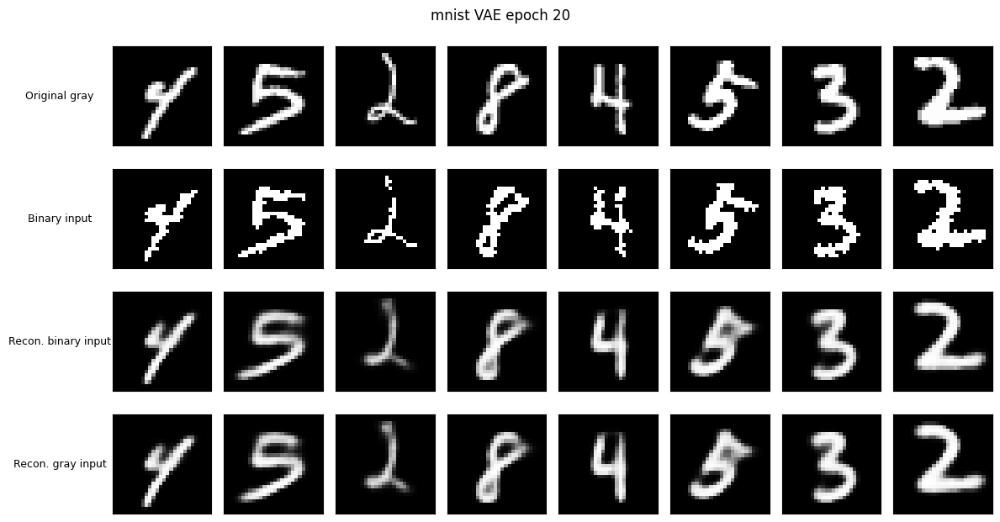

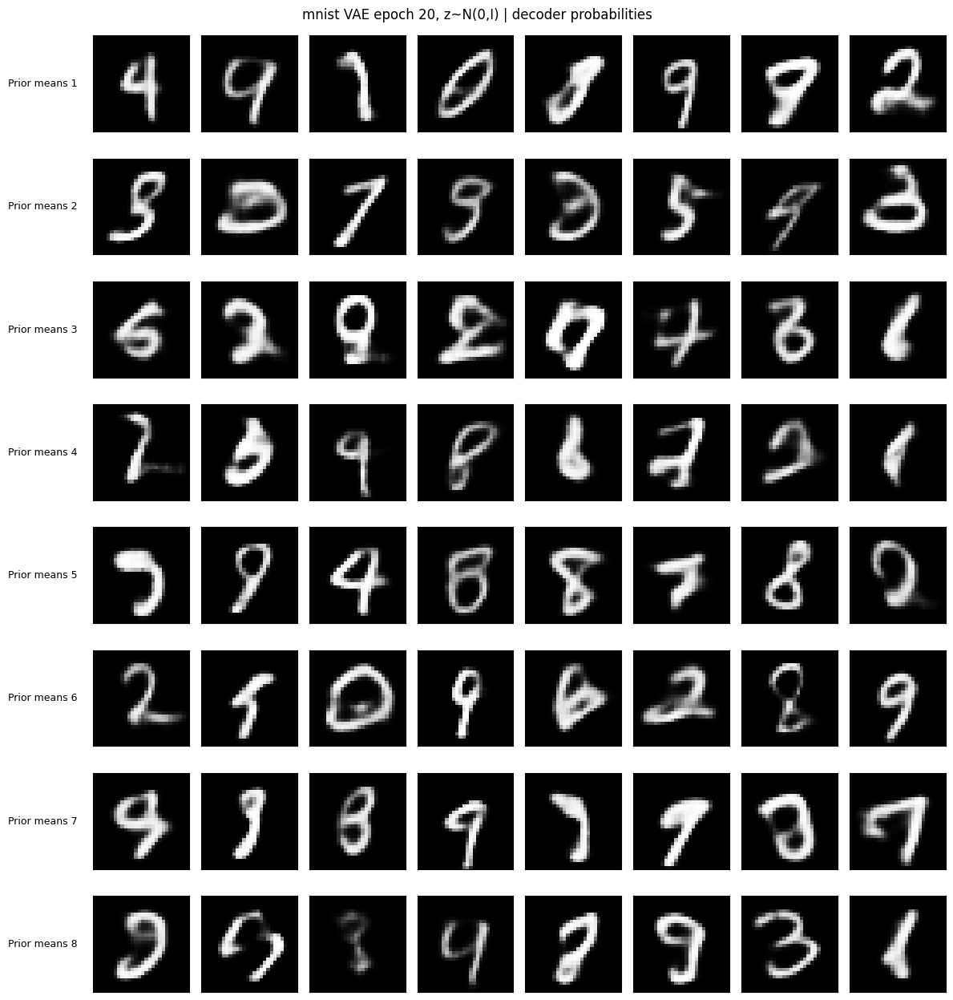

mnist VAE | 21/30 | train -ELBO 97.56, val -ELBO 97.90 | val KL 22.65 | 1.4s
mnist VAE | 22/30 | train -ELBO 97.37, val -ELBO 98.14 | val KL 21.79 | 1.4s
mnist VAE | 23/30 | train -ELBO 97.11, val -ELBO 97.78 | val KL 22.57 | 1.4s
mnist VAE | 24/30 | train -ELBO 96.95, val -ELBO 97.36 | val KL 22.37 | 1.4s
mnist VAE | 25/30 | train -ELBO 96.79, val -ELBO 97.21 | val KL 22.44 | 1.4s
mnist VAE | 26/30 | train -ELBO 96.53, val -ELBO 97.20 | val KL 22.51 | 1.4s
mnist VAE | 27/30 | train -ELBO 96.25, val -ELBO 97.18 | val KL 22.50 | 1.4s
mnist VAE | 28/30 | train -ELBO 96.29, val -ELBO 97.08 | val KL 22.14 | 1.4s
mnist VAE | 29/30 | train -ELBO 96.13, val -ELBO 96.73 | val KL 22.41 | 1.4s
mnist VAE | 30/30 | train -ELBO 95.84, val -ELBO 96.95 | val KL 22.74 | 1.4s


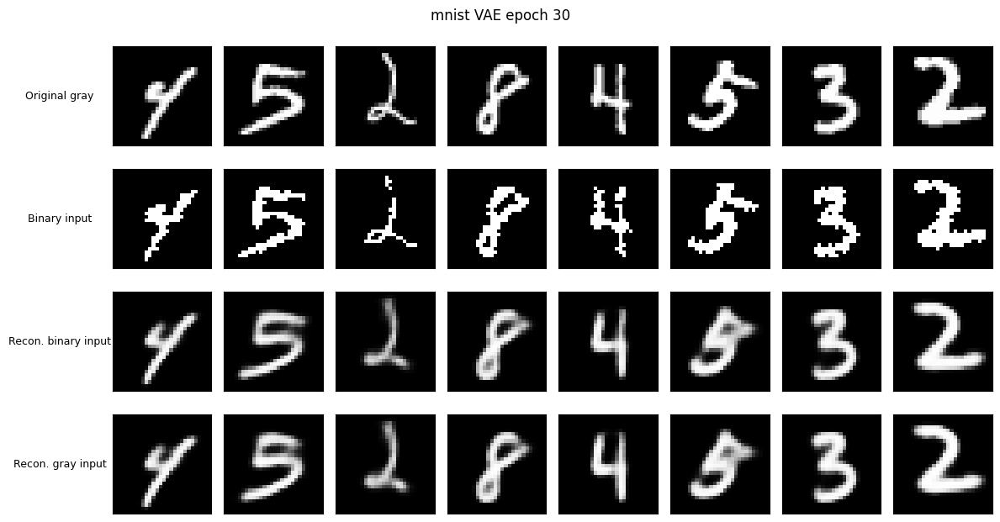

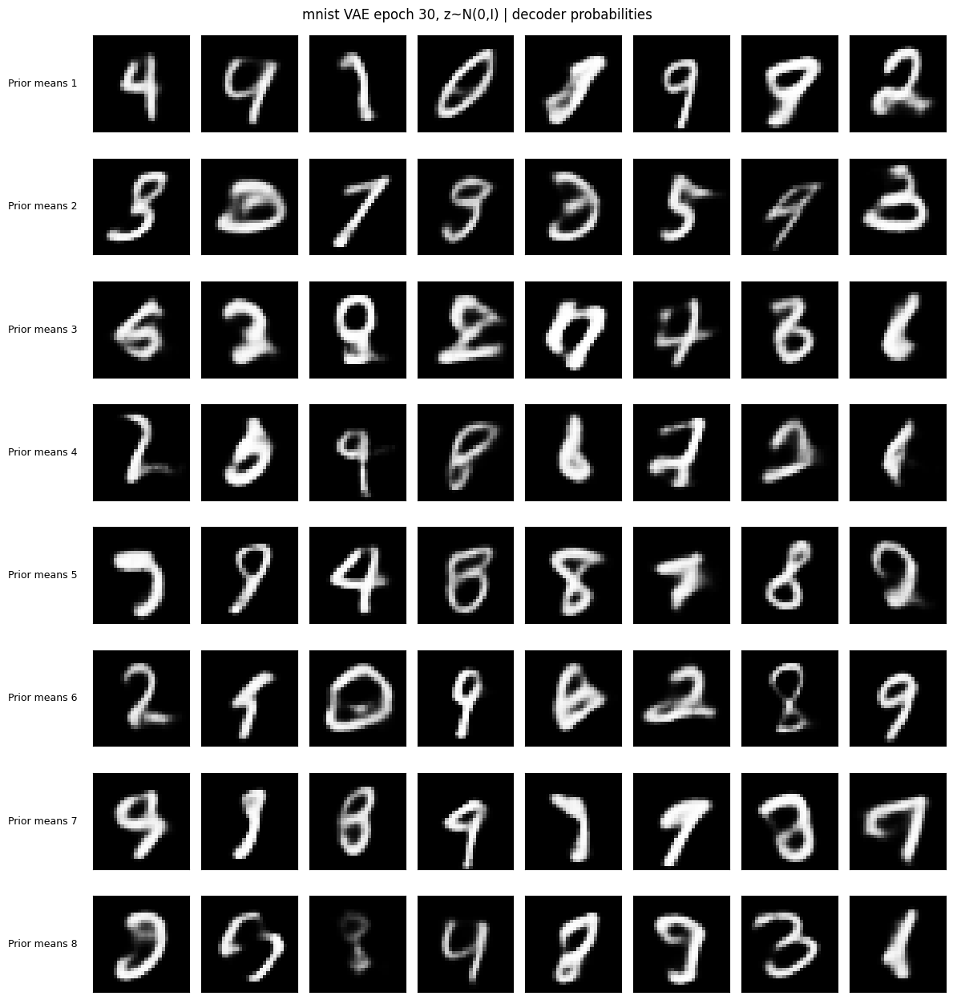

fashion_mnist VAE | 1/30 | train -ELBO 320.03, val -ELBO 273.81 | val KL 13.98 | 1.4s


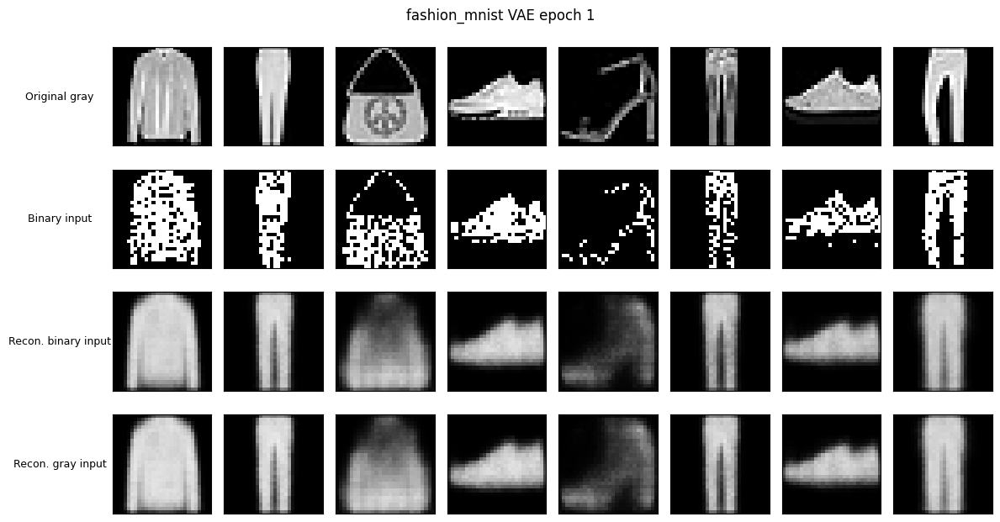

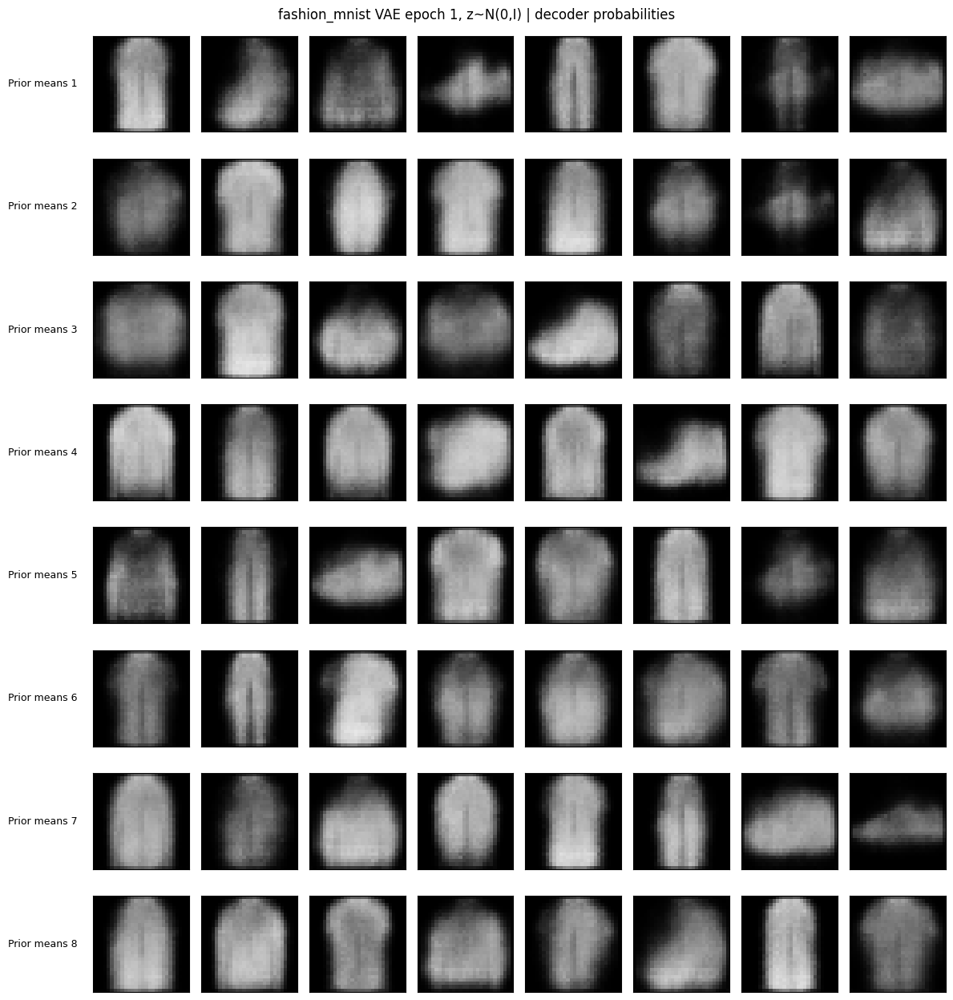

fashion_mnist VAE | 2/30 | train -ELBO 264.44, val -ELBO 259.20 | val KL 14.14 | 1.4s
fashion_mnist VAE | 3/30 | train -ELBO 255.29, val -ELBO 253.18 | val KL 13.48 | 1.4s
fashion_mnist VAE | 4/30 | train -ELBO 250.61, val -ELBO 251.24 | val KL 13.82 | 1.4s
fashion_mnist VAE | 5/30 | train -ELBO 247.91, val -ELBO 247.62 | val KL 14.02 | 1.4s
fashion_mnist VAE | 6/30 | train -ELBO 245.66, val -ELBO 245.73 | val KL 14.12 | 1.4s
fashion_mnist VAE | 7/30 | train -ELBO 244.19, val -ELBO 244.12 | val KL 13.97 | 1.4s
fashion_mnist VAE | 8/30 | train -ELBO 242.67, val -ELBO 242.89 | val KL 14.20 | 1.4s
fashion_mnist VAE | 9/30 | train -ELBO 241.71, val -ELBO 241.85 | val KL 14.63 | 1.4s
fashion_mnist VAE | 10/30 | train -ELBO 240.70, val -ELBO 241.22 | val KL 14.76 | 1.4s


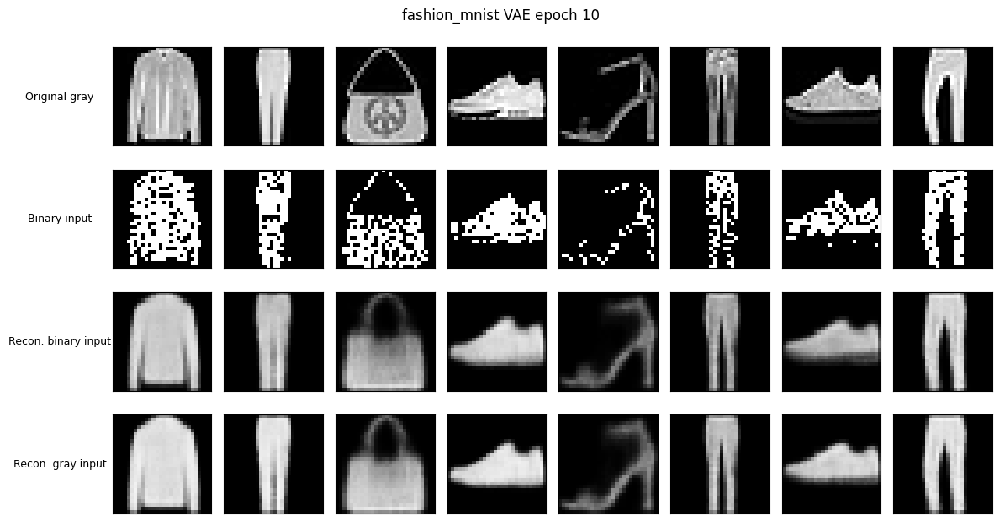

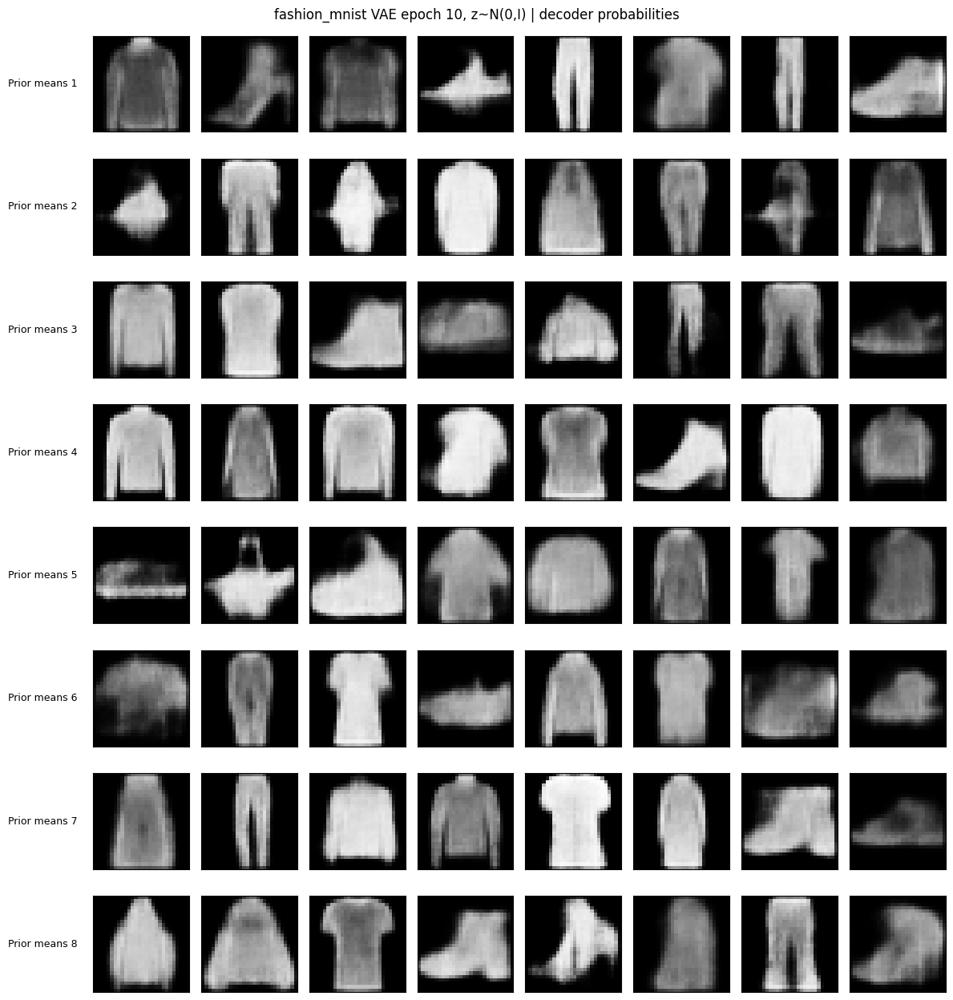

fashion_mnist VAE | 11/30 | train -ELBO 240.12, val -ELBO 241.17 | val KL 14.95 | 1.5s
fashion_mnist VAE | 12/30 | train -ELBO 239.50, val -ELBO 240.01 | val KL 15.17 | 1.4s
fashion_mnist VAE | 13/30 | train -ELBO 239.09, val -ELBO 239.87 | val KL 14.61 | 1.4s
fashion_mnist VAE | 14/30 | train -ELBO 238.67, val -ELBO 239.31 | val KL 14.71 | 1.4s
fashion_mnist VAE | 15/30 | train -ELBO 238.25, val -ELBO 238.79 | val KL 15.19 | 1.4s
fashion_mnist VAE | 16/30 | train -ELBO 237.78, val -ELBO 238.36 | val KL 15.06 | 1.4s
fashion_mnist VAE | 17/30 | train -ELBO 237.49, val -ELBO 238.03 | val KL 15.12 | 1.4s
fashion_mnist VAE | 18/30 | train -ELBO 237.18, val -ELBO 237.83 | val KL 15.55 | 1.4s
fashion_mnist VAE | 19/30 | train -ELBO 236.87, val -ELBO 237.92 | val KL 15.45 | 1.4s
fashion_mnist VAE | 20/30 | train -ELBO 236.59, val -ELBO 237.16 | val KL 15.37 | 1.4s


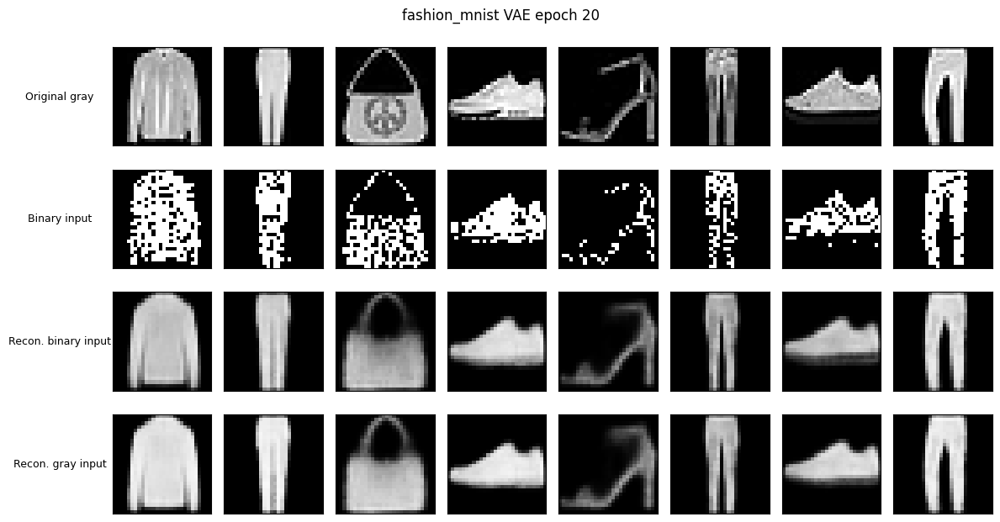

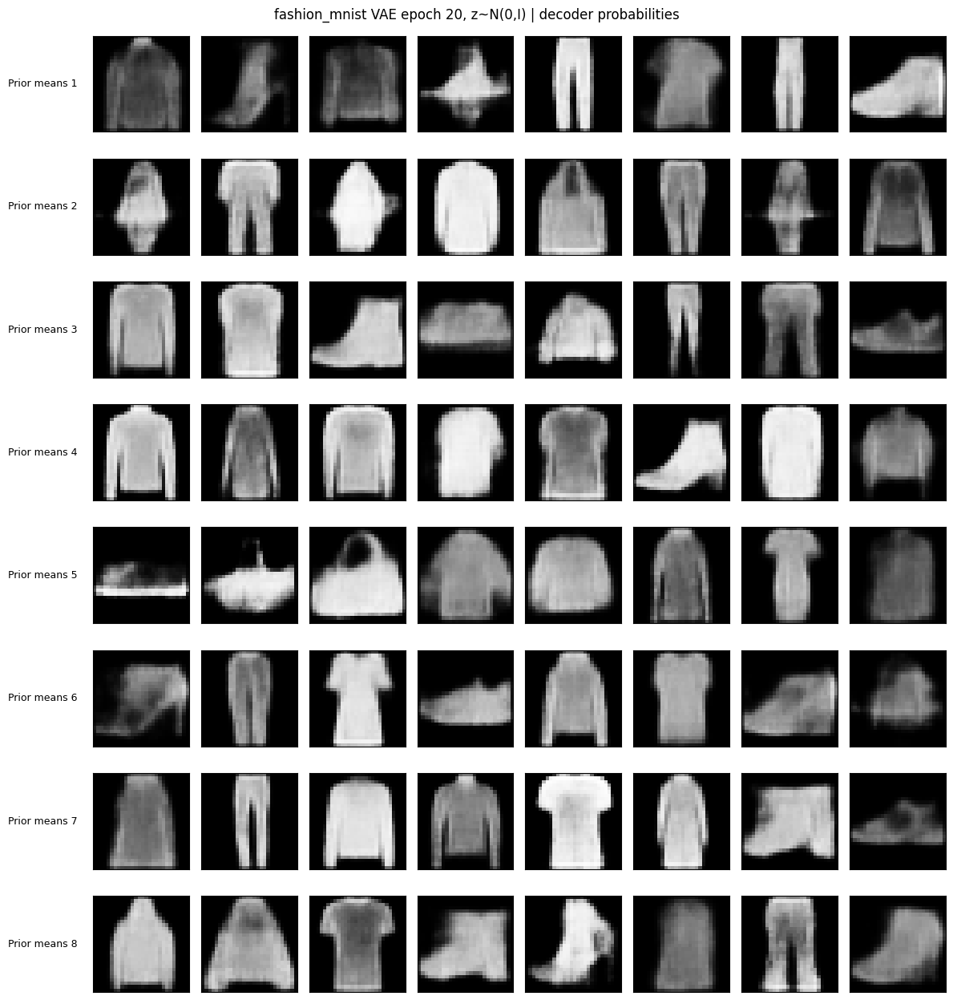

fashion_mnist VAE | 21/30 | train -ELBO 236.38, val -ELBO 236.86 | val KL 15.92 | 1.4s
fashion_mnist VAE | 22/30 | train -ELBO 236.09, val -ELBO 236.91 | val KL 15.03 | 1.4s
fashion_mnist VAE | 23/30 | train -ELBO 235.93, val -ELBO 237.05 | val KL 15.30 | 1.4s
fashion_mnist VAE | 24/30 | train -ELBO 235.75, val -ELBO 236.94 | val KL 15.82 | 1.4s
fashion_mnist VAE | 25/30 | train -ELBO 235.75, val -ELBO 236.48 | val KL 15.46 | 1.4s
fashion_mnist VAE | 26/30 | train -ELBO 235.50, val -ELBO 236.26 | val KL 15.76 | 1.4s
fashion_mnist VAE | 27/30 | train -ELBO 235.31, val -ELBO 236.26 | val KL 15.99 | 1.4s
fashion_mnist VAE | 28/30 | train -ELBO 235.34, val -ELBO 236.30 | val KL 15.62 | 1.4s
fashion_mnist VAE | 29/30 | train -ELBO 235.07, val -ELBO 236.06 | val KL 16.18 | 1.4s
fashion_mnist VAE | 30/30 | train -ELBO 235.00, val -ELBO 236.06 | val KL 15.75 | 1.4s


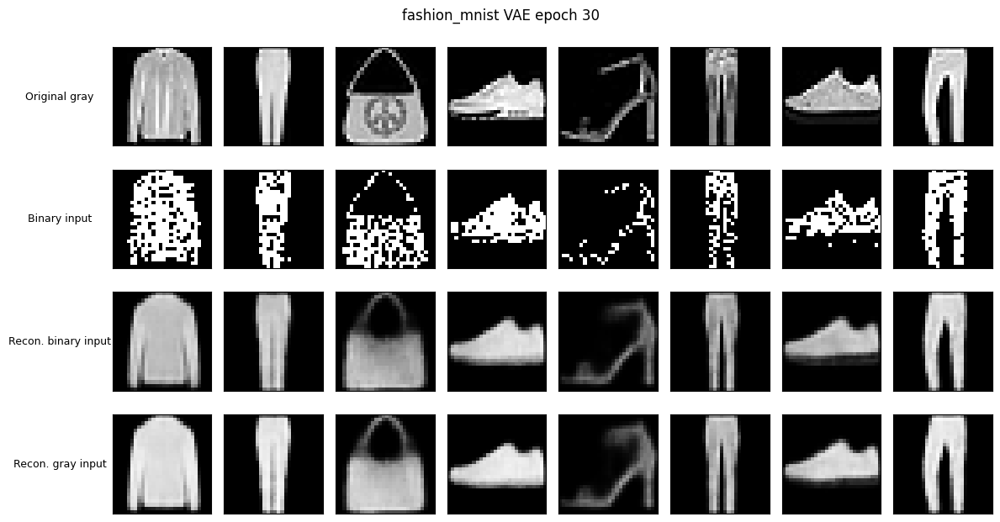

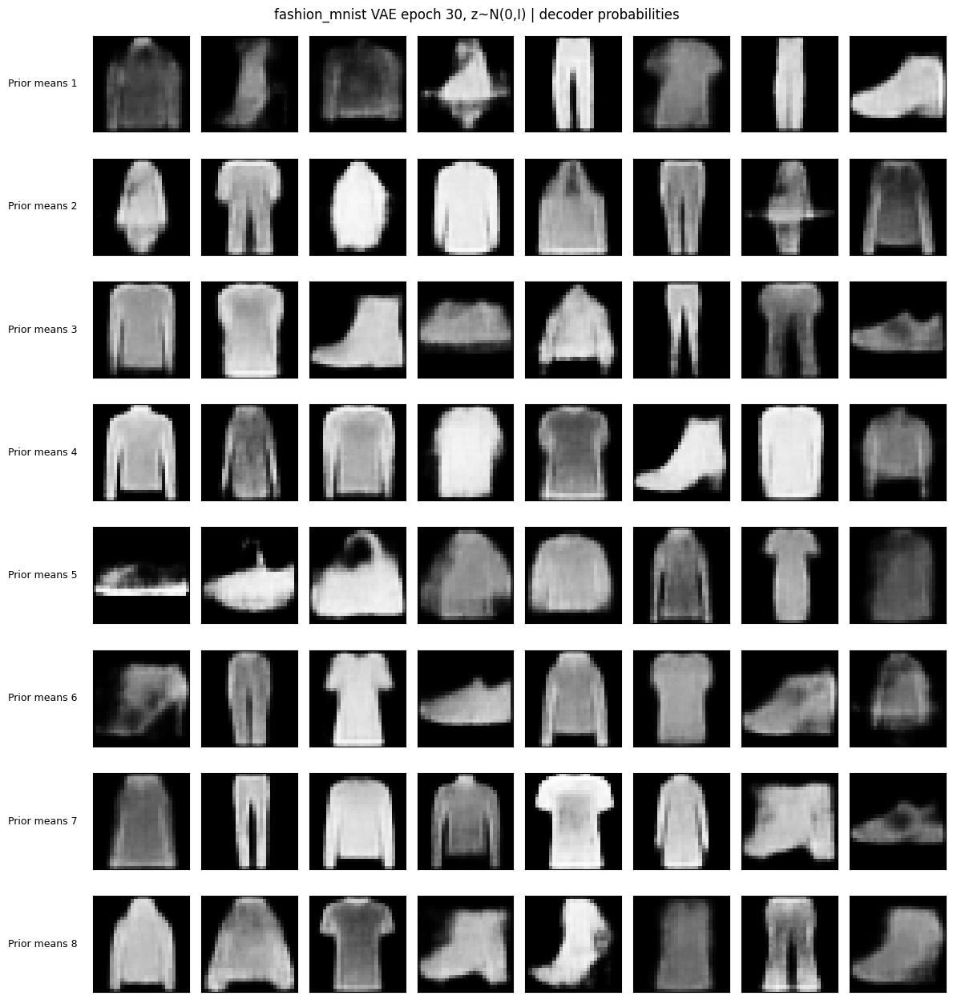

,dataset,best_epoch,val_negative_elbo,latent_dim,parameters,seconds
0,mnist,29,96.726208,32,1700609,42.941779
1,fashion_mnist,30,236.057541,32,1700609,42.320812


In [36]:
def train_vae(dataset):
    seed_all()
    train,val=training_loaders(dataset)
    model=ConvVAE(VAE_LATENT_DIM).to(DEVICE)
    seed_all()
    optimizer=torch.optim.Adam(model.parameters(),lr=VAE_LEARNING_RATE)
    folder=VAE_RESULTS/dataset
    folder.mkdir(parents=True,exist_ok=True)
    checkpoint=VAE_CHECKPOINTS/f'{dataset}_vae.pt'
    epochs=2 if SMOKE_TEST else VAE_EPOCHS
    config=dict(dataset=dataset,latent_dim=VAE_LATENT_DIM,epochs=epochs,seed=SEED,
                batch_size=BATCH_SIZE,learning_rate=VAE_LEARNING_RATE,kl_weight=1.,
                observation_model='Bernoulli on dynamically binarized grayscale images',
                validation_seed=2026,train_size=len(train.dataset),validation_size=len(val.dataset),
                parameters=sum(p.numel() for p in model.parameters()),smoke_test=SMOKE_TEST)
    (folder/'config.json').write_text(json.dumps(config,indent=2))
    examples=next(iter(val))[0][:8]
    best,history=float('inf'),[]
    for epoch in range(1,epochs+1):
        started=time.perf_counter()
        model.train()
        totals=dict(reconstruction_nll=0.,kl=0.,negative_elbo=0.)
        count=0
        for gray,_ in train:
            x=torch.bernoulli(gray.to(DEVICE))
            optimizer.zero_grad(set_to_none=True)
            logits,mu,logvar=model(x)
            reconstruction,kl=vae_terms(logits,x,mu,logvar)
            loss=(reconstruction+kl).mean()
            if not torch.isfinite(loss): raise FloatingPointError('Non-finite VAE loss')
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(),5.,error_if_nonfinite=True)
            optimizer.step()
            totals['reconstruction_nll']+=reconstruction.sum().item()
            totals['kl']+=kl.sum().item()
            totals['negative_elbo']+=(reconstruction+kl).sum().item()
            count+=len(x)
        validation=evaluate_vae(model,val,importance_samples=1)
        row=dict(epoch=epoch,**{'train_'+key:value/count for key,value in totals.items()},
                 **{'val_'+key:value for key,value in validation.items()},
                 seconds=time.perf_counter()-started)
        history.append(row)
        pd.DataFrame(history).to_csv(folder/'history.csv',index=False)
        if validation['negative_elbo']<best:
            best=validation['negative_elbo']
            torch.save(dict(model=model.state_dict(),epoch=epoch,config=config),checkpoint)
        print(f'{dataset} VAE | {epoch}/{epochs} | train -ELBO {row["train_negative_elbo"]:.2f}, val -ELBO {validation["negative_elbo"]:.2f} | val KL {validation["kl"]:.2f} | {row["seconds"]:.1f}s',flush=True)
        if epoch==1 or epoch%10==0 or epoch==epochs:
            vae_reconstruction_preview(model,examples,f'{dataset} VAE epoch {epoch}',folder/f'reconstructions_epoch_{epoch:03d}.png')
            vae_sample_grid(model,f'{dataset} VAE epoch {epoch}, z~N(0,I)',folder/f'prior_epoch_{epoch:03d}.png')
    saved=torch.load(checkpoint,map_location=DEVICE,weights_only=True)
    return dict(dataset=dataset,checkpoint=str(checkpoint),best_epoch=saved['epoch'],
                val_negative_elbo=best,latent_dim=VAE_LATENT_DIM,parameters=config['parameters'],
                seconds=sum(row['seconds'] for row in history))

vae_runs=[]
for dataset in DATASET_NAMES:
    vae_runs.append(train_vae(dataset))
    pd.DataFrame([{key:value for key,value in run.items() if key!='checkpoint'} for run in vae_runs]).to_csv(VAE_RESULTS/'validation_comparison.csv',index=False)
display(pd.DataFrame([{key:value for key,value in run.items() if key!='checkpoint'} for run in vae_runs]))


### 2.5 Test results and learning curves

The best-validation checkpoints were evaluated with fixed test binarization and K=16 importance samples. Grayscale reconstruction MSE was reported separately. The Bernoulli bounds cannot be directly compared with RealNVP's dequantized grayscale bpd.


,dataset,best_epoch,importance_samples,reconstruction_nll,kl,negative_elbo,negative_iwae_estimate,gray_mse,smoke_test
0,mnist,29,16,73.716699,22.412144,96.128844,92.161229,0.009818,False
1,fashion_mnist,30,16,221.529509,15.703661,237.233172,234.678654,0.018563,False


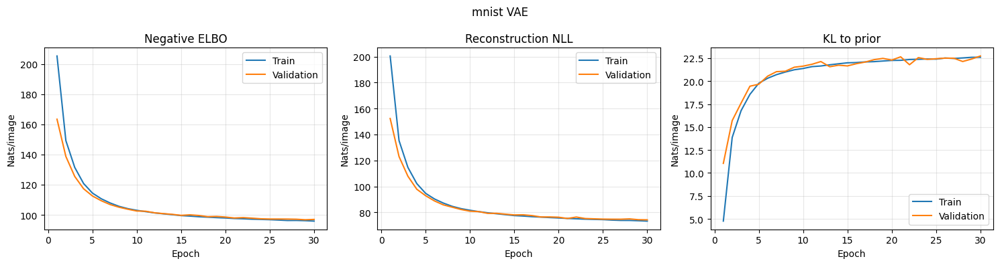

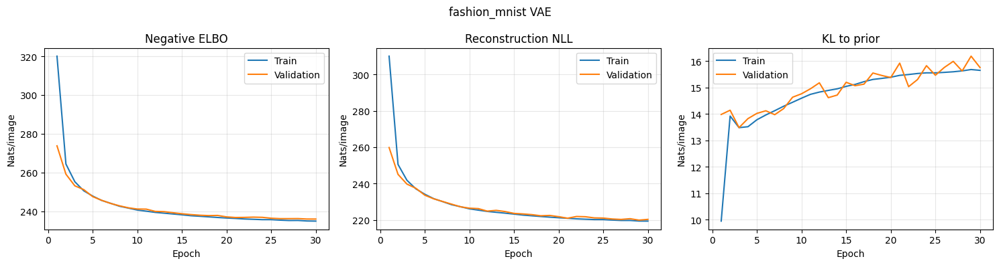

In [37]:
vae_test_rows=[]
for run in vae_runs:
    model=ConvVAE(VAE_LATENT_DIM).to(DEVICE)
    model.load_state_dict(torch.load(run['checkpoint'],map_location=DEVICE,weights_only=True)['model'])
    loader=testing_loader(run['dataset'])
    # Smaller evaluation batches bound memory independently of training batch size.
    loader=DataLoader(loader.dataset,batch_size=64,shuffle=False,num_workers=0)
    k=2 if SMOKE_TEST else VAE_IMPORTANCE_SAMPLES
    values=evaluate_vae(model,loader,importance_samples=k,seed=3030)
    vae_test_rows.append(dict(dataset=run['dataset'],best_epoch=run['best_epoch'],importance_samples=k,
                              **values,smoke_test=SMOKE_TEST))
vae_test_results=pd.DataFrame(vae_test_rows)
vae_test_results.to_csv(VAE_RESULTS/'test_results.csv',index=False)
display(vae_test_results)

for dataset in DATASET_NAMES:
    history=pd.read_csv(VAE_RESULTS/dataset/'history.csv')
    fig,axes=plt.subplots(1,3,figsize=(15,4))
    for ax,metric,title in zip(axes,['negative_elbo','reconstruction_nll','kl'],
                               ['Negative ELBO','Reconstruction NLL','KL to prior']):
        ax.plot(history.epoch,history['train_'+metric],label='Train')
        ax.plot(history.epoch,history['val_'+metric],label='Validation')
        ax.set(title=title,xlabel='Epoch',ylabel='Nats/image')
        ax.grid(alpha=0.3)
        ax.legend()
    fig.suptitle(('SMOKE TEST | ' if SMOKE_TEST else '')+dataset+' VAE')
    fig.tight_layout()
    fig.savefig(VAE_RESULTS/f'{dataset}_learning_curves.png',dpi=130)
    plt.show()
    plt.close(fig)


### 2.6 Reconstructions and prior generation

The reconstruction panels separate original grayscale images, binary inputs, binary-input reconstructions and the grayscale-input diagnostic. Generation panels show decoder probability maps and sampled Bernoulli images from standard-normal latents.

MNIST has simpler shapes, while Fashion-MNIST contains more texture and class overlap. The panels compare the resulting detail, blur and variety across the two datasets.


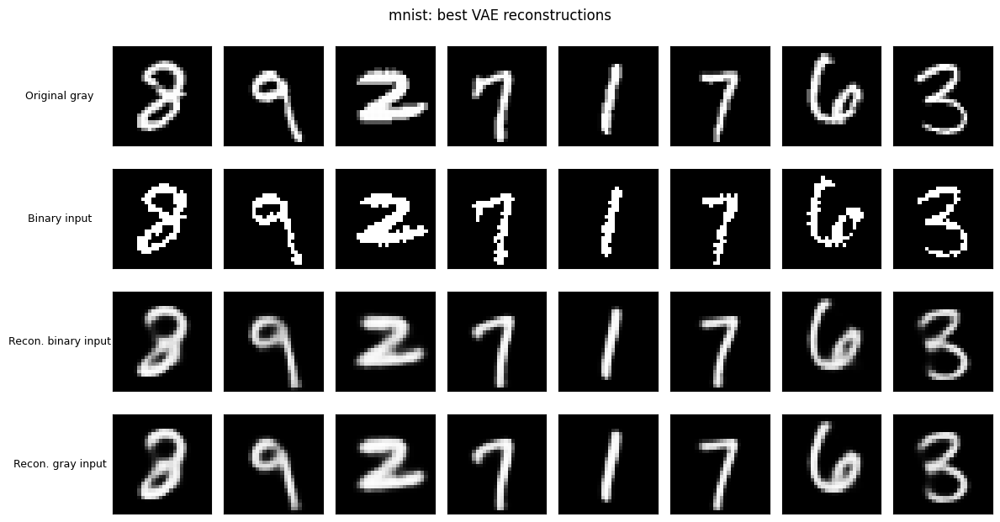

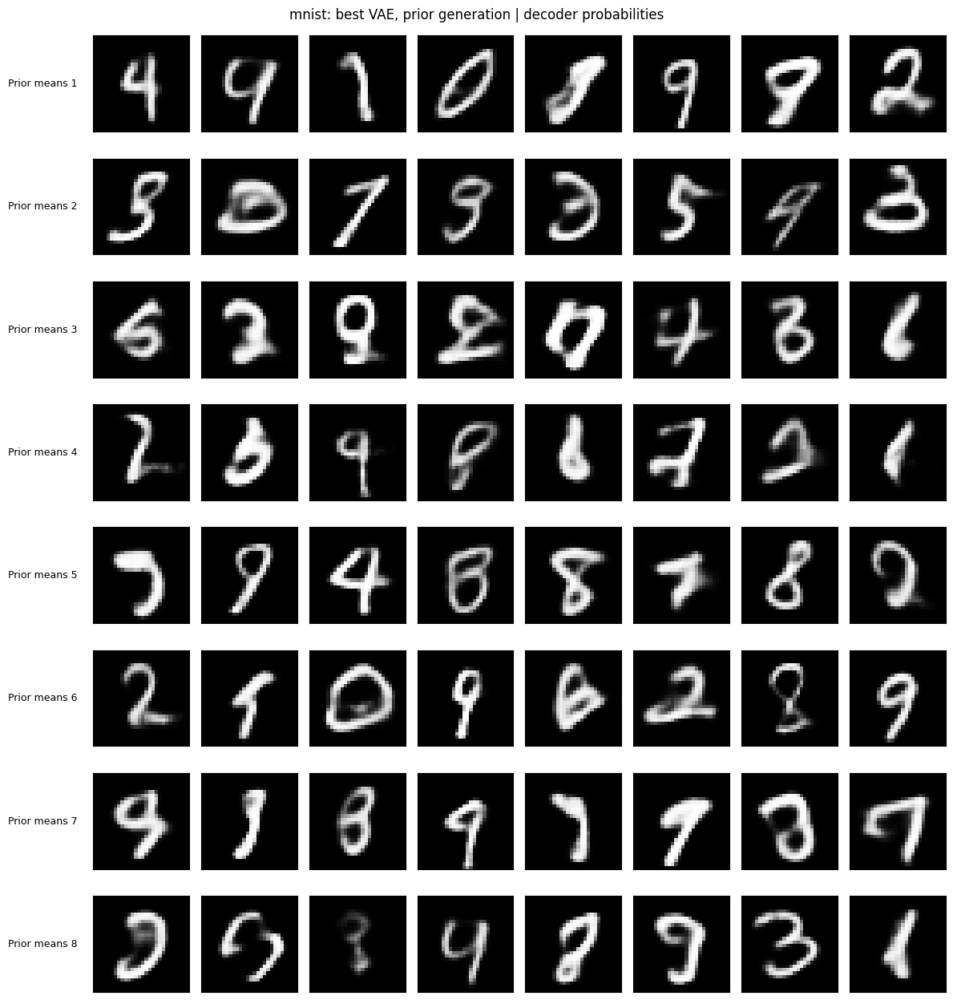

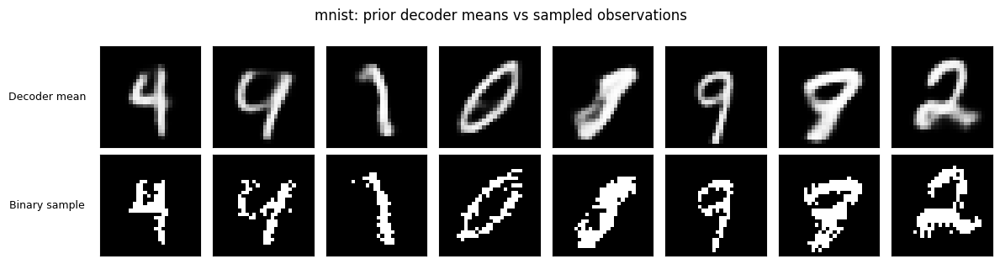

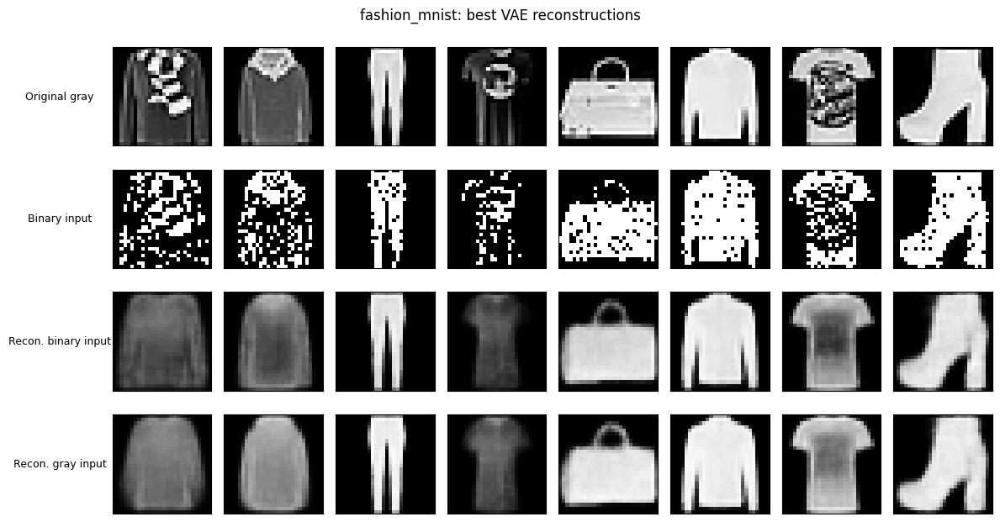

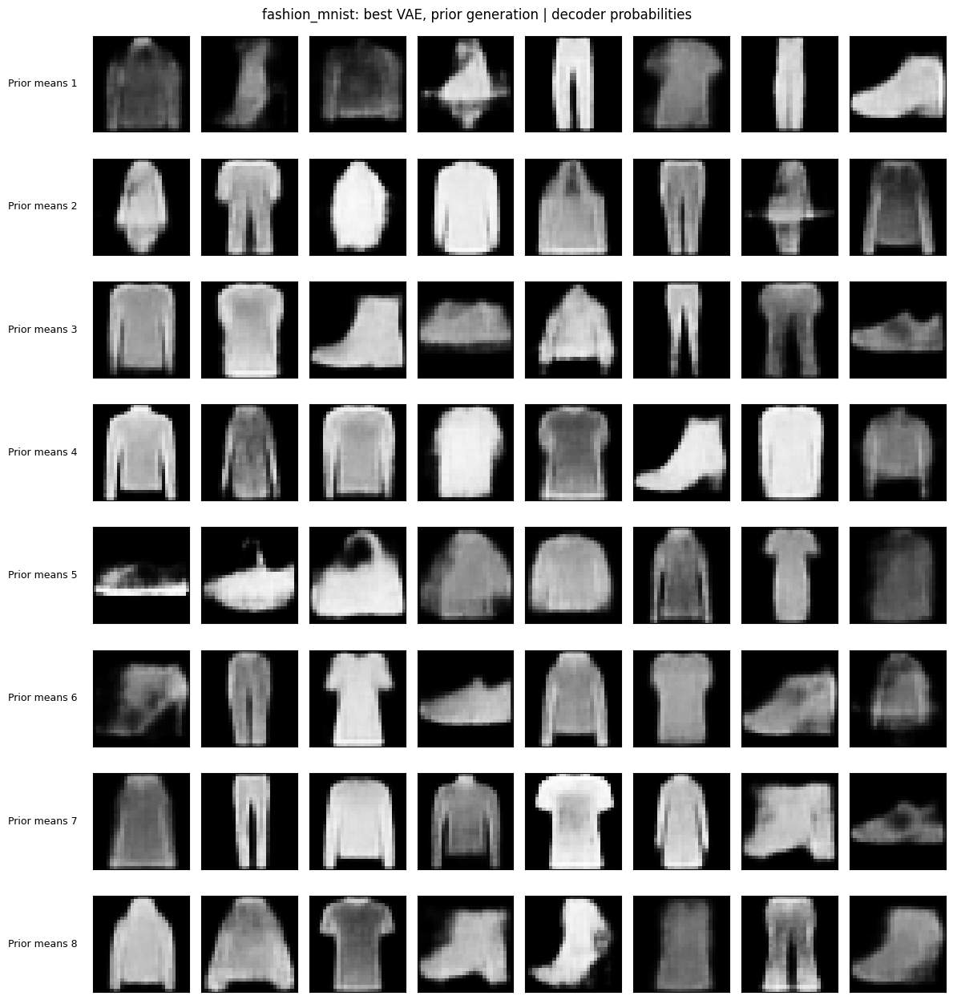

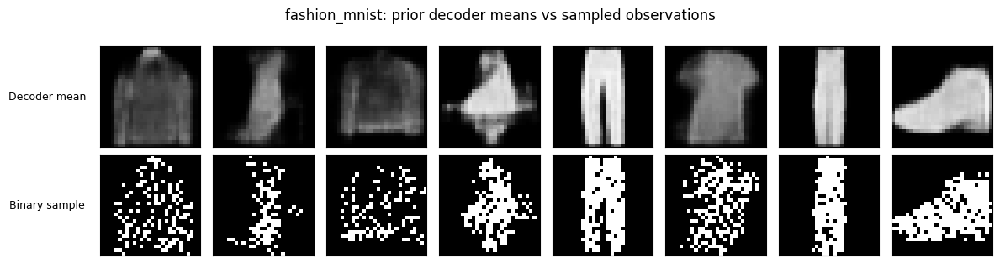

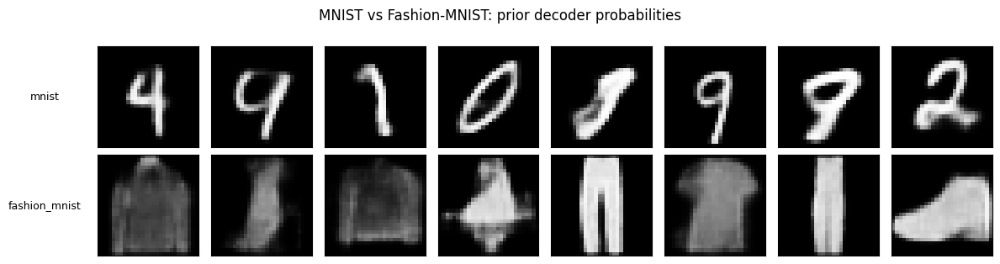

In [38]:
vae_generation_rows=[]
for run in vae_runs:
    dataset=run['dataset']
    model=ConvVAE(VAE_LATENT_DIM).to(DEVICE)
    model.load_state_dict(torch.load(run['checkpoint'],map_location=DEVICE,weights_only=True)['model'])
    model.eval()
    test_data=testing_loader(dataset).dataset
    indices=torch.randperm(len(test_data),generator=torch.Generator().manual_seed(123))[:8]
    examples=torch.stack([test_data[int(i)][0] for i in indices])
    vae_reconstruction_preview(model,examples,f'{dataset}: best VAE reconstructions',
                               VAE_RESULTS/f'{dataset}_best_reconstructions.png')
    probabilities,pixels=vae_sample_grid(model,f'{dataset}: best VAE, prior generation',
                                         VAE_RESULTS/f'{dataset}_prior_samples.png')
    vae_panel([('Decoder mean',probabilities[:8]),('Binary sample',pixels[:8])],
              dataset+': prior decoder means vs sampled observations',VAE_RESULTS/f'{dataset}_observation_samples.png')
    vae_generation_rows.append((dataset,probabilities[:8]))
vae_panel(vae_generation_rows,'MNIST vs Fashion-MNIST: prior decoder probabilities',
          VAE_RESULTS/'datasets_generation_comparison.png')


## Part 3: Flow-VAE — RealNVP in the latent posterior

Six conditional RealNVP coupling layers transformed the Gaussian approximate posterior. The convolutional encoder/decoder, standard normal prior and Bernoulli observation model were kept. A zero-flow control provided a matched comparison.


In [40]:
NF_LATENT_DIM = 32
NF_FLOW_LAYERS = 6
NF_HIDDEN_DIM = 128
NF_EPOCHS = 30
NF_LEARNING_RATE = 5e-4
NF_IMPORTANCE_SAMPLES = 16
NF_CONFIGS = [('standard_control',0),('flow_vae',NF_FLOW_LAYERS)]
NF_RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
NF_RESULTS = HW/'results'/'flow_vae'/('smoke' if SMOKE_TEST else 'full')/NF_RUN_ID
NF_CHECKPOINTS = ROOT/'.local'/'hw1'/'flow_vae'/'checkpoints'/NF_RUN_ID
NF_RESULTS.mkdir(parents=True,exist_ok=True)
NF_CHECKPOINTS.mkdir(parents=True,exist_ok=True)
(NF_RESULTS/'environment.json').write_text(json.dumps(environment,indent=2))
print('Flow-VAE results:',NF_RESULTS)


Flow-VAE results: c:\Users\Admin\Desktop\GEN_AI_CV\HW1\results\flow_vae\full\20261112T200136495498Z


### 3.1 Posterior transformation and objective

The encoder first sampled $z_0\sim q_0(z_0|x)=\mathcal N(\mu(x),\mathrm{diag}(\sigma^2(x)))$. Coupling layers then produced $z_K=f_K\circ\cdots\circ f_1(z_0;\mu(x),\log\sigma^2(x))$.

Each layer used masked coordinates and image-dependent context. The context was fixed when calculating the latent Jacobian, which remained triangular. Alternating masks allowed all coordinates to change.

$$\log q_K(z_K|x)=\log q_0(z_0|x)-\sum_k\log|\det J_{f_k}|.$$

Training used a Monte Carlo negative ELBO:

$$-\widehat{\mathrm{ELBO}}=-\log p_\theta(x|z_K)+\log q_K(z_K|x)-\log p(z_K).$$

The analytic Gaussian KL is not valid after the flow. Individual log-density ratios can be negative, so they were not clipped. The zero-flow control used the same estimator. Importance-weighted evaluation also included the transformed density and Jacobian.

Only the posterior changed. Generation sampled the standard normal prior and decoded it directly; the image-conditioned posterior flow was not applied to prior samples.


In [41]:
def diagonal_log_prob(z,mu,logvar):
    return -0.5*((z-mu).square()*torch.exp(-logvar)+logvar+math.log(2*math.pi)).sum(-1)
def standard_log_prob(z):
    return -0.5*(z.square()+math.log(2*math.pi)).sum(-1)

class LatentCoupling(nn.Module):
    def __init__(self,dim,hidden,flip=False):
        super().__init__()
        mask=(torch.arange(dim)%2).float()[None]
        self.register_buffer('mask',1-mask if flip else mask)
        # Input: masked z (d) plus posterior mean and log-variance (2d).
        self.net=nn.Sequential(nn.Linear(3*dim,hidden),nn.SiLU(),
                               nn.Linear(hidden,hidden),nn.SiLU(),nn.Linear(hidden,2*dim))
        nn.init.zeros_(self.net[-1].weight)
        nn.init.zeros_(self.net[-1].bias)
    def st(self,fixed,context):
        s,t=self.net(torch.cat([fixed,context],dim=1)).chunk(2,dim=1)
        return 0.8*torch.tanh(s)*(1-self.mask),t*(1-self.mask)
    def forward(self,z,context):
        s,t=self.st(z*self.mask,context)
        return z*torch.exp(s)+t,s.sum(1)
    def inverse(self,y,context):
        s,t=self.st(y*self.mask,context)
        return (y-t)*torch.exp(-s)

class LatentRealNVP(nn.Module):
    def __init__(self,dim,layers=6,hidden=128):
        super().__init__()
        self.layers=nn.ModuleList([LatentCoupling(dim,hidden,bool(i%2)) for i in range(layers)])
    def forward(self,z,context):
        ldj=z.new_zeros(len(z))
        for layer in self.layers:
            z,delta=layer(z,context)
            ldj=ldj+delta
        return z,ldj
    def inverse(self,z,context):
        for layer in reversed(self.layers): z=layer.inverse(z,context)
        return z

class FlowVAE(ConvVAE):
    def __init__(self,latent_dim=32,flow_layers=6,flow_hidden=128):
        super().__init__(latent_dim)
        self.posterior_flow=LatentRealNVP(latent_dim,flow_layers,flow_hidden)
    def draw_posterior(self,mu,logvar,generator=None):
        z0=self.reparameterize(mu,logvar,generator)
        context=torch.cat([mu,logvar],dim=1)
        z,ldj=self.posterior_flow(z0,context)
        log_q=diagonal_log_prob(z0,mu,logvar)-ldj
        return z,log_q,standard_log_prob(z)
    def forward(self,x,generator=None):
        mu,logvar=self.encode(x)
        z,log_q,log_p=self.draw_posterior(mu,logvar,generator)
        return self.decode(z),log_q,log_p
    def representative_reconstruction(self,x):
        mu,logvar=self.encode(x)
        proxy,_=self.posterior_flow(mu,torch.cat([mu,logvar],dim=1))
        return torch.sigmoid(self.decode(proxy))
    # Prior sampling is inherited from ConvVAE: z~N(0,I), then decode.


### 3.2 Numerical checks

The checks covered coupling inversion, the analytic log-Jacobian, finite gradients and agreement of the zero-flow density calculation with the Gaussian case. Saved outputs below record the results.


In [42]:
def check_flow_vae():
    flow=LatentRealNVP(4,layers=4,hidden=8).double()
    for layer in flow.layers: nn.init.normal_(layer.net[-1].weight,std=0.03)
    z0=torch.randn(2,4,dtype=torch.float64)
    context=torch.randn(2,8,dtype=torch.float64)
    z,ldj=flow(z0,context)
    torch.testing.assert_close(flow.inverse(z,context),z0)
    jac=torch.autograd.functional.jacobian(lambda t:flow(t[None],context[:1])[0][0],z0[0])
    torch.testing.assert_close(ldj[0],torch.linalg.slogdet(jac)[1])
    mu,lv=context.chunk(2,1)
    log_q=diagonal_log_prob(z0,mu,lv)-ldj
    inverse=flow.inverse(z,context)
    _,inverse_forward_ldj=flow(inverse,context)
    torch.testing.assert_close(log_q,diagonal_log_prob(inverse,mu,lv)-inverse_forward_ldj)
    identity=LatentRealNVP(4,layers=4,hidden=8).double()
    same,zero=identity(z0,context)
    torch.testing.assert_close(same,z0)
    torch.testing.assert_close(zero,torch.zeros(2,dtype=torch.float64))
    for layers in (0,4):
        model=FlowVAE(latent_dim=4,flow_layers=layers,flow_hidden=8)
        # q0=N(0,I) and identity flow must give log q == log p sample by sample.
        mu=torch.zeros(3,4)
        lv=torch.zeros_like(mu)
        _,log_q,log_p=model.draw_posterior(mu,lv,torch.Generator().manual_seed(1))
        torch.testing.assert_close(log_q,log_p)
        x=torch.randint(0,2,(3,1,28,28)).float()
        logits,log_q,log_p=model(x)
        recon=F.binary_cross_entropy_with_logits(logits,x,reduction='none').flatten(1).sum(1)
        (recon+log_q-log_p).mean().backward()
        assert all(p.grad is not None and torch.isfinite(p.grad).all() for p in model.parameters())
    print('Passed: conditional inverse/Jacobian, q density, identity/zero-flow behavior and gradients.')
check_flow_vae()


Passed: conditional inverse/Jacobian, q density, identity/zero-flow behavior and gradients.


In [43]:
@torch.no_grad()
def evaluate_flow_vae(model,loader,importance_samples=1,seed=2026):
    model.eval()
    binary_rng=torch.Generator(device=DEVICE).manual_seed(seed)
    latent_rng=torch.Generator(device=DEVICE).manual_seed(seed+1)
    totals=dict(reconstruction_nll=0.,kl_mc=0.,negative_elbo=0.,negative_iwae_estimate=0.,gray_mse=0.)
    count=0
    for gray,_ in loader:
        gray=gray.to(DEVICE)
        x=torch.bernoulli(gray,generator=binary_rng)
        mu,logvar=model.encode(x)
        recon_total=torch.zeros(len(x),device=DEVICE)
        ratio_total=torch.zeros_like(recon_total)
        log_weights=[]
        for _ in range(importance_samples):
            z,log_q,log_p=model.draw_posterior(mu,logvar,latent_rng)
            logits=model.decode(z)
            recon=F.binary_cross_entropy_with_logits(logits,x,reduction='none').flatten(1).sum(1)
            recon_total+=recon
            ratio_total+=log_q-log_p
            log_weights.append(-recon+log_p-log_q)
        reconstruction=recon_total/importance_samples
        ratio=ratio_total/importance_samples
        negative_iw=-(torch.logsumexp(torch.stack(log_weights),dim=0)-math.log(importance_samples))
        gray_mse=(model.representative_reconstruction(gray)-gray).square().flatten(1).mean(1)
        values=dict(reconstruction_nll=reconstruction,kl_mc=ratio,negative_elbo=reconstruction+ratio,
                    negative_iwae_estimate=negative_iw,gray_mse=gray_mse)
        for key,value in values.items():
            if not torch.isfinite(value).all(): raise FloatingPointError(f'Non-finite {key}')
            totals[key]+=value.sum().item()
        count+=len(gray)
    return {key:value/count for key,value in totals.items()}

@torch.no_grad()
def flow_reconstruction_preview(model,gray,title,path):
    model.eval()
    gray=gray.to(DEVICE)
    generator=torch.Generator(device=DEVICE).manual_seed(1234)
    binary=torch.bernoulli(gray,generator=generator)
    vae_panel([('Original gray',gray),('Binary input',binary),
               ('Recon. binary proxy',model.representative_reconstruction(binary)),
               ('Recon. gray proxy',model.representative_reconstruction(gray))],title,path)


### 3.3 Matched training

The zero-flow control and six-flow VAE were trained from scratch for 30 epochs on both datasets. Both used latent size 32, the same backbone and splits, Adam at 5e-4, gradient clipping at 5, and one posterior sample per training image. Checkpoints were selected by validation negative ELBO.


mnist standard_control | 1/30 | train -ELBO 218.93, val 166.07 | MC KL 11.01 | 1.6s


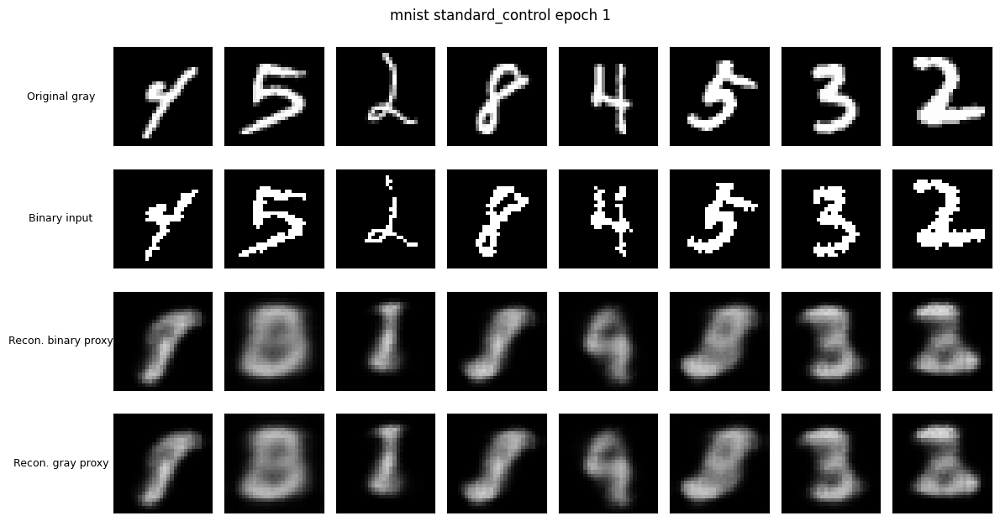

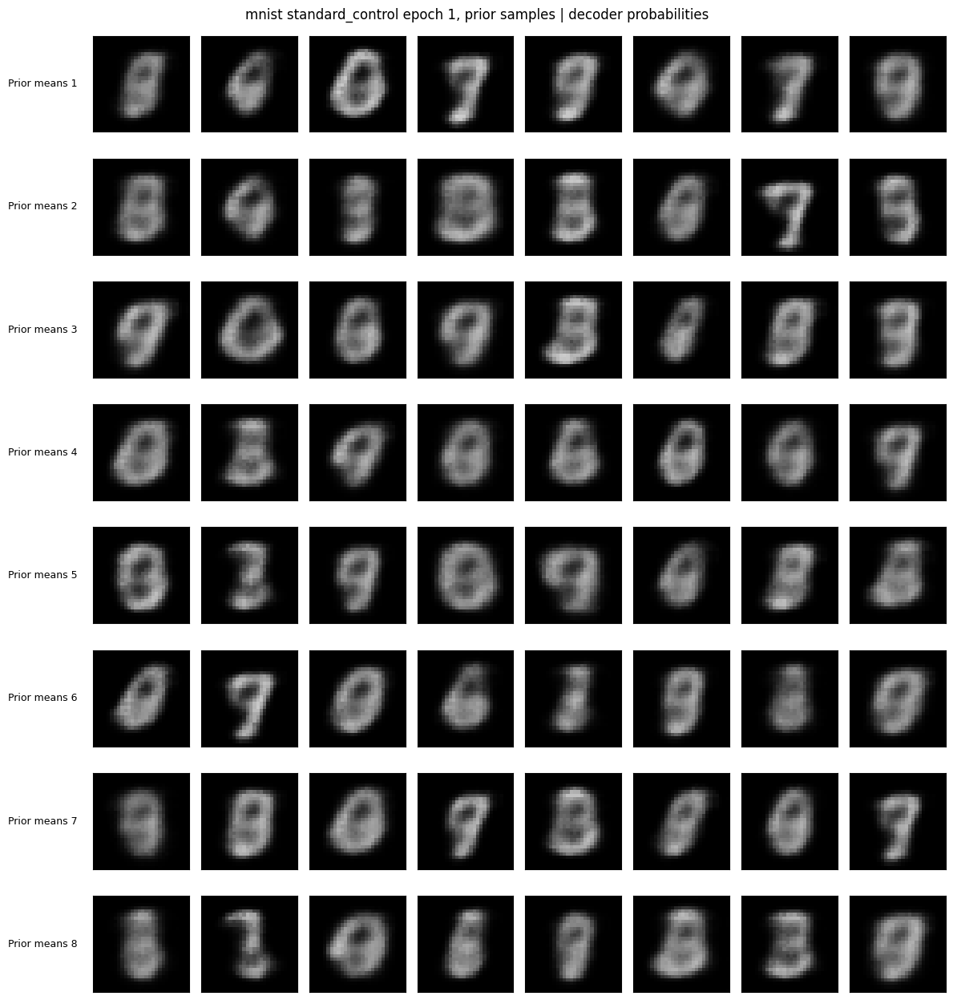

mnist standard_control | 2/30 | train -ELBO 150.68, val 139.19 | MC KL 17.75 | 1.6s
mnist standard_control | 3/30 | train -ELBO 133.46, val 128.35 | MC KL 19.98 | 1.6s
mnist standard_control | 4/30 | train -ELBO 124.38, val 121.17 | MC KL 21.73 | 1.6s
mnist standard_control | 5/30 | train -ELBO 118.60, val 116.89 | MC KL 22.23 | 1.6s
mnist standard_control | 6/30 | train -ELBO 114.30, val 112.64 | MC KL 23.20 | 1.5s
mnist standard_control | 7/30 | train -ELBO 111.22, val 109.76 | MC KL 23.32 | 1.5s
mnist standard_control | 8/30 | train -ELBO 108.64, val 107.63 | MC KL 23.71 | 1.5s
mnist standard_control | 9/30 | train -ELBO 106.64, val 105.83 | MC KL 23.61 | 1.5s
mnist standard_control | 10/30 | train -ELBO 105.07, val 104.31 | MC KL 24.14 | 1.5s


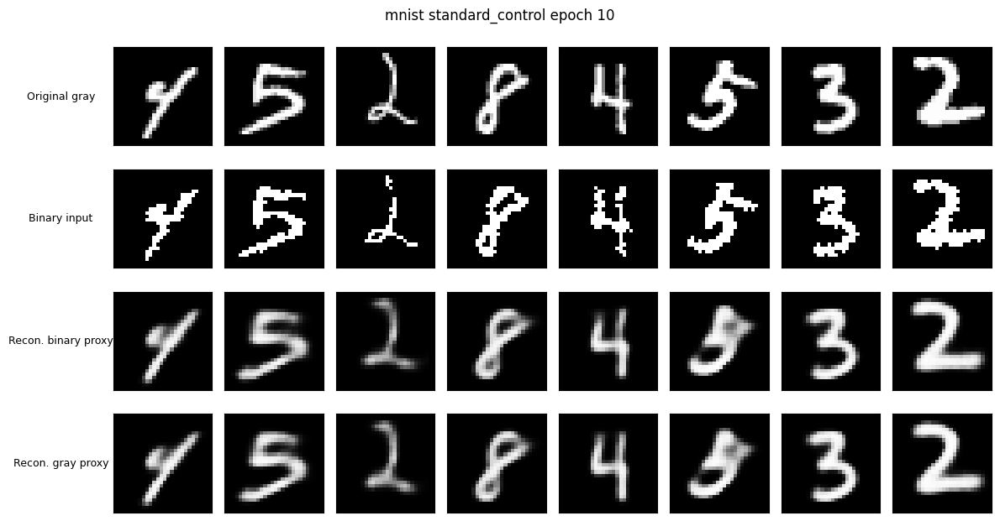

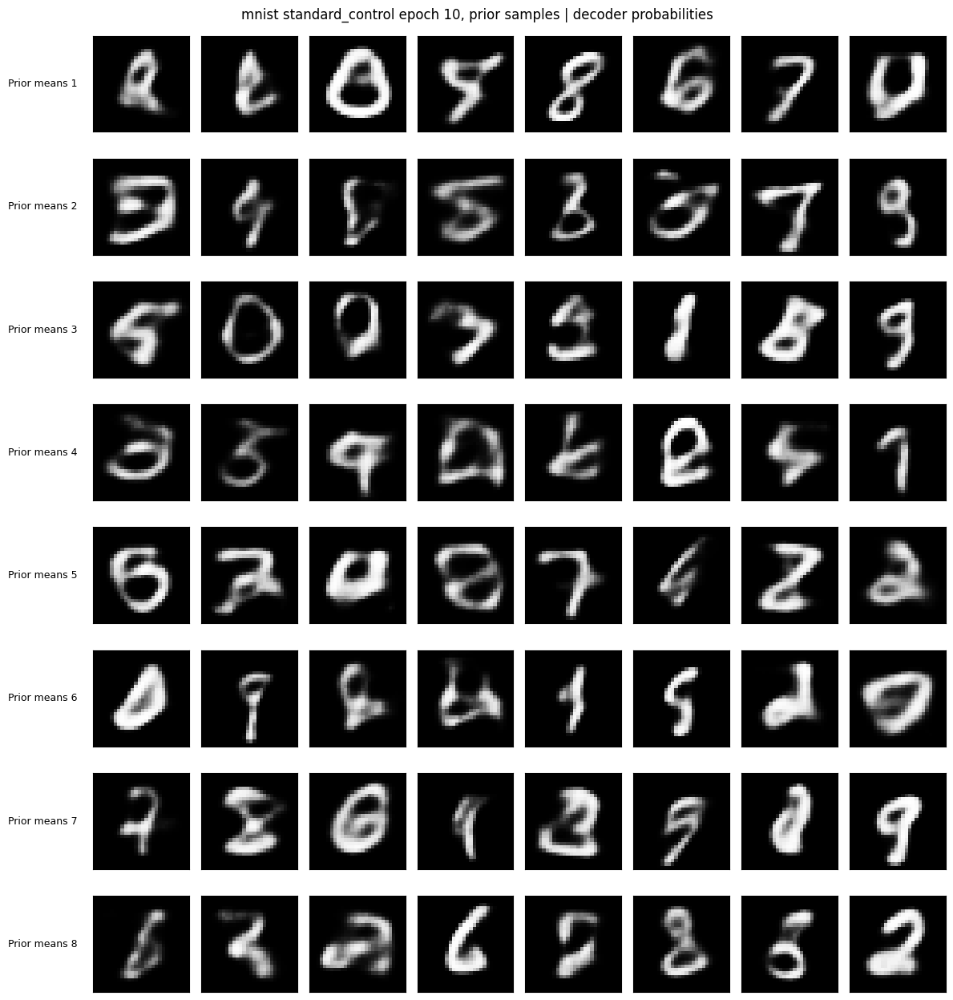

mnist standard_control | 11/30 | train -ELBO 103.70, val 103.28 | MC KL 24.34 | 1.5s
mnist standard_control | 12/30 | train -ELBO 102.52, val 102.15 | MC KL 24.69 | 1.5s
mnist standard_control | 13/30 | train -ELBO 101.61, val 101.31 | MC KL 24.89 | 1.5s
mnist standard_control | 14/30 | train -ELBO 100.73, val 100.81 | MC KL 24.16 | 1.5s
mnist standard_control | 15/30 | train -ELBO 100.07, val 100.05 | MC KL 24.73 | 1.5s
mnist standard_control | 16/30 | train -ELBO 99.61, val 99.27 | MC KL 25.31 | 1.5s
mnist standard_control | 17/30 | train -ELBO 99.01, val 98.81 | MC KL 25.28 | 1.5s
mnist standard_control | 18/30 | train -ELBO 98.65, val 98.85 | MC KL 25.06 | 1.5s
mnist standard_control | 19/30 | train -ELBO 98.16, val 98.25 | MC KL 25.29 | 1.5s
mnist standard_control | 20/30 | train -ELBO 97.78, val 97.95 | MC KL 25.41 | 1.5s


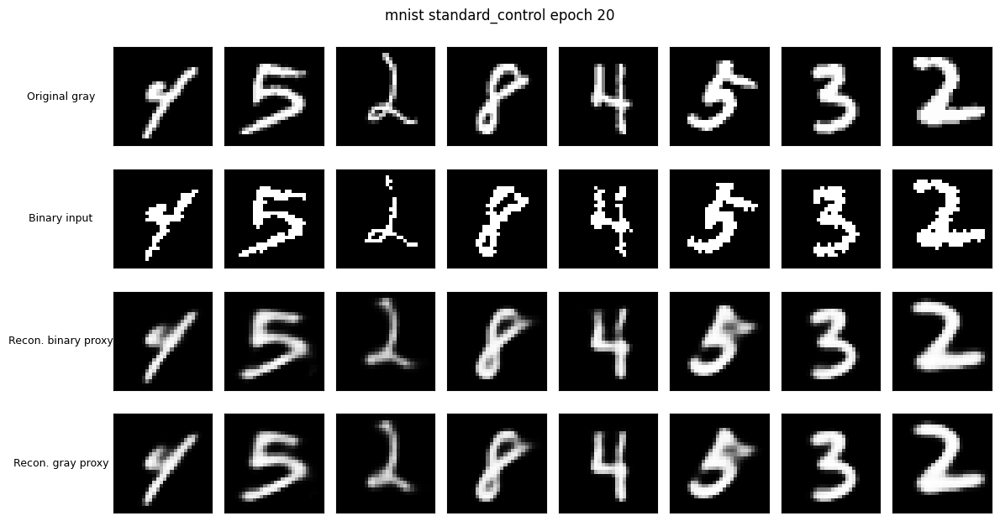

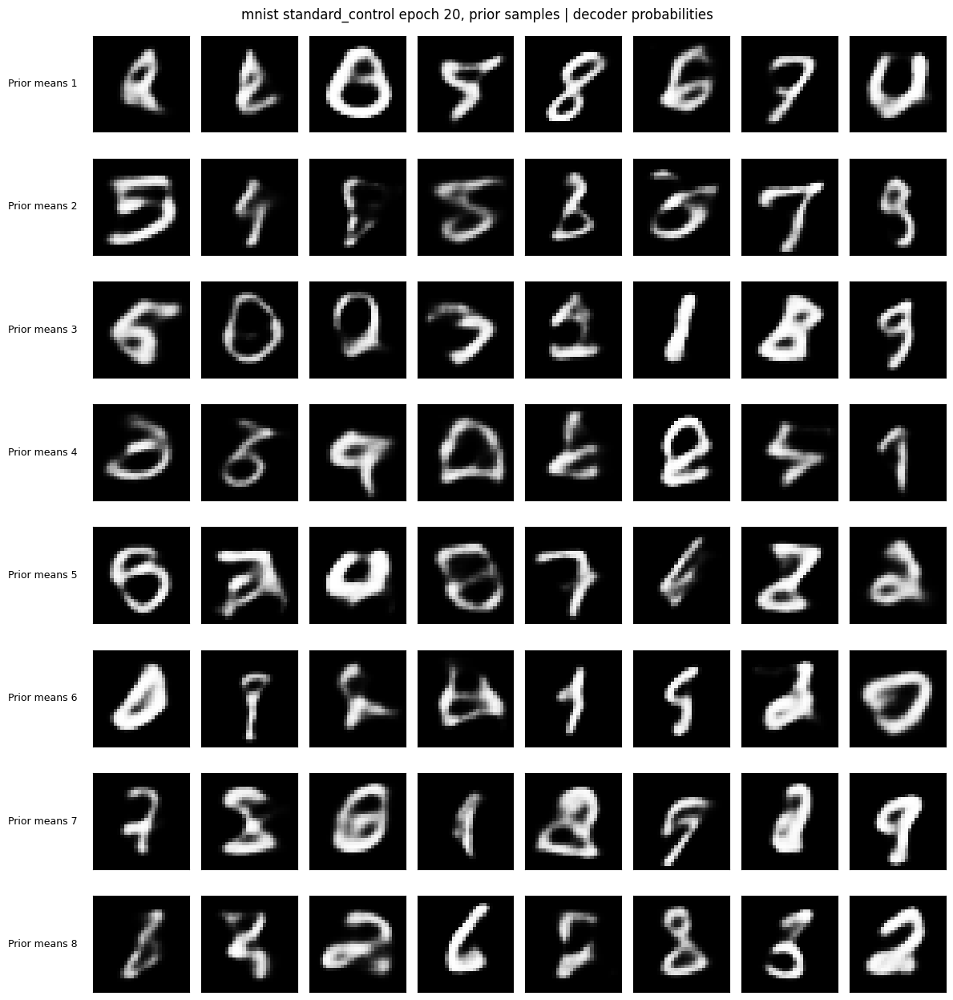

mnist standard_control | 21/30 | train -ELBO 97.55, val 97.48 | MC KL 24.82 | 1.6s
mnist standard_control | 22/30 | train -ELBO 97.23, val 97.46 | MC KL 25.28 | 1.6s
mnist standard_control | 23/30 | train -ELBO 96.92, val 97.31 | MC KL 26.04 | 1.5s
mnist standard_control | 24/30 | train -ELBO 96.65, val 97.10 | MC KL 25.65 | 1.5s
mnist standard_control | 25/30 | train -ELBO 96.57, val 97.07 | MC KL 25.47 | 1.5s
mnist standard_control | 26/30 | train -ELBO 96.28, val 96.94 | MC KL 25.49 | 1.5s
mnist standard_control | 27/30 | train -ELBO 96.07, val 96.82 | MC KL 25.76 | 1.6s
mnist standard_control | 28/30 | train -ELBO 95.91, val 96.40 | MC KL 25.78 | 1.5s
mnist standard_control | 29/30 | train -ELBO 95.67, val 95.92 | MC KL 25.78 | 1.6s
mnist standard_control | 30/30 | train -ELBO 95.51, val 96.07 | MC KL 25.41 | 1.5s


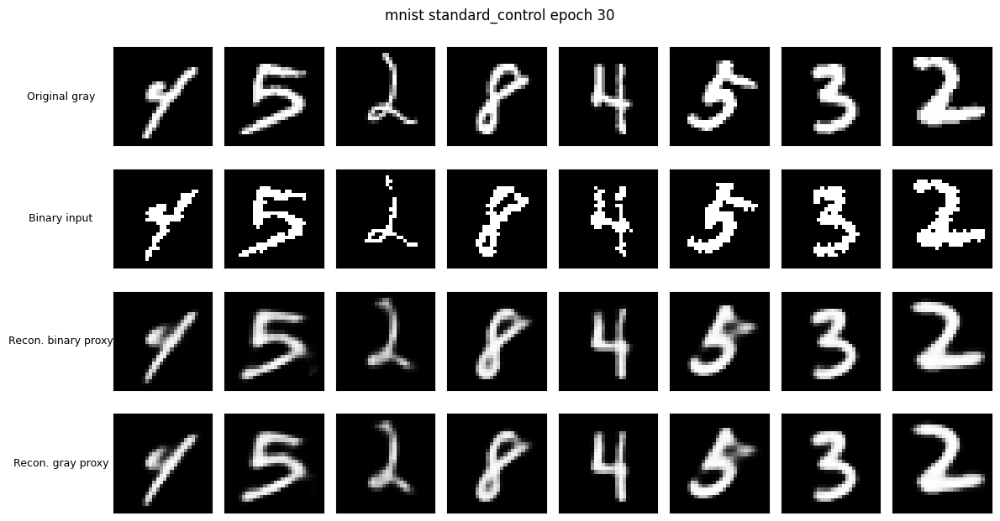

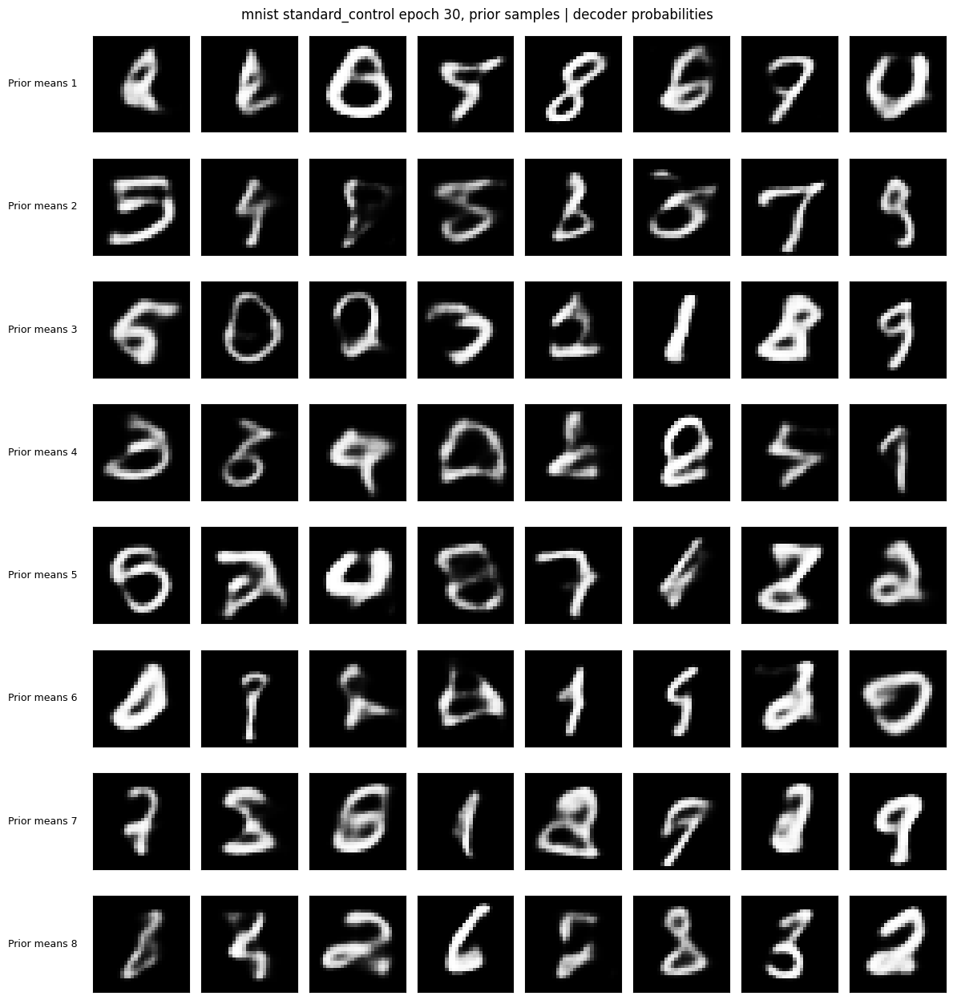

mnist flow_vae | 1/30 | train -ELBO 218.18, val 165.91 | MC KL 9.17 | 2.9s


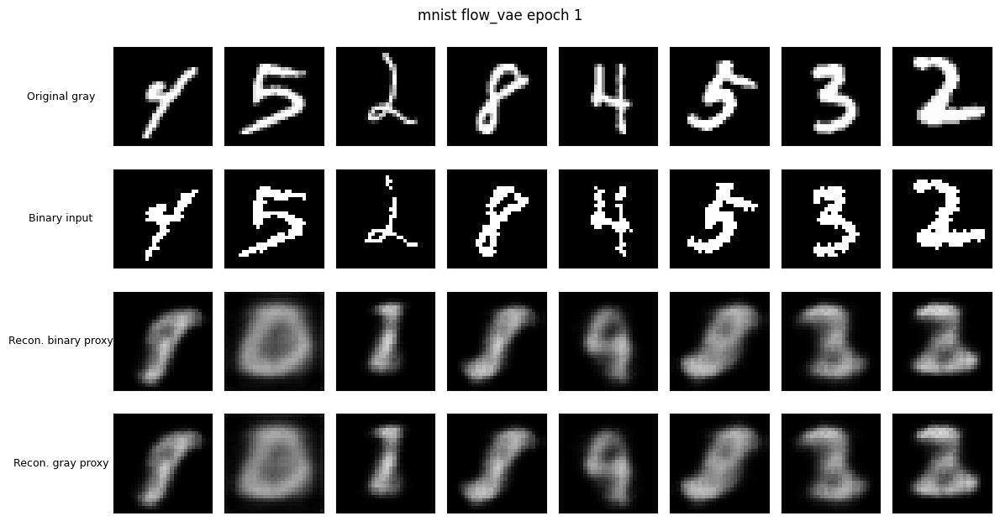

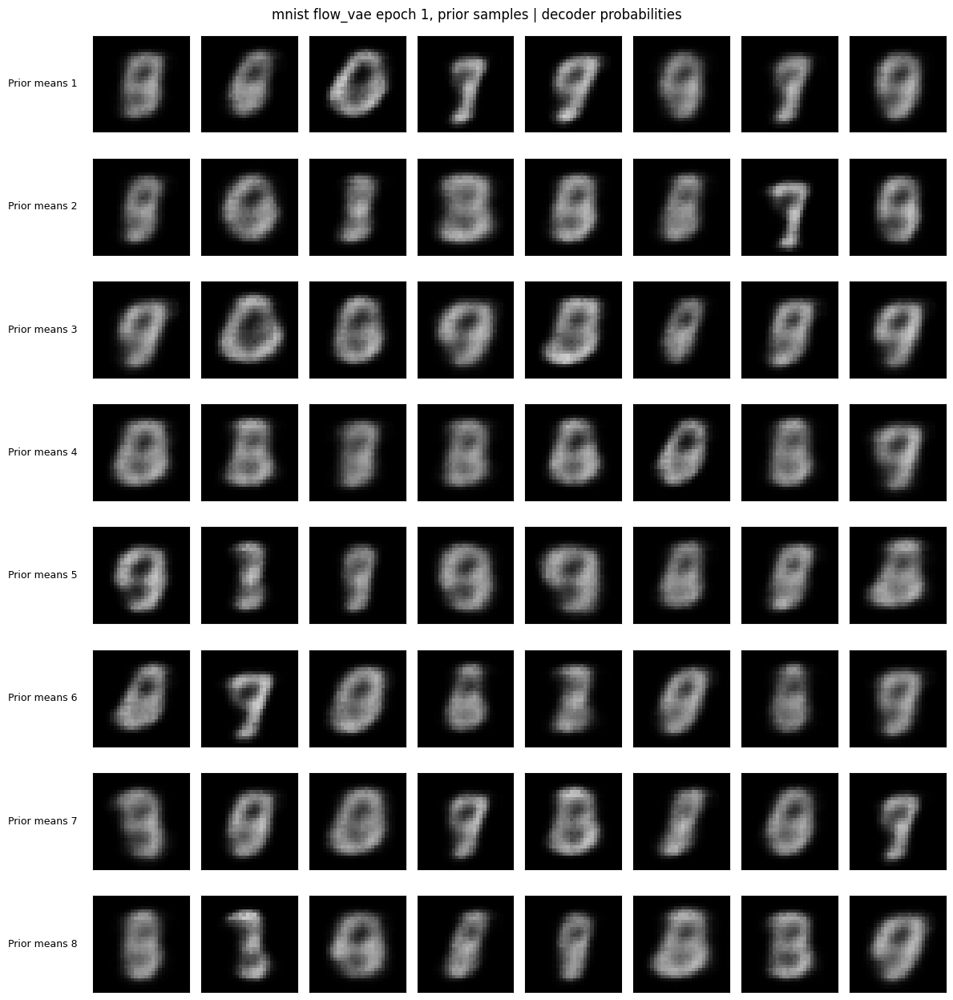

mnist flow_vae | 2/30 | train -ELBO 149.41, val 137.20 | MC KL 14.26 | 3.7s
mnist flow_vae | 3/30 | train -ELBO 131.78, val 126.12 | MC KL 16.43 | 3.7s
mnist flow_vae | 4/30 | train -ELBO 121.85, val 119.02 | MC KL 18.13 | 3.8s
mnist flow_vae | 5/30 | train -ELBO 116.48, val 114.39 | MC KL 18.55 | 3.7s
mnist flow_vae | 6/30 | train -ELBO 112.66, val 111.41 | MC KL 19.21 | 3.6s
mnist flow_vae | 7/30 | train -ELBO 109.90, val 108.92 | MC KL 19.83 | 3.7s
mnist flow_vae | 8/30 | train -ELBO 107.63, val 106.75 | MC KL 20.44 | 3.7s
mnist flow_vae | 9/30 | train -ELBO 105.85, val 105.40 | MC KL 20.82 | 3.7s
mnist flow_vae | 10/30 | train -ELBO 104.24, val 103.88 | MC KL 21.09 | 3.7s


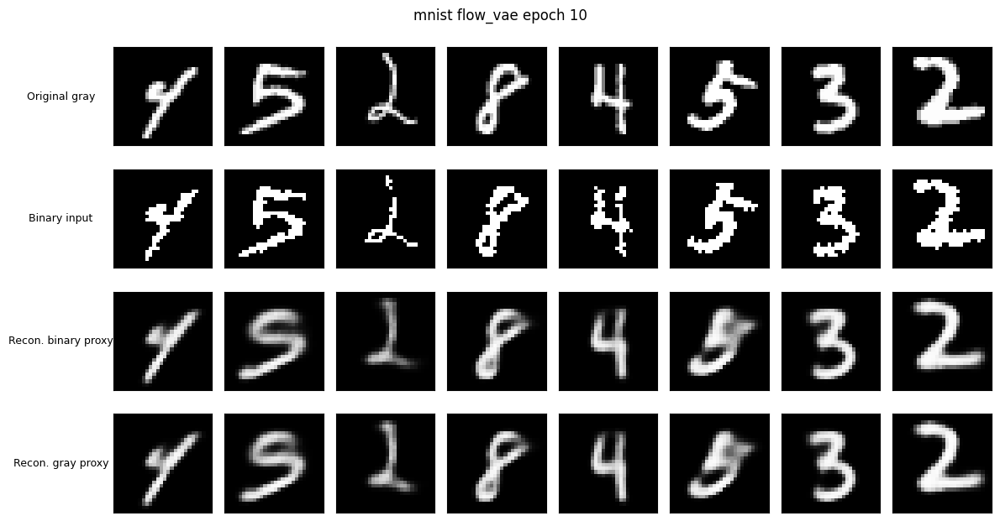

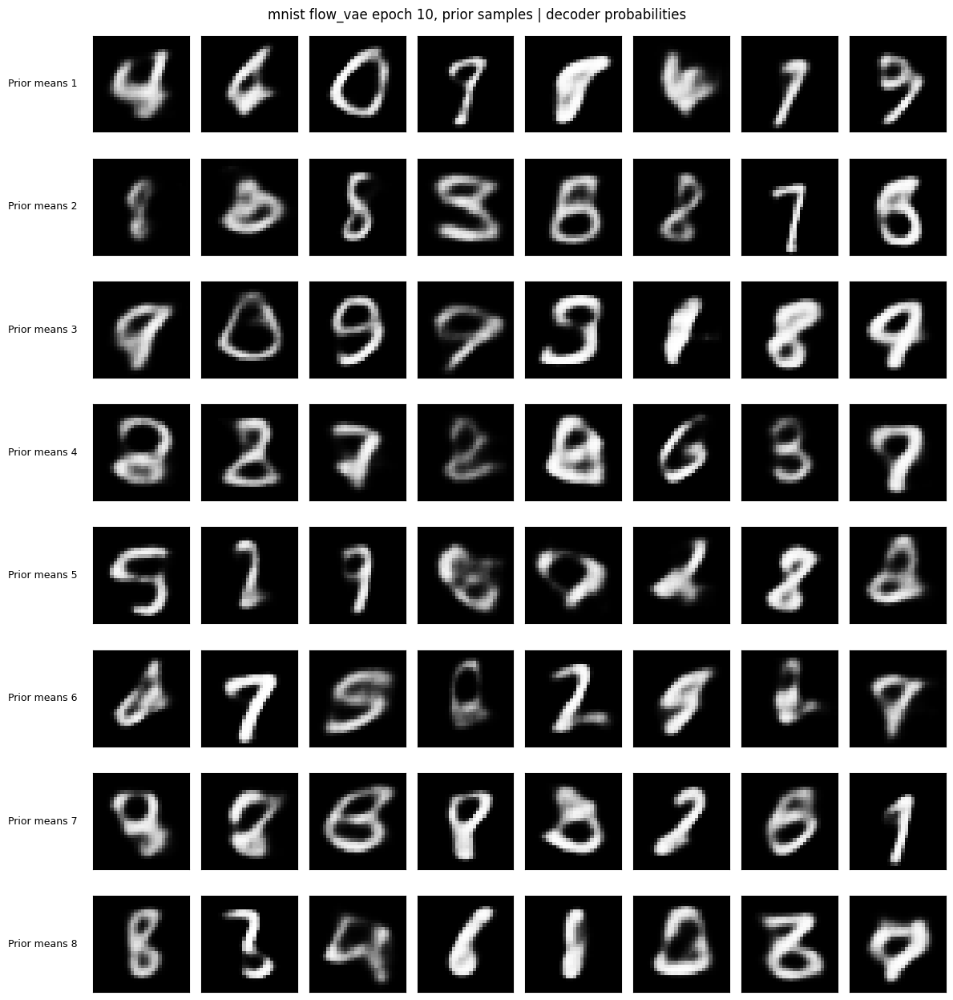

mnist flow_vae | 11/30 | train -ELBO 102.96, val 103.19 | MC KL 21.68 | 3.7s
mnist flow_vae | 12/30 | train -ELBO 101.89, val 101.59 | MC KL 21.97 | 3.7s
mnist flow_vae | 13/30 | train -ELBO 100.97, val 101.04 | MC KL 22.10 | 3.7s
mnist flow_vae | 14/30 | train -ELBO 100.08, val 100.03 | MC KL 22.06 | 3.6s
mnist flow_vae | 15/30 | train -ELBO 99.32, val 99.90 | MC KL 21.84 | 3.6s
mnist flow_vae | 16/30 | train -ELBO 98.78, val 99.21 | MC KL 22.44 | 3.6s
mnist flow_vae | 17/30 | train -ELBO 98.21, val 98.14 | MC KL 22.51 | 3.7s
mnist flow_vae | 18/30 | train -ELBO 97.78, val 97.96 | MC KL 22.91 | 3.6s
mnist flow_vae | 19/30 | train -ELBO 97.25, val 97.27 | MC KL 23.05 | 3.7s
mnist flow_vae | 20/30 | train -ELBO 96.83, val 96.86 | MC KL 22.66 | 3.6s


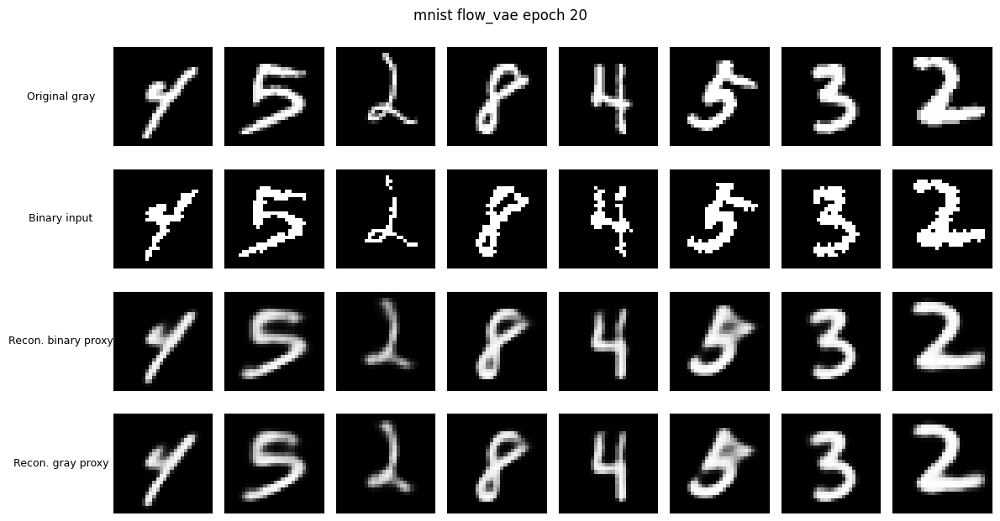

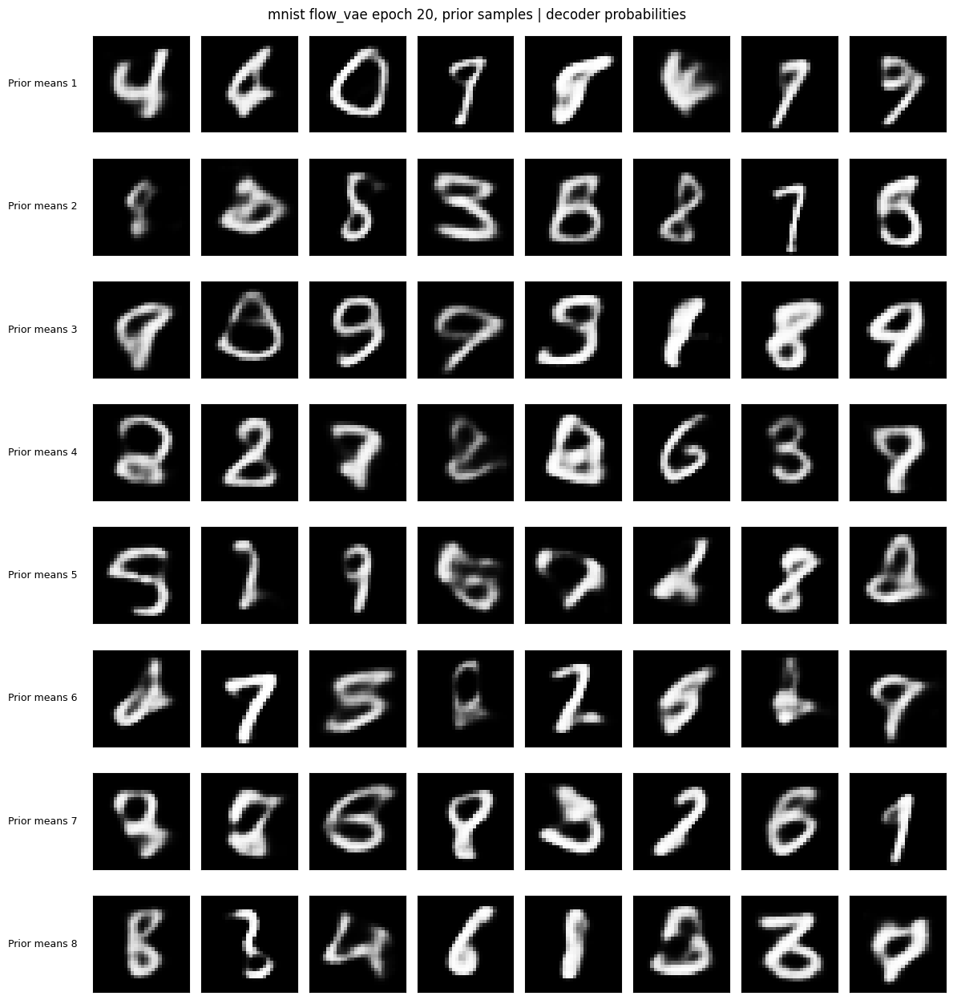

mnist flow_vae | 21/30 | train -ELBO 96.47, val 96.95 | MC KL 22.77 | 3.6s
mnist flow_vae | 22/30 | train -ELBO 96.08, val 96.41 | MC KL 22.92 | 3.6s
mnist flow_vae | 23/30 | train -ELBO 95.71, val 96.65 | MC KL 23.09 | 3.6s
mnist flow_vae | 24/30 | train -ELBO 95.43, val 95.59 | MC KL 23.12 | 3.6s
mnist flow_vae | 25/30 | train -ELBO 95.20, val 95.79 | MC KL 22.82 | 3.6s
mnist flow_vae | 26/30 | train -ELBO 94.89, val 95.32 | MC KL 23.16 | 3.5s
mnist flow_vae | 27/30 | train -ELBO 94.64, val 95.36 | MC KL 23.16 | 3.6s
mnist flow_vae | 28/30 | train -ELBO 94.37, val 95.15 | MC KL 23.22 | 3.6s
mnist flow_vae | 29/30 | train -ELBO 94.20, val 94.66 | MC KL 23.32 | 3.6s
mnist flow_vae | 30/30 | train -ELBO 93.92, val 94.13 | MC KL 23.40 | 3.7s


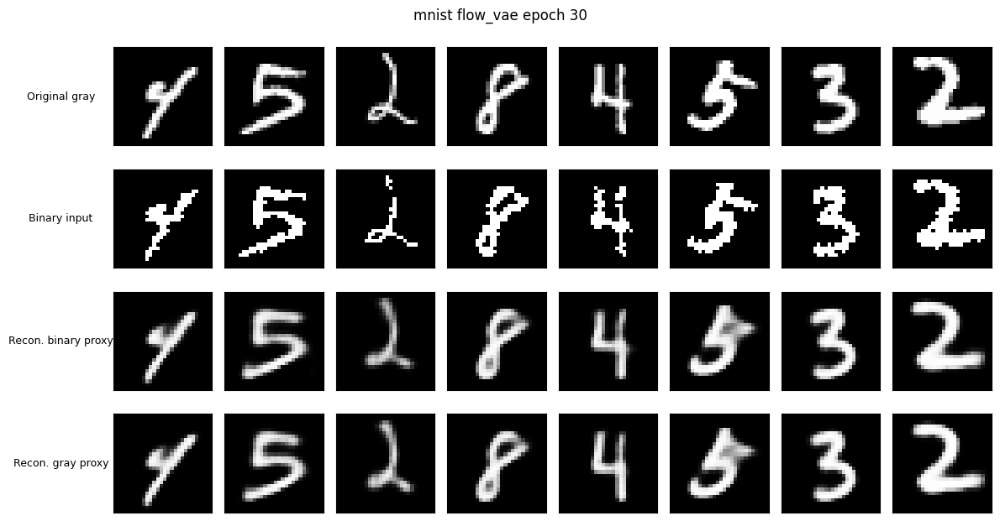

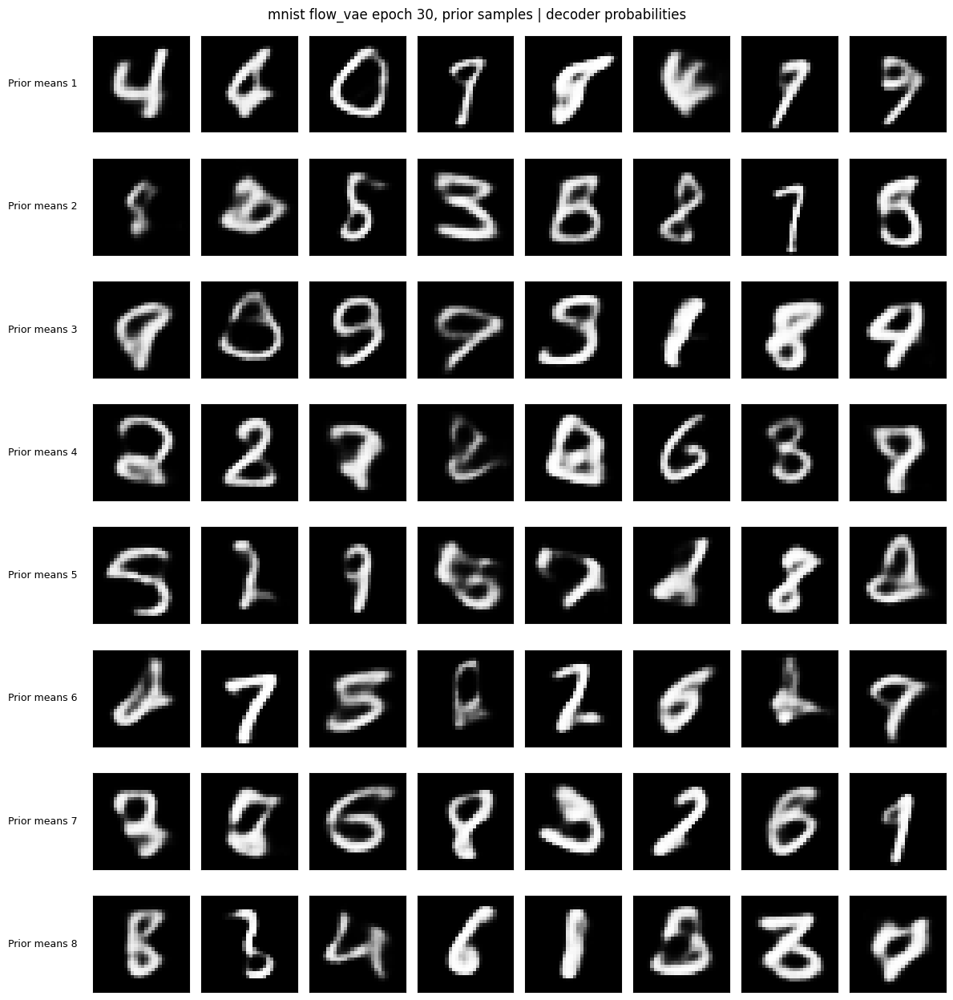

fashion_mnist standard_control | 1/30 | train -ELBO 336.55, val 281.70 | MC KL 13.22 | 1.7s


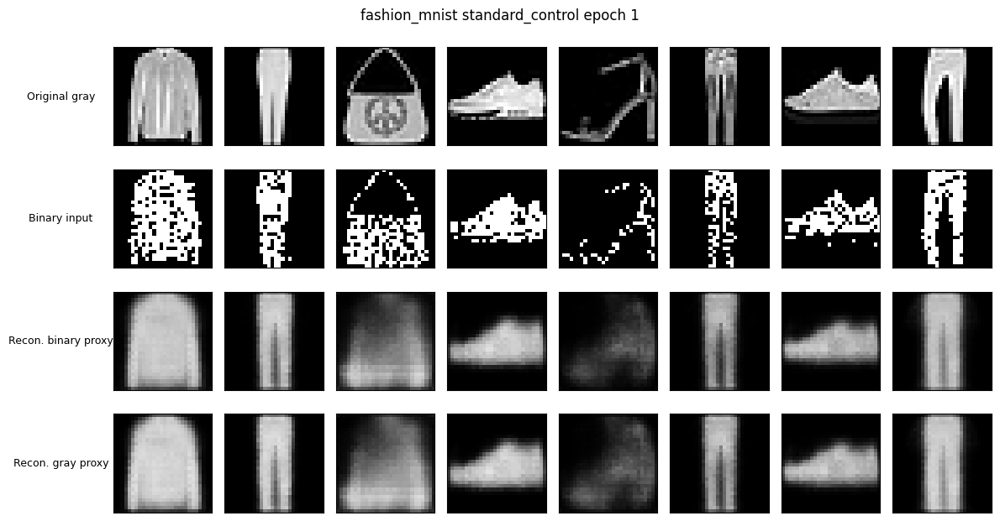

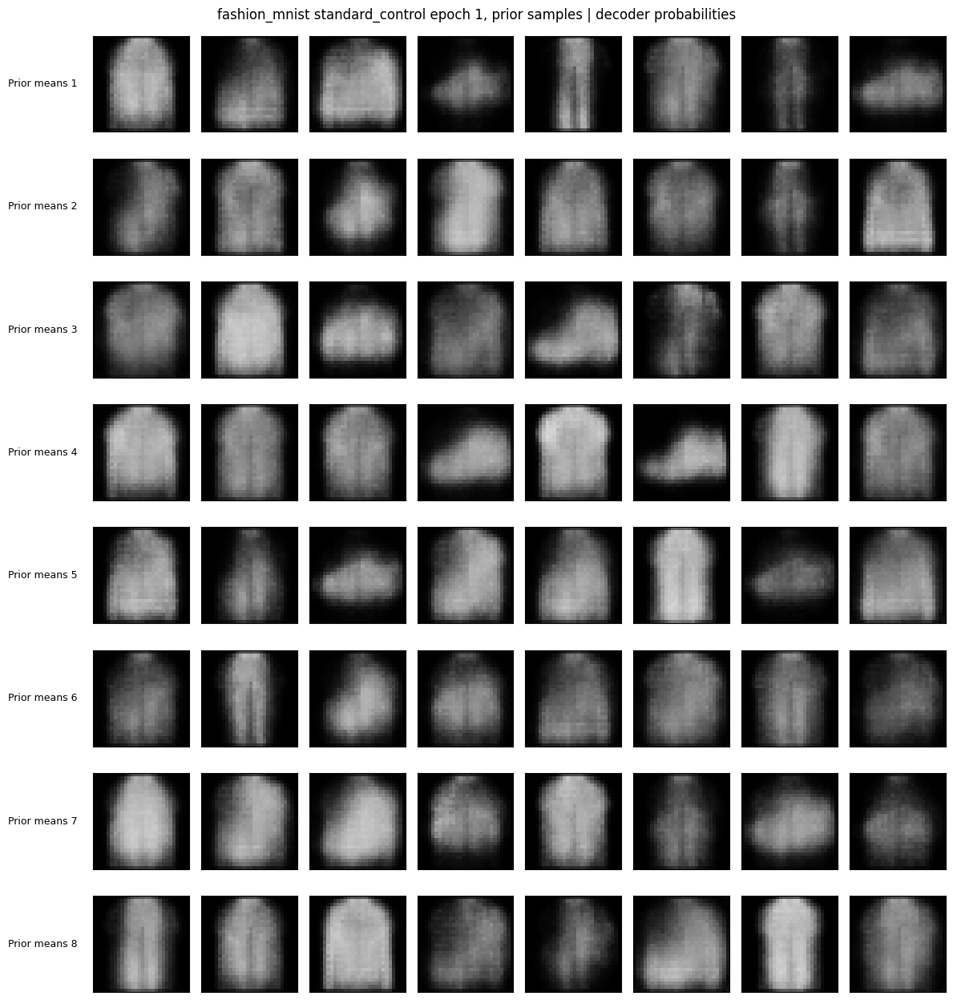

fashion_mnist standard_control | 2/30 | train -ELBO 269.71, val 264.87 | MC KL 14.06 | 1.5s
fashion_mnist standard_control | 3/30 | train -ELBO 260.17, val 258.19 | MC KL 13.59 | 1.5s
fashion_mnist standard_control | 4/30 | train -ELBO 254.62, val 253.21 | MC KL 13.51 | 1.4s
fashion_mnist standard_control | 5/30 | train -ELBO 251.04, val 250.15 | MC KL 13.23 | 1.5s
fashion_mnist standard_control | 6/30 | train -ELBO 248.44, val 248.97 | MC KL 13.38 | 1.5s
fashion_mnist standard_control | 7/30 | train -ELBO 246.94, val 247.11 | MC KL 13.71 | 1.5s
fashion_mnist standard_control | 8/30 | train -ELBO 245.45, val 245.84 | MC KL 13.91 | 1.4s
fashion_mnist standard_control | 9/30 | train -ELBO 244.32, val 244.68 | MC KL 13.86 | 1.5s
fashion_mnist standard_control | 10/30 | train -ELBO 243.27, val 243.80 | MC KL 13.91 | 1.5s


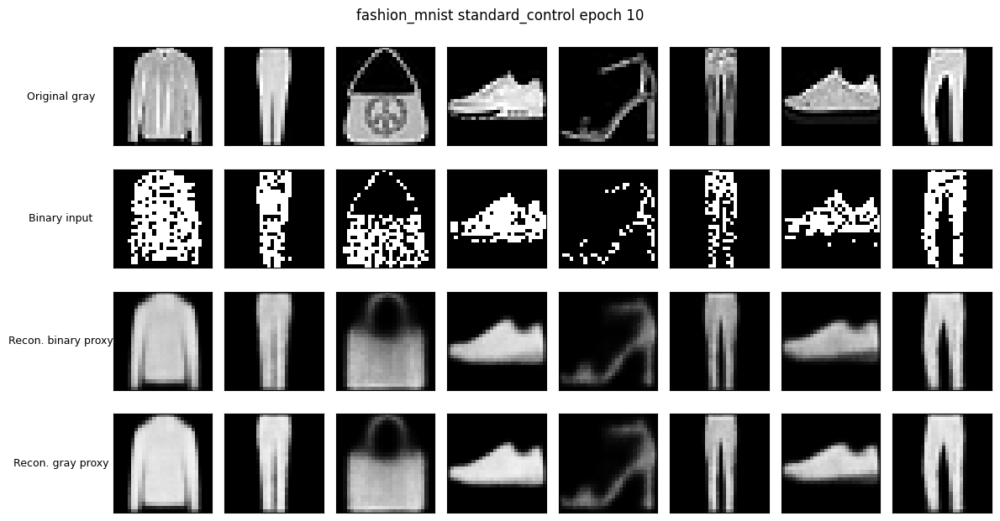

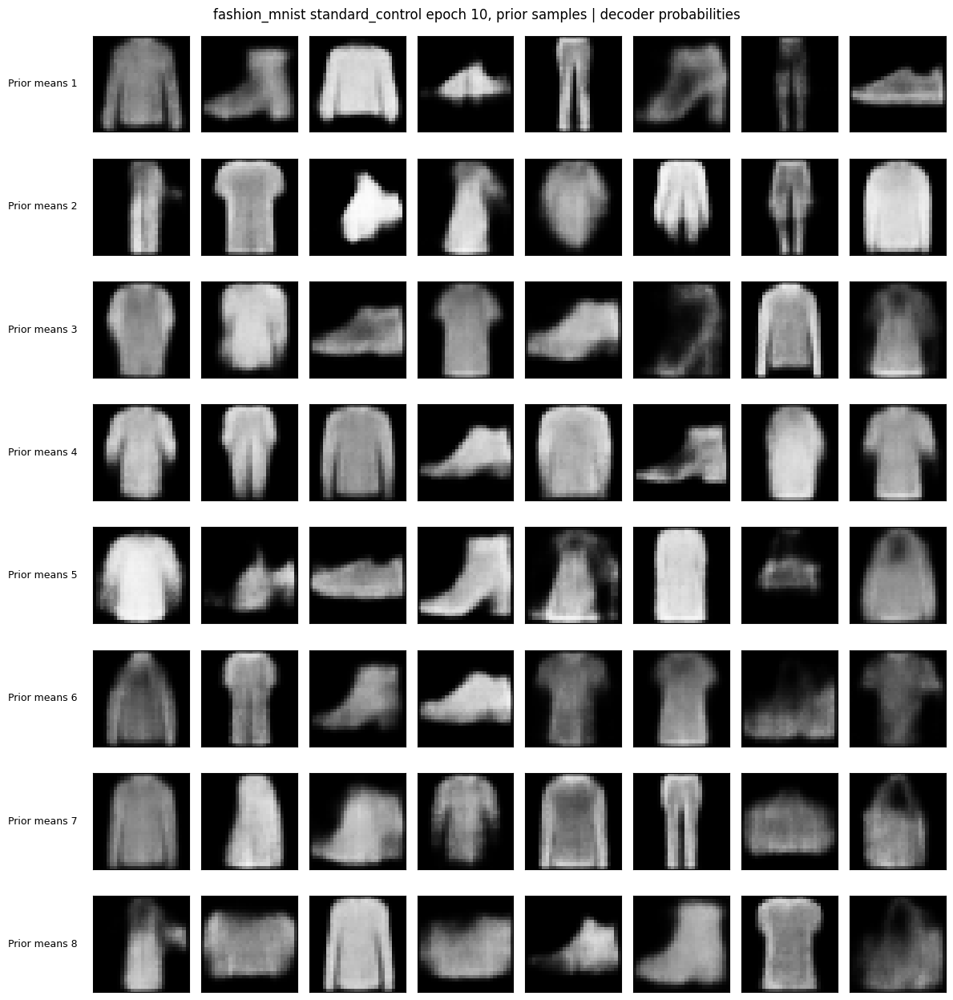

fashion_mnist standard_control | 11/30 | train -ELBO 242.45, val 242.85 | MC KL 14.00 | 1.5s
fashion_mnist standard_control | 12/30 | train -ELBO 241.65, val 242.35 | MC KL 14.45 | 1.5s
fashion_mnist standard_control | 13/30 | train -ELBO 241.01, val 241.61 | MC KL 13.98 | 1.5s
fashion_mnist standard_control | 14/30 | train -ELBO 240.44, val 240.75 | MC KL 14.26 | 1.5s
fashion_mnist standard_control | 15/30 | train -ELBO 239.89, val 240.54 | MC KL 14.53 | 1.5s
fashion_mnist standard_control | 16/30 | train -ELBO 239.38, val 240.04 | MC KL 14.55 | 1.5s
fashion_mnist standard_control | 17/30 | train -ELBO 238.90, val 239.56 | MC KL 14.44 | 1.5s
fashion_mnist standard_control | 18/30 | train -ELBO 238.62, val 239.07 | MC KL 14.55 | 1.5s
fashion_mnist standard_control | 19/30 | train -ELBO 238.12, val 238.79 | MC KL 14.79 | 1.5s
fashion_mnist standard_control | 20/30 | train -ELBO 237.87, val 238.63 | MC KL 14.93 | 1.5s


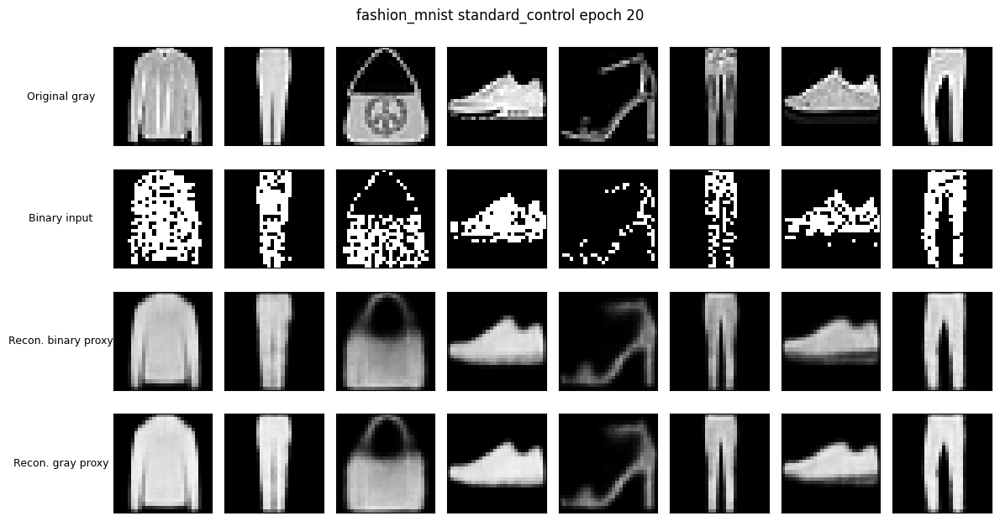

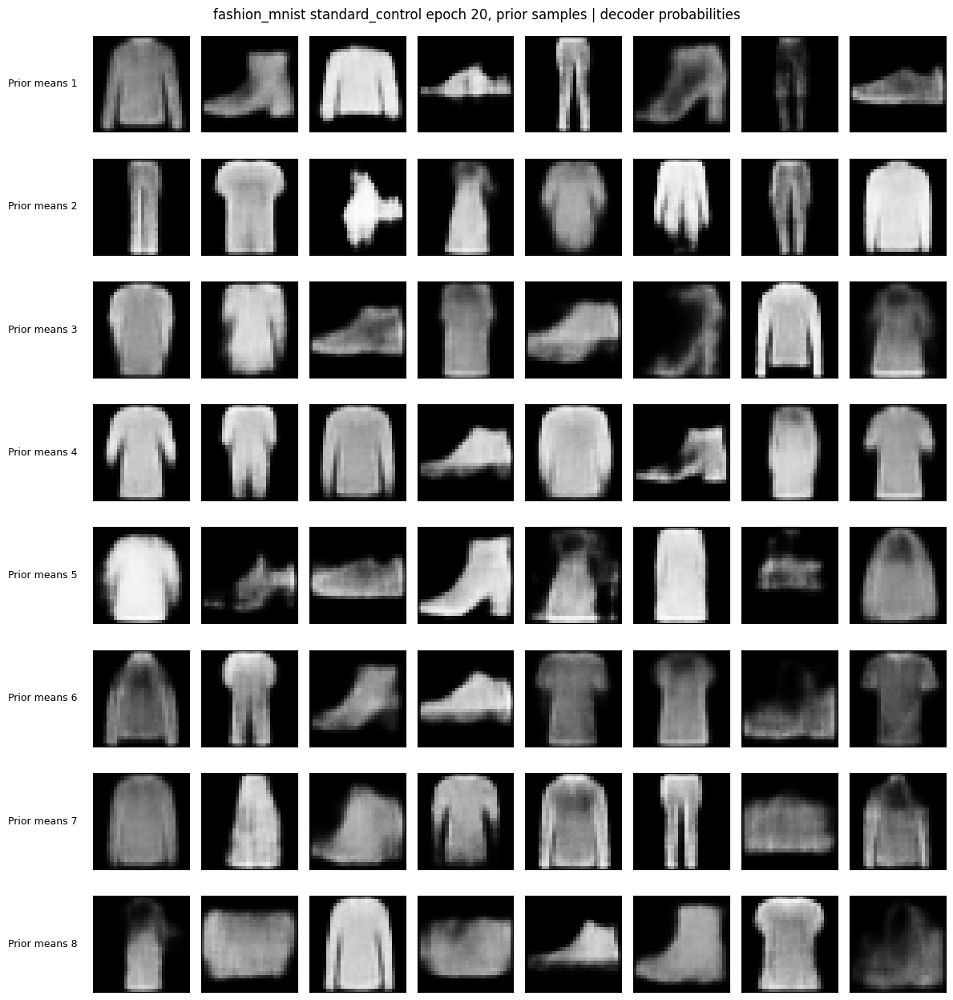

fashion_mnist standard_control | 21/30 | train -ELBO 237.66, val 238.08 | MC KL 14.77 | 1.5s
fashion_mnist standard_control | 22/30 | train -ELBO 237.26, val 238.53 | MC KL 14.72 | 1.5s
fashion_mnist standard_control | 23/30 | train -ELBO 237.07, val 237.99 | MC KL 14.80 | 1.5s
fashion_mnist standard_control | 24/30 | train -ELBO 236.87, val 237.65 | MC KL 15.15 | 1.5s
fashion_mnist standard_control | 25/30 | train -ELBO 236.77, val 237.56 | MC KL 15.09 | 1.5s
fashion_mnist standard_control | 26/30 | train -ELBO 236.49, val 237.43 | MC KL 14.92 | 1.5s
fashion_mnist standard_control | 27/30 | train -ELBO 236.21, val 237.31 | MC KL 15.43 | 1.5s
fashion_mnist standard_control | 28/30 | train -ELBO 236.17, val 237.10 | MC KL 14.94 | 1.5s
fashion_mnist standard_control | 29/30 | train -ELBO 235.87, val 236.92 | MC KL 15.12 | 1.5s
fashion_mnist standard_control | 30/30 | train -ELBO 235.69, val 236.84 | MC KL 15.14 | 1.5s


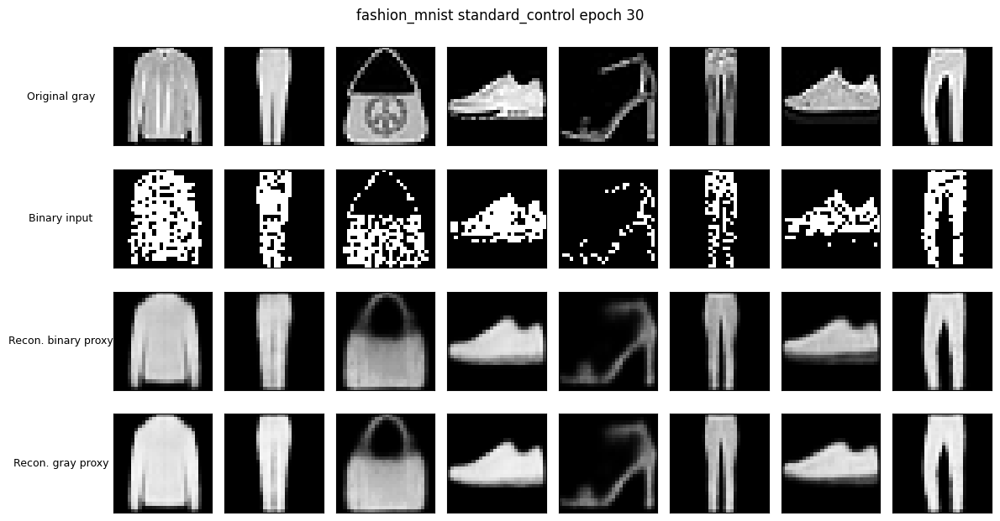

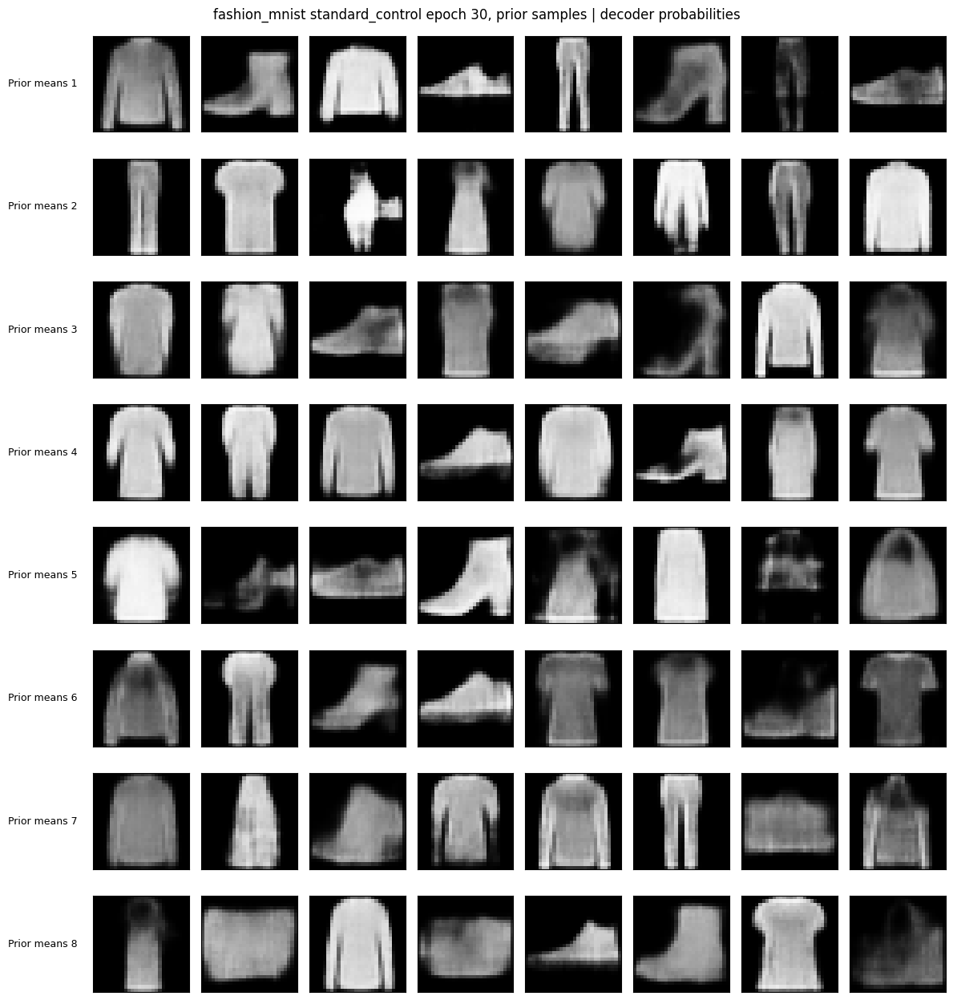

fashion_mnist flow_vae | 1/30 | train -ELBO 330.98, val 272.33 | MC KL 12.21 | 2.9s


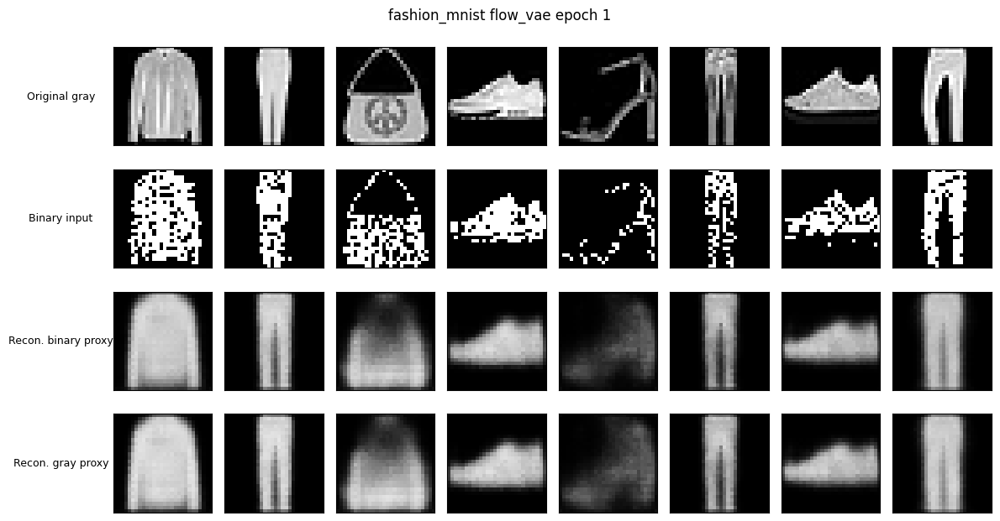

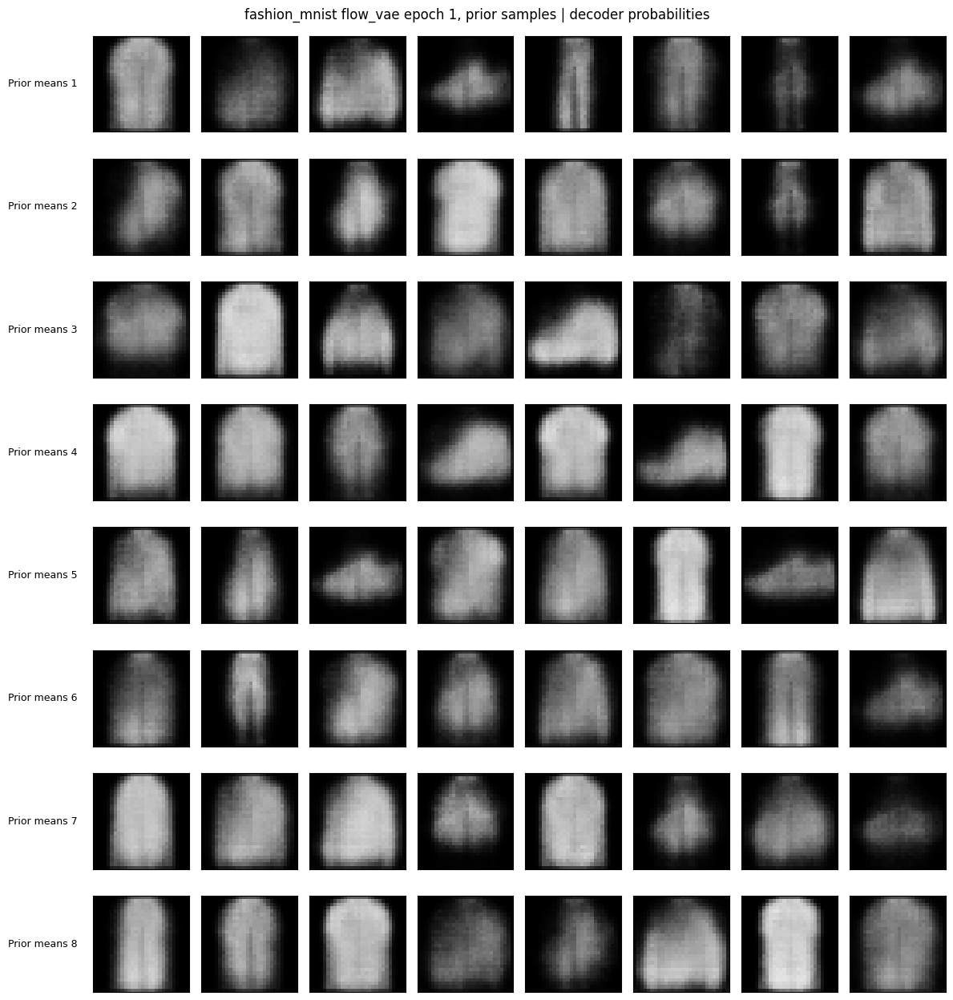

fashion_mnist flow_vae | 2/30 | train -ELBO 264.18, val 260.22 | MC KL 12.61 | 2.9s
fashion_mnist flow_vae | 3/30 | train -ELBO 256.42, val 254.81 | MC KL 12.27 | 2.8s
fashion_mnist flow_vae | 4/30 | train -ELBO 251.33, val 250.56 | MC KL 12.67 | 2.8s
fashion_mnist flow_vae | 5/30 | train -ELBO 248.53, val 248.52 | MC KL 12.82 | 2.8s
fashion_mnist flow_vae | 6/30 | train -ELBO 246.47, val 247.11 | MC KL 12.84 | 2.8s
fashion_mnist flow_vae | 7/30 | train -ELBO 245.04, val 245.52 | MC KL 12.99 | 2.8s
fashion_mnist flow_vae | 8/30 | train -ELBO 243.80, val 244.10 | MC KL 13.15 | 2.8s
fashion_mnist flow_vae | 9/30 | train -ELBO 242.80, val 243.12 | MC KL 13.27 | 2.8s
fashion_mnist flow_vae | 10/30 | train -ELBO 241.84, val 242.76 | MC KL 13.48 | 2.8s


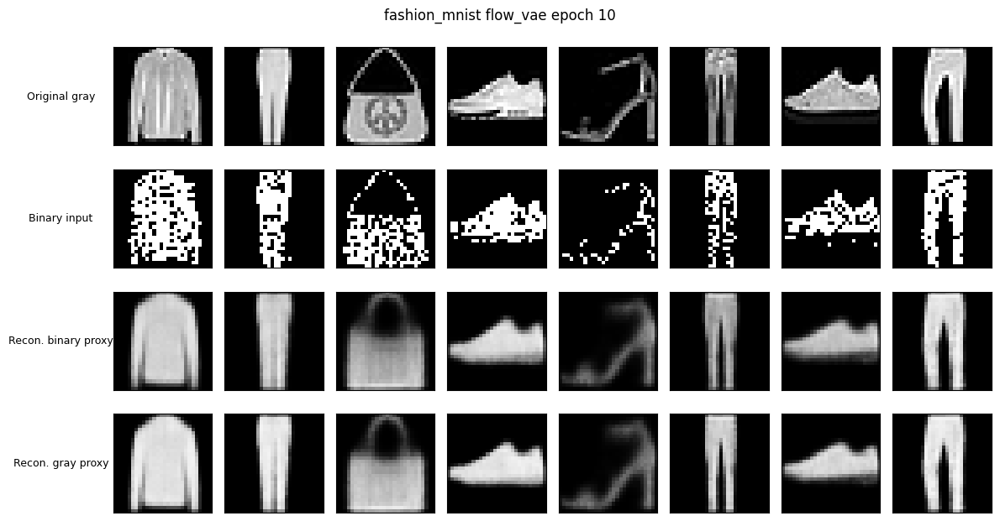

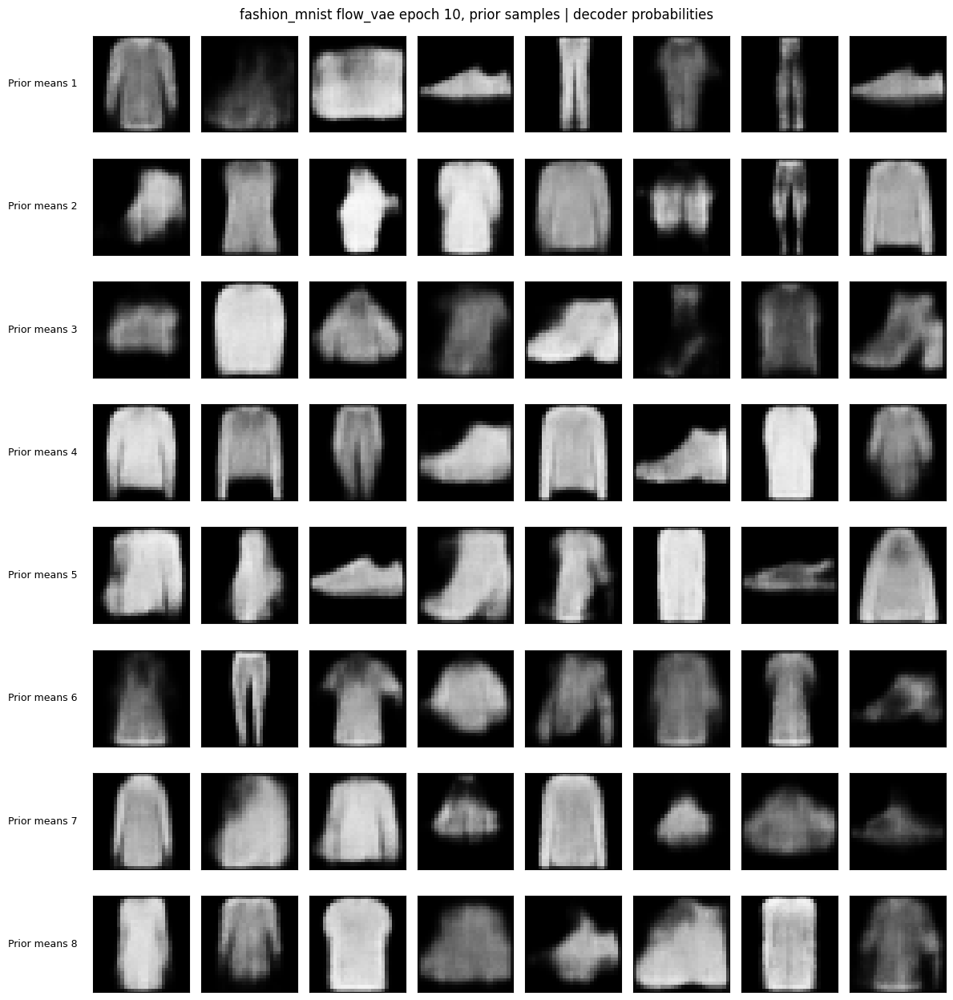

fashion_mnist flow_vae | 11/30 | train -ELBO 241.12, val 242.31 | MC KL 13.65 | 3.6s
fashion_mnist flow_vae | 12/30 | train -ELBO 240.36, val 241.09 | MC KL 13.93 | 3.7s
fashion_mnist flow_vae | 13/30 | train -ELBO 239.82, val 240.39 | MC KL 13.76 | 3.6s
fashion_mnist flow_vae | 14/30 | train -ELBO 239.25, val 240.14 | MC KL 13.94 | 3.6s
fashion_mnist flow_vae | 15/30 | train -ELBO 238.73, val 239.06 | MC KL 13.93 | 3.7s
fashion_mnist flow_vae | 16/30 | train -ELBO 238.29, val 239.70 | MC KL 14.25 | 3.7s
fashion_mnist flow_vae | 17/30 | train -ELBO 237.87, val 238.86 | MC KL 14.49 | 3.7s
fashion_mnist flow_vae | 18/30 | train -ELBO 237.60, val 238.22 | MC KL 14.50 | 3.7s
fashion_mnist flow_vae | 19/30 | train -ELBO 237.19, val 237.95 | MC KL 14.65 | 3.7s
fashion_mnist flow_vae | 20/30 | train -ELBO 236.85, val 237.57 | MC KL 14.72 | 3.7s


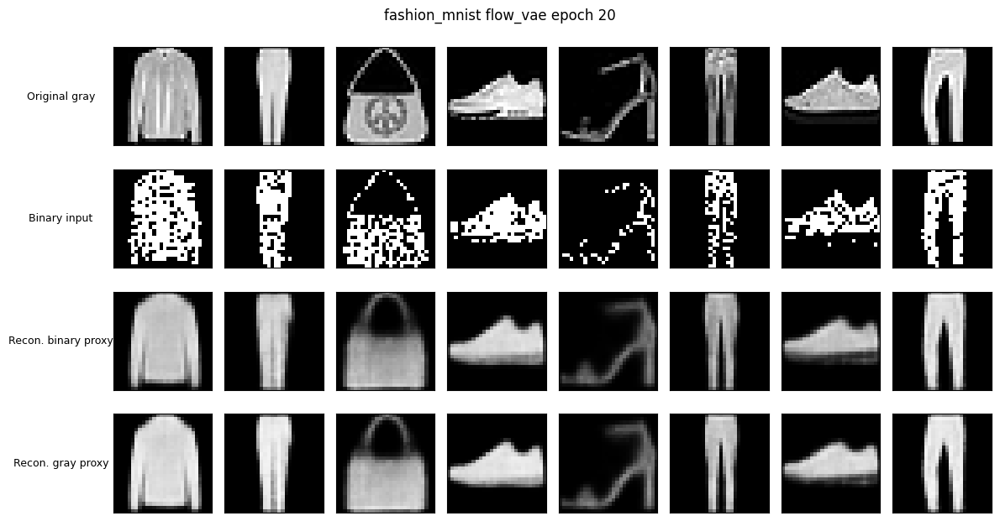

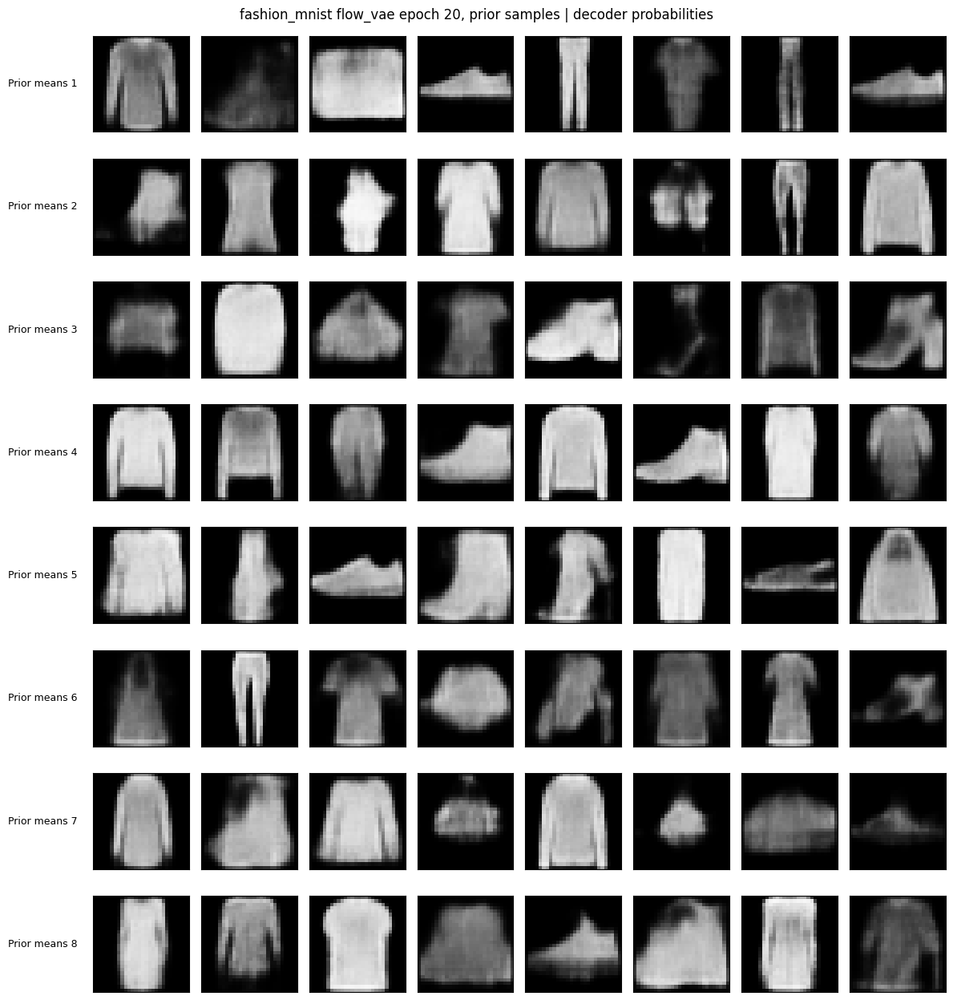

fashion_mnist flow_vae | 21/30 | train -ELBO 236.65, val 237.72 | MC KL 14.74 | 3.7s
fashion_mnist flow_vae | 22/30 | train -ELBO 236.33, val 237.52 | MC KL 14.59 | 3.7s
fashion_mnist flow_vae | 23/30 | train -ELBO 236.09, val 236.89 | MC KL 14.55 | 3.7s
fashion_mnist flow_vae | 24/30 | train -ELBO 235.87, val 236.84 | MC KL 14.88 | 3.7s
fashion_mnist flow_vae | 25/30 | train -ELBO 235.76, val 236.73 | MC KL 14.97 | 3.8s
fashion_mnist flow_vae | 26/30 | train -ELBO 235.40, val 236.52 | MC KL 15.19 | 3.7s
fashion_mnist flow_vae | 27/30 | train -ELBO 235.21, val 236.48 | MC KL 14.98 | 3.7s
fashion_mnist flow_vae | 28/30 | train -ELBO 235.11, val 235.89 | MC KL 14.96 | 3.8s
fashion_mnist flow_vae | 29/30 | train -ELBO 234.93, val 235.79 | MC KL 15.31 | 2.9s
fashion_mnist flow_vae | 30/30 | train -ELBO 234.71, val 235.87 | MC KL 15.06 | 2.8s


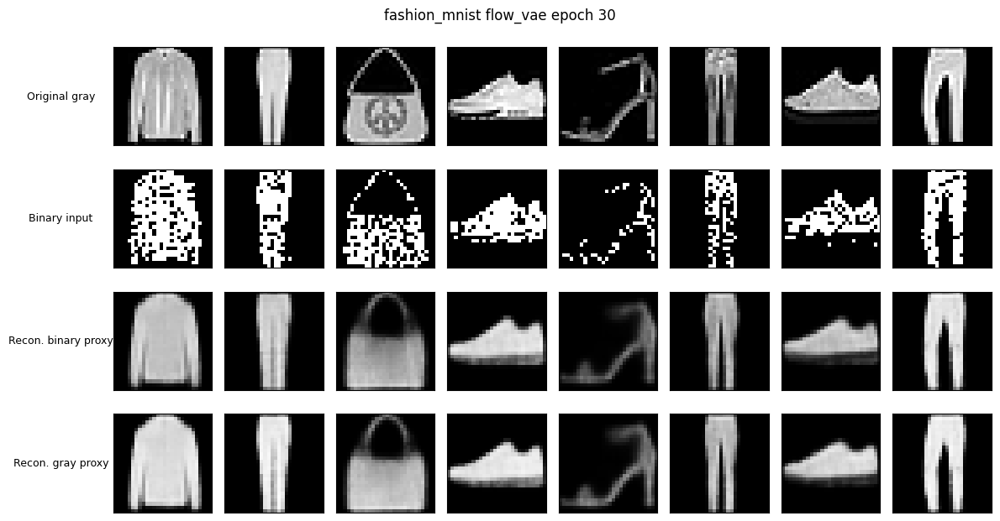

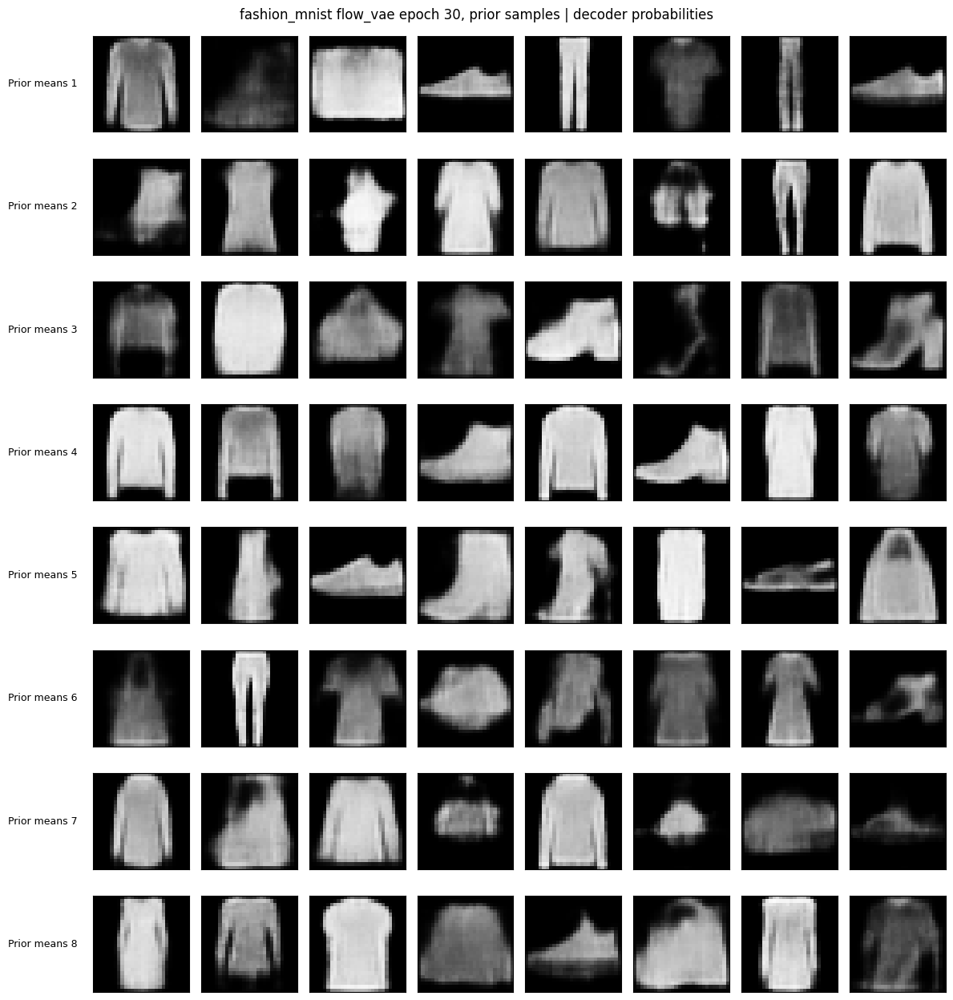

,dataset,model,flow_layers,best_epoch,val_negative_elbo,parameters,seconds
0,mnist,standard_control,0,29,95.924475,1700609,45.799607
1,mnist,flow_vae,6,30,94.132625,1923713,108.755194
2,fashion_mnist,standard_control,0,30,236.837742,1700609,45.120021
3,fashion_mnist,flow_vae,6,29,235.786539,1923713,100.345338


In [44]:
def train_flow_vae(dataset,name,layers):
    seed_all()
    train,val=training_loaders(dataset)
    model=FlowVAE(NF_LATENT_DIM,layers,NF_HIDDEN_DIM).to(DEVICE)
    seed_all()
    optimizer=torch.optim.Adam(model.parameters(),lr=NF_LEARNING_RATE)
    folder=NF_RESULTS/dataset/name
    folder.mkdir(parents=True,exist_ok=True)
    checkpoint=NF_CHECKPOINTS/f'{dataset}_{name}.pt'
    epochs=2 if SMOKE_TEST else NF_EPOCHS
    config=dict(dataset=dataset,model=name,latent_dim=NF_LATENT_DIM,flow_layers=layers,
                flow_hidden=NF_HIDDEN_DIM,epochs=epochs,seed=SEED,learning_rate=NF_LEARNING_RATE,
                batch_size=BATCH_SIZE,train_size=len(train.dataset),validation_size=len(val.dataset),
                kl_weight=1.,posterior='conditional RealNVP over diagonal Gaussian',
                kl_estimator='Monte Carlo log_qK - log_p',observation_model='Bernoulli on dynamic binarization',
                parameters=sum(p.numel() for p in model.parameters()),smoke_test=SMOKE_TEST)
    (folder/'config.json').write_text(json.dumps(config,indent=2))
    examples=next(iter(val))[0][:8]
    best,history=float('inf'),[]
    for epoch in range(1,epochs+1):
        started=time.perf_counter()
        model.train()
        totals=dict(reconstruction_nll=0.,kl_mc=0.,negative_elbo=0.)
        count=0
        for gray,_ in train:
            x=torch.bernoulli(gray.to(DEVICE))
            optimizer.zero_grad(set_to_none=True)
            logits,log_q,log_p=model(x)
            recon=F.binary_cross_entropy_with_logits(logits,x,reduction='none').flatten(1).sum(1)
            ratio=log_q-log_p
            loss=(recon+ratio).mean()
            if not torch.isfinite(loss): raise FloatingPointError('Non-finite flow-VAE loss')
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(),5.,error_if_nonfinite=True)
            optimizer.step()
            totals['reconstruction_nll']+=recon.sum().item()
            totals['kl_mc']+=ratio.sum().item()
            totals['negative_elbo']+=(recon+ratio).sum().item()
            count+=len(x)
        validation=evaluate_flow_vae(model,val,importance_samples=1)
        row=dict(epoch=epoch,**{'train_'+key:value/count for key,value in totals.items()},
                 **{'val_'+key:value for key,value in validation.items()},
                 seconds=time.perf_counter()-started)
        history.append(row)
        pd.DataFrame(history).to_csv(folder/'history.csv',index=False)
        if validation['negative_elbo']<best:
            best=validation['negative_elbo']
            torch.save(dict(model=model.state_dict(),epoch=epoch,config=config),checkpoint)
        print(f'{dataset} {name} | {epoch}/{epochs} | train -ELBO {row["train_negative_elbo"]:.2f}, val {validation["negative_elbo"]:.2f} | MC KL {validation["kl_mc"]:.2f} | {row["seconds"]:.1f}s',flush=True)
        if epoch==1 or epoch%10==0 or epoch==epochs:
            flow_reconstruction_preview(model,examples,f'{dataset} {name} epoch {epoch}',folder/f'recon_epoch_{epoch:03d}.png')
            vae_sample_grid(model,f'{dataset} {name} epoch {epoch}, prior samples',folder/f'prior_epoch_{epoch:03d}.png')
    saved=torch.load(checkpoint,map_location=DEVICE,weights_only=True)
    return dict(dataset=dataset,model=name,flow_layers=layers,best_epoch=saved['epoch'],
                val_negative_elbo=best,parameters=config['parameters'],
                seconds=sum(row['seconds'] for row in history),checkpoint=str(checkpoint))

nf_runs=[]
for dataset in DATASET_NAMES:
    for name,layers in NF_CONFIGS:
        nf_runs.append(train_flow_vae(dataset,name,layers))
        pd.DataFrame([{k:v for k,v in run.items() if k!='checkpoint'} for run in nf_runs]).to_csv(NF_RESULTS/'validation_comparison.csv',index=False)
display(pd.DataFrame([{k:v for k,v in run.items() if k!='checkpoint'} for run in nf_runs]))


### 3.4 Test results and learning curves

Test evaluation used K=16 importance samples and the correct posterior density for each model. The flow improved the measured importance-weighted bound on both datasets in this run. This single-seed improvement does not establish a general visual advantage.


,dataset,model,best_epoch,importance_samples,reconstruction_nll,kl_mc,negative_elbo,negative_iwae_estimate,gray_mse,smoke_test
0,mnist,standard_control,29,16,69.654438,25.730053,95.384491,91.575068,0.007705,False
1,mnist,flow_vae,30,16,70.213082,23.346135,93.559218,89.967640,0.007960,False
2,fashion_mnist,standard_control,30,16,222.897573,15.105283,238.002856,235.473633,0.020265,False
3,fashion_mnist,flow_vae,29,16,221.652699,15.236218,236.888919,234.623366,0.017157,False


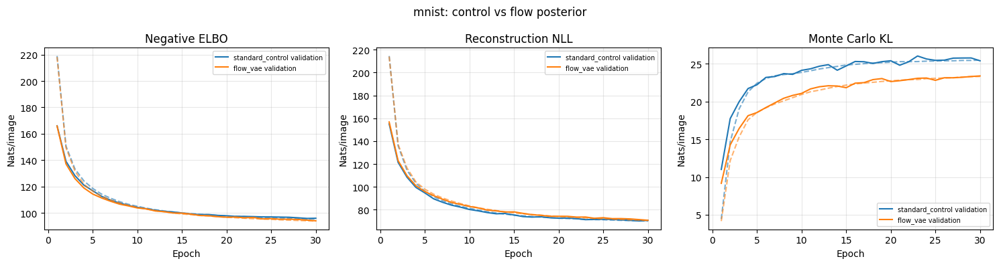

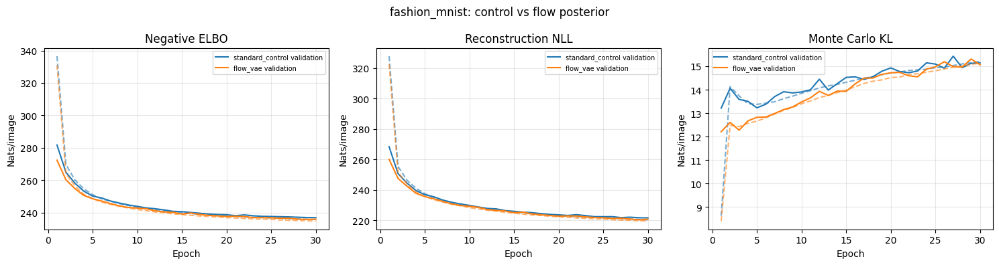

In [45]:
nf_test_rows=[]
for run in nf_runs:
    model=FlowVAE(NF_LATENT_DIM,run['flow_layers'],NF_HIDDEN_DIM).to(DEVICE)
    model.load_state_dict(torch.load(run['checkpoint'],map_location=DEVICE,weights_only=True)['model'])
    ds=testing_loader(run['dataset']).dataset
    loader=DataLoader(ds,batch_size=64,shuffle=False,num_workers=0)
    k=2 if SMOKE_TEST else NF_IMPORTANCE_SAMPLES
    values=evaluate_flow_vae(model,loader,importance_samples=k,seed=3030)
    nf_test_rows.append(dict(dataset=run['dataset'],model=run['model'],best_epoch=run['best_epoch'],
                             importance_samples=k,**values,smoke_test=SMOKE_TEST))
nf_test_results=pd.DataFrame(nf_test_rows)
nf_test_results.to_csv(NF_RESULTS/'test_results.csv',index=False)
display(nf_test_results)

for dataset in DATASET_NAMES:
    fig,axes=plt.subplots(1,3,figsize=(15,4))
    for name,_ in NF_CONFIGS:
        history=pd.read_csv(NF_RESULTS/dataset/name/'history.csv')
        for ax,metric,title in zip(axes,['negative_elbo','reconstruction_nll','kl_mc'],
                                   ['Negative ELBO','Reconstruction NLL','Monte Carlo KL']):
            line,=ax.plot(history.epoch,history['val_'+metric],label=name+' validation')
            ax.plot(history.epoch,history['train_'+metric],'--',color=line.get_color(),alpha=0.6)
            ax.set(title=title,xlabel='Epoch',ylabel='Nats/image')
            ax.grid(alpha=0.3)
            ax.legend(fontsize=7)
    fig.suptitle(('SMOKE TEST | ' if SMOKE_TEST else '')+dataset+': control vs flow posterior')
    fig.tight_layout()
    fig.savefig(NF_RESULTS/f'{dataset}_learning_curves.png',dpi=130)
    plt.show()
    plt.close(fig)


### 3.5 Generation and reconstruction comparison

Both models used identical prior seeds for generation. Reconstructions used a transformed-base-mean proxy, which is not the exact mean of the flow posterior. The panels compare reconstruction detail and sample quality alongside the likelihood-bound results.


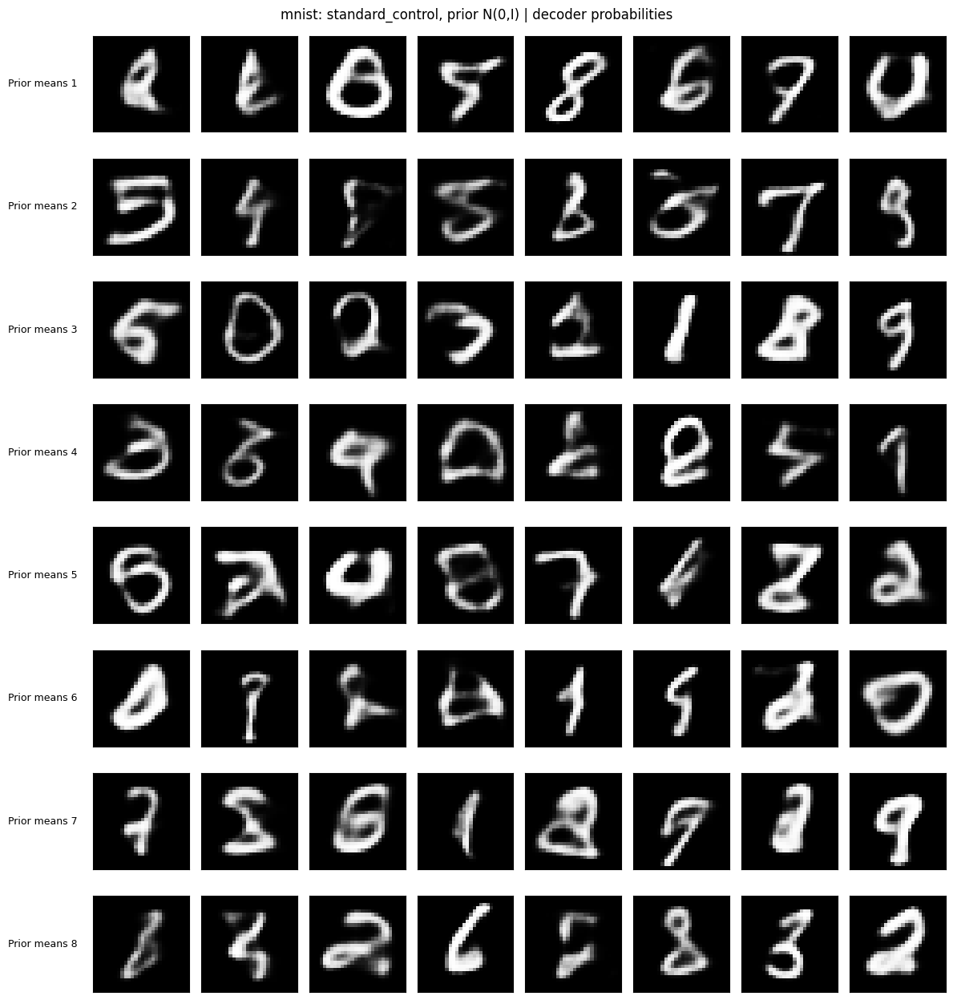

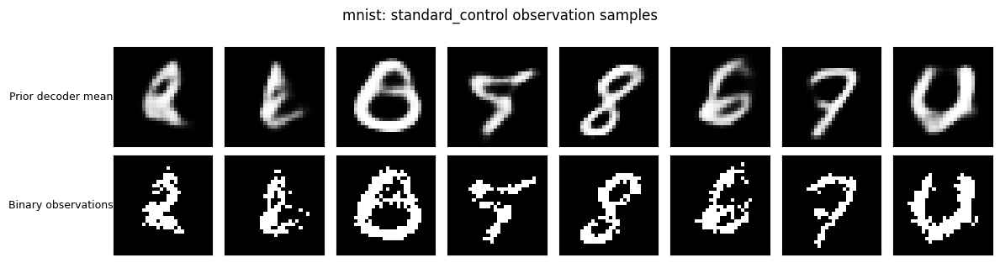

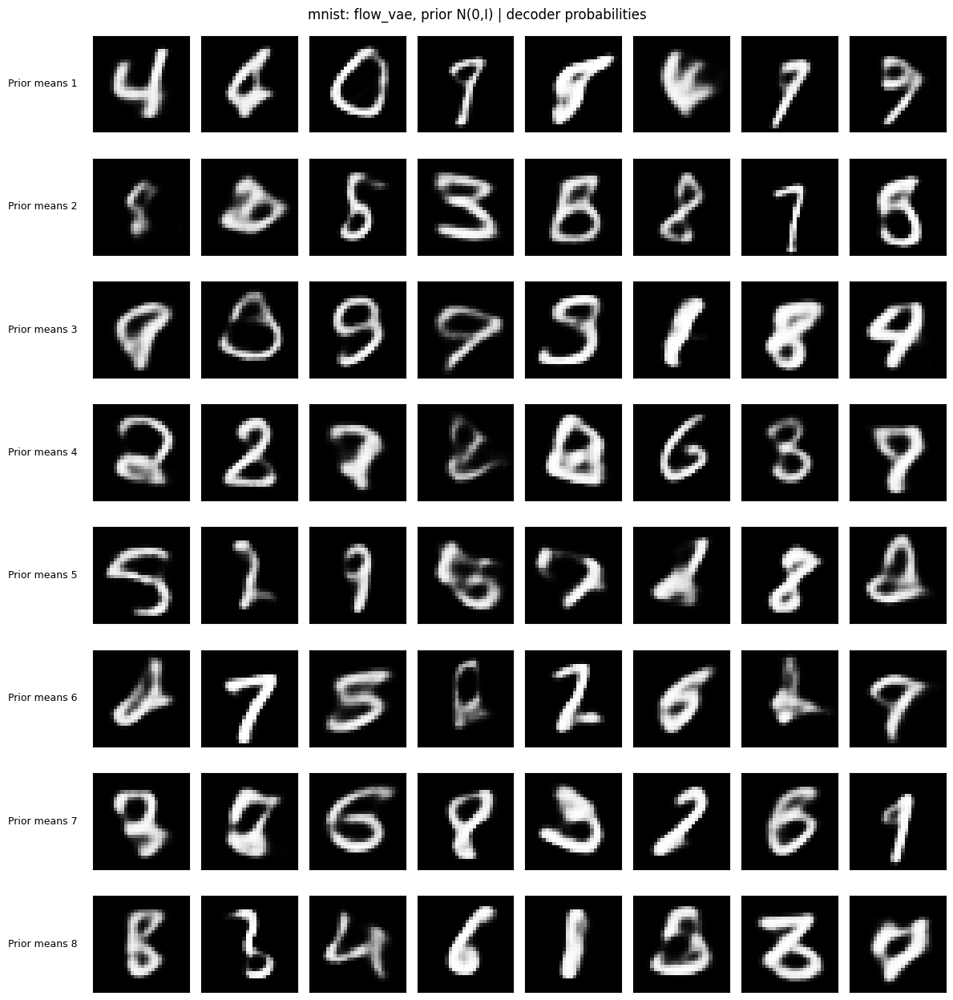

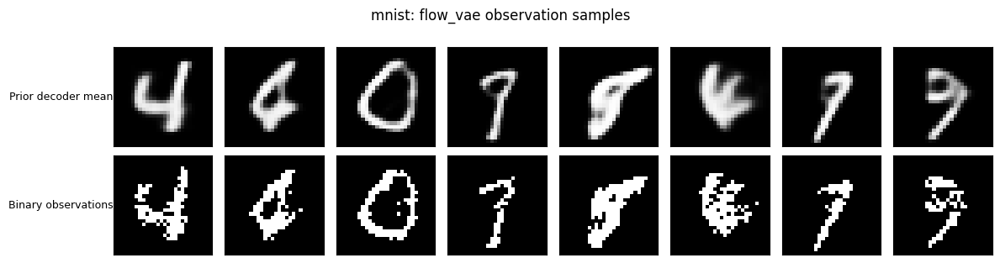

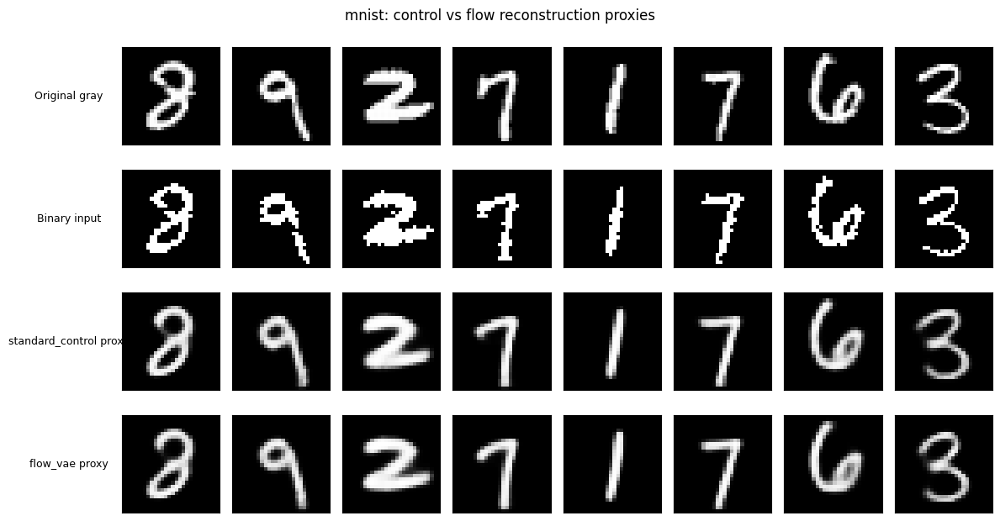

...

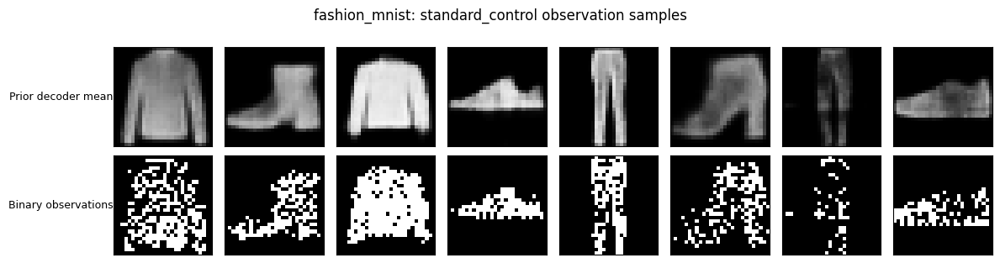

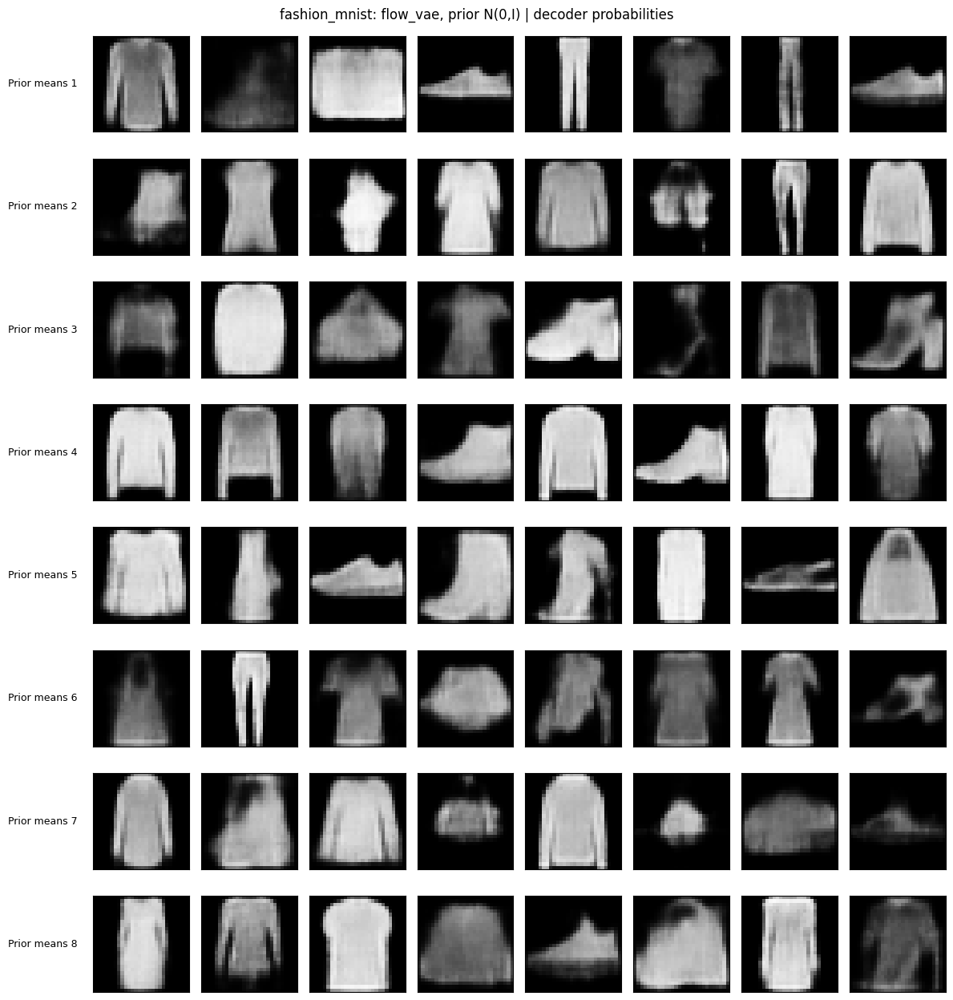

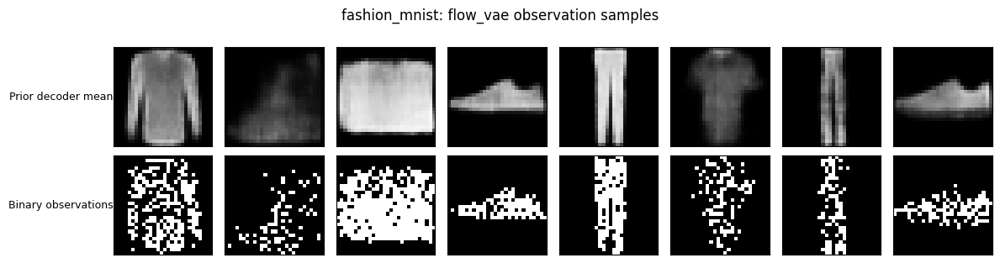

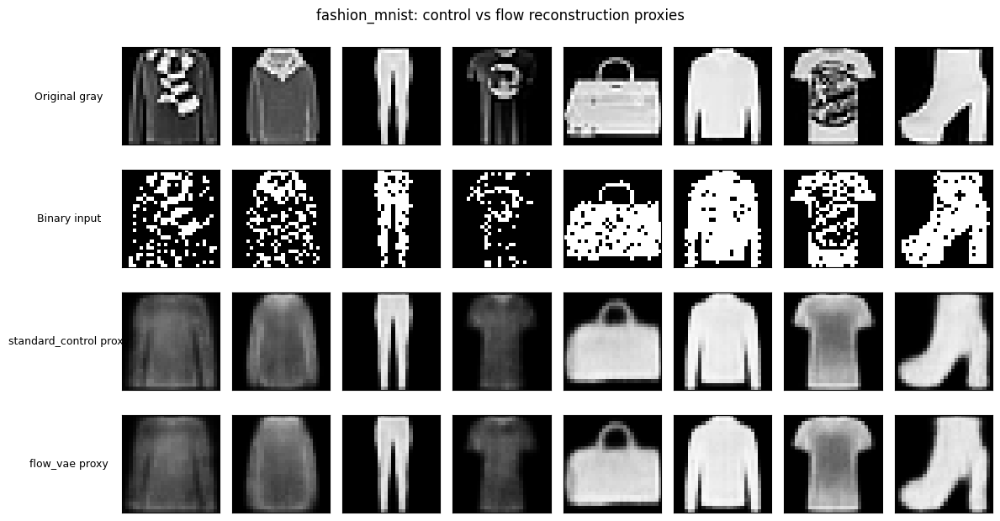

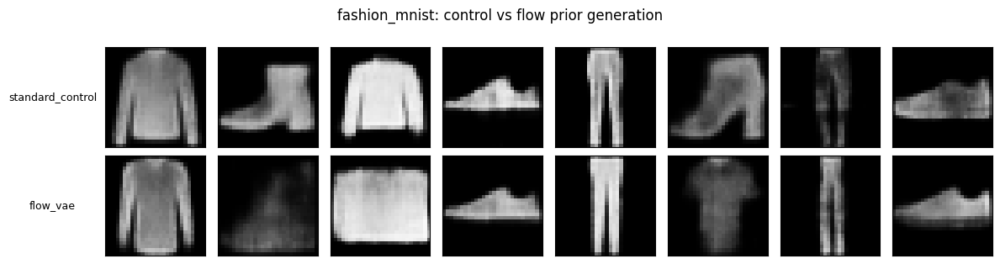

In [46]:
for dataset in DATASET_NAMES:
    ds=testing_loader(dataset).dataset
    indices=torch.randperm(len(ds),generator=torch.Generator().manual_seed(123))[:8]
    examples=torch.stack([ds[int(i)][0] for i in indices])
    binary=torch.bernoulli(examples,generator=torch.Generator().manual_seed(1234))
    reconstruction_rows=[('Original gray',examples),('Binary input',binary)]
    generation_rows=[]
    for run in (r for r in nf_runs if r['dataset']==dataset):
        model=FlowVAE(NF_LATENT_DIM,run['flow_layers'],NF_HIDDEN_DIM).to(DEVICE)
        model.load_state_dict(torch.load(run['checkpoint'],map_location=DEVICE,weights_only=True)['model'])
        model.eval()
        with torch.no_grad():
            recon=model.representative_reconstruction(binary.to(DEVICE)).cpu()
        reconstruction_rows.append((run['model']+' proxy',recon))
        probabilities,pixels=vae_sample_grid(model,f'{dataset}: {run["model"]}, prior N(0,I)',
                                             NF_RESULTS/f'{dataset}_{run["model"]}_prior.png')
        generation_rows.append((run['model'],probabilities[:8]))
        vae_panel([('Prior decoder mean',probabilities[:8]),('Binary observations',pixels[:8])],
                  f'{dataset}: {run["model"]} observation samples',
                  NF_RESULTS/f'{dataset}_{run["model"]}_observations.png')
    vae_panel(reconstruction_rows,dataset+': control vs flow reconstruction proxies',
              NF_RESULTS/f'{dataset}_reconstruction_comparison.png')
    vae_panel(generation_rows,dataset+': control vs flow prior generation',
              NF_RESULTS/f'{dataset}_generation_comparison.png')


## Part 4: Beta-VAE

Beta values 0.5, 1, 4 and 8 were compared on both datasets with the same convolutional VAE, latent size, split, seed, optimizer and training budget. Beta=1 was the matched standard-VAE reference. Only the KL weight changed; no posterior flow was used.


In [48]:
BETA_VALUES = [0.5,1.0,4.0,8.0]
BETA_LATENT_DIM = 32
BETA_EPOCHS = 30
BETA_LEARNING_RATE = 1e-3
BETA_IMPORTANCE_SAMPLES = 16
BETA_ACTIVE_THRESHOLD = 0.01  # Var_x E_q[z_j|x] on validation.
BETA_TRAVERSAL_DIMS = 8
BETA_TRAVERSAL_VALUES = [-3.,-2.,-1.,0.,1.,2.,3.]
BETA_RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
BETA_RESULTS = HW/'results'/'beta_vae'/('smoke' if SMOKE_TEST else 'full')/BETA_RUN_ID
BETA_CHECKPOINTS = ROOT/'.local'/'hw1'/'beta_vae'/'checkpoints'/BETA_RUN_ID
BETA_RESULTS.mkdir(parents=True,exist_ok=True)
BETA_CHECKPOINTS.mkdir(parents=True,exist_ok=True)
(BETA_RESULTS/'environment.json').write_text(json.dumps(environment,indent=2))
def beta_tag(beta): return str(float(beta)).replace('.','p')
print('Beta-VAE results:',BETA_RESULTS)


Beta-VAE results: c:\Users\Admin\Desktop\GEN_AI_CV\HW1\results\beta_vae\full\20261112T200728667225Z


### 4.1 Objective and interpretation

$$\mathcal L_\beta(x)=\mathbb E_q[-\log p_\theta(x|z)]+\beta\,\mathrm{KL}(q_\phi(z|x)\Vert p(z)).$$

Reconstruction NLL was summed over pixels and KL over latent coordinates. Beta below 1 reduced regularization; beta above 1 increased it. Higher beta can reduce latent capacity and reconstruction detail rather than automatically improving generation.

The datasets do not provide independent ground-truth factors, so no MIG/DCI score or proven disentanglement is claimed. Traversals, correlations and active-unit counts are exploratory diagnostics. Latent axes can also change meaning between models.


In [49]:
def beta_loss_terms(logits,target,mu,logvar,beta):
    reconstruction,kl=vae_terms(logits,target,mu,logvar)
    return reconstruction,kl,reconstruction+beta*kl

@torch.no_grad()
def evaluate_beta_vae(model,loader,beta,importance_samples=1,seed=2026):
    values=evaluate_vae(model,loader,importance_samples=importance_samples,seed=seed)
    values['beta_objective']=values['reconstruction_nll']+beta*values['kl']
    return values

# Scaling and gradient checks use CPU, including the beta=1 standard-VAE identity.
def check_beta_objective():
    logits=torch.randn(3,1,28,28,dtype=torch.float64,requires_grad=True)
    x=torch.randint(0,2,logits.shape).to(logits.dtype)
    mu=torch.randn(3,4,dtype=torch.float64,requires_grad=True)
    lv=torch.randn(3,4,dtype=torch.float64,requires_grad=True)
    for beta in BETA_VALUES:
        recon,kl,total=beta_loss_terms(logits,x,mu,lv,beta)
        torch.testing.assert_close(total-recon,beta*kl)
        if beta==1: torch.testing.assert_close(total,recon+kl)
    beta_loss_terms(logits,x,mu,lv,4.)[2].mean().backward()
    assert all(torch.isfinite(t.grad).all() for t in (logits,mu,lv))
    print('Passed: beta weighting, beta=1 identity and finite gradients.')
check_beta_objective()


Passed: beta weighting, beta=1 identity and finite gradients.


### 4.2 Matched training

Each model was trained from scratch for 30 epochs with latent size 32, Adam at 1e-3 and gradient clipping at 5. Seeds were reset before initialization and training to match initial weights and random data/sampling sequences. Checkpoints were selected by each run's validation beta objective; weighted objectives were not ranked across beta values.


mnist beta=0.5 | 1/30 | val objective 147.64, recon 137.90, KL 19.47 | 1.7s


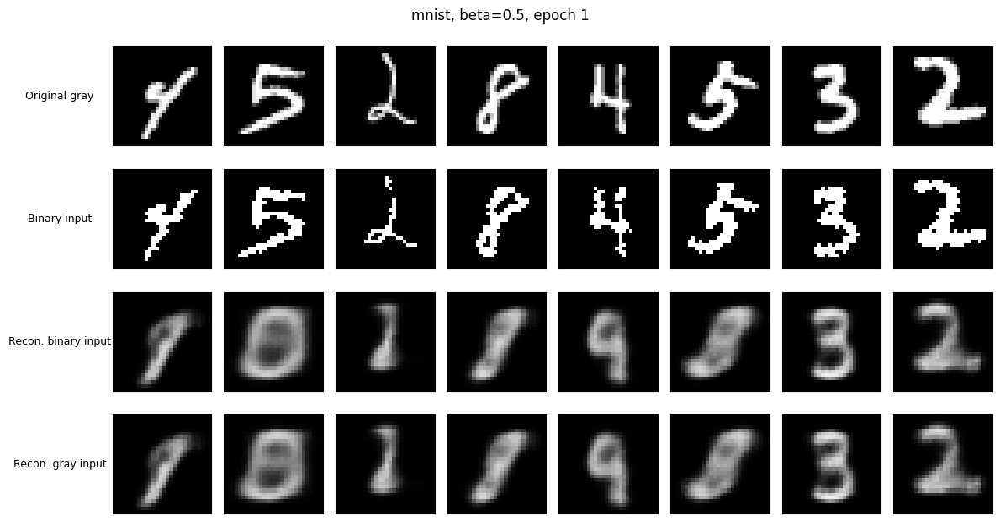

mnist beta=0.5 | 2/30 | val objective 121.01, recon 107.46, KL 27.09 | 1.6s
mnist beta=0.5 | 3/30 | val objective 108.95, recon 94.02, KL 29.86 | 1.6s
mnist beta=0.5 | 4/30 | val objective 101.77, recon 85.98, KL 31.58 | 1.5s
mnist beta=0.5 | 5/30 | val objective 96.45, recon 80.32, KL 32.26 | 1.5s
mnist beta=0.5 | 6/30 | val objective 93.36, recon 76.93, KL 32.85 | 1.6s
mnist beta=0.5 | 7/30 | val objective 91.03, recon 74.55, KL 32.97 | 1.5s
mnist beta=0.5 | 8/30 | val objective 88.72, recon 71.51, KL 34.42 | 1.5s
mnist beta=0.5 | 9/30 | val objective 87.09, recon 69.98, KL 34.24 | 1.4s
mnist beta=0.5 | 10/30 | val objective 86.30, recon 69.04, KL 34.52 | 1.4s


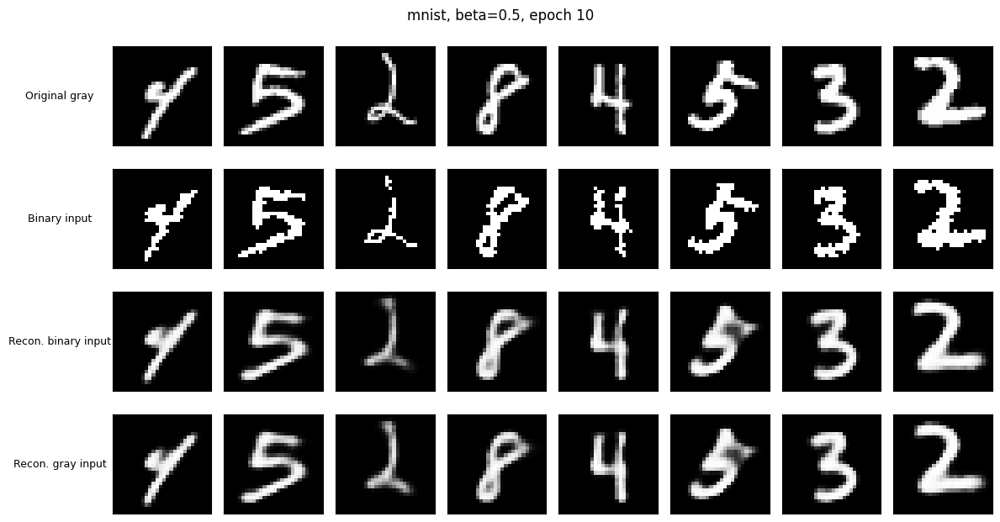

mnist beta=0.5 | 11/30 | val objective 85.48, recon 67.53, KL 35.91 | 1.5s
mnist beta=0.5 | 12/30 | val objective 84.51, recon 66.78, KL 35.45 | 1.6s
mnist beta=0.5 | 13/30 | val objective 84.03, recon 66.68, KL 34.71 | 1.5s
mnist beta=0.5 | 14/30 | val objective 84.55, recon 66.68, KL 35.75 | 1.5s
mnist beta=0.5 | 15/30 | val objective 83.44, recon 66.01, KL 34.86 | 1.5s
mnist beta=0.5 | 16/30 | val objective 82.81, recon 64.88, KL 35.85 | 1.5s
mnist beta=0.5 | 17/30 | val objective 82.24, recon 64.57, KL 35.35 | 1.5s
mnist beta=0.5 | 18/30 | val objective 81.90, recon 64.21, KL 35.38 | 1.5s
mnist beta=0.5 | 19/30 | val objective 82.07, recon 64.00, KL 36.14 | 1.5s
mnist beta=0.5 | 20/30 | val objective 81.59, recon 64.01, KL 35.16 | 1.5s


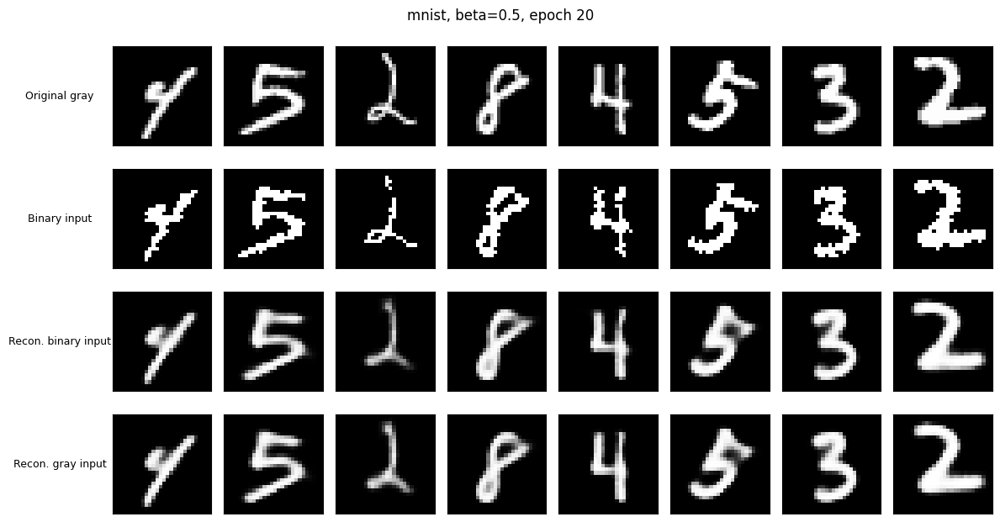

mnist beta=0.5 | 21/30 | val objective 81.83, recon 63.92, KL 35.82 | 1.5s
mnist beta=0.5 | 22/30 | val objective 81.63, recon 63.80, KL 35.67 | 1.5s
mnist beta=0.5 | 23/30 | val objective 81.41, recon 63.45, KL 35.93 | 1.5s
mnist beta=0.5 | 24/30 | val objective 81.42, recon 63.35, KL 36.13 | 1.5s
mnist beta=0.5 | 25/30 | val objective 81.22, recon 63.63, KL 35.18 | 1.5s
mnist beta=0.5 | 26/30 | val objective 81.18, recon 63.38, KL 35.59 | 1.5s
mnist beta=0.5 | 27/30 | val objective 80.40, recon 62.74, KL 35.33 | 1.4s
mnist beta=0.5 | 28/30 | val objective 80.71, recon 62.85, KL 35.72 | 1.5s
mnist beta=0.5 | 29/30 | val objective 80.23, recon 62.56, KL 35.34 | 1.5s
mnist beta=0.5 | 30/30 | val objective 79.92, recon 62.06, KL 35.72 | 1.5s


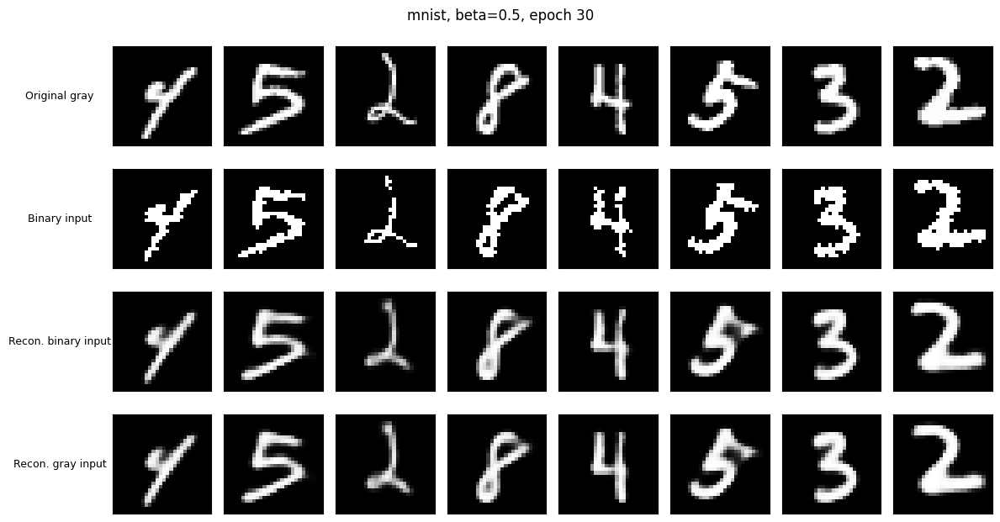

mnist beta=1 | 1/30 | val objective 164.83, recon 153.65, KL 11.18 | 1.5s


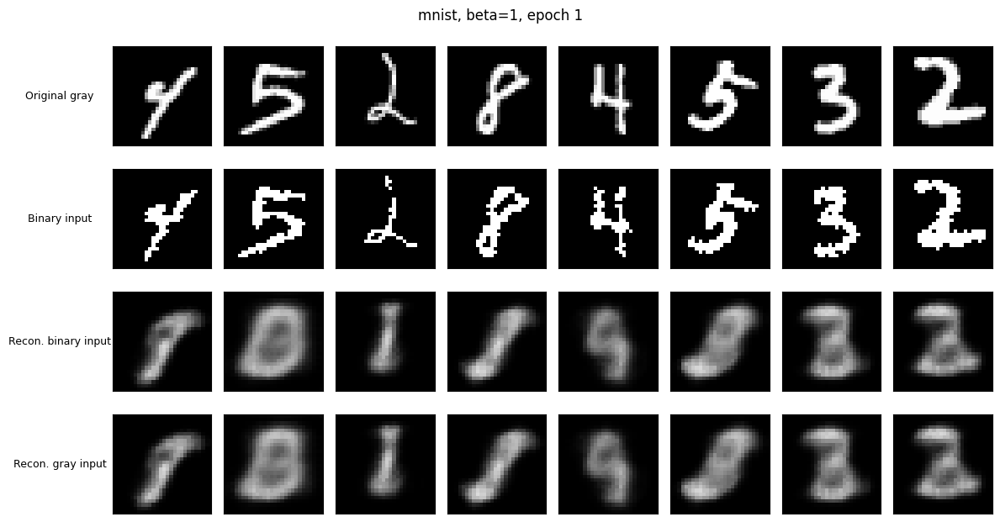

mnist beta=1 | 2/30 | val objective 137.09, recon 121.13, KL 15.96 | 1.5s
mnist beta=1 | 3/30 | val objective 124.63, recon 106.57, KL 18.06 | 1.4s
mnist beta=1 | 4/30 | val objective 117.60, recon 98.19, KL 19.41 | 1.5s
mnist beta=1 | 5/30 | val objective 112.75, recon 92.99, KL 19.75 | 1.6s
mnist beta=1 | 6/30 | val objective 109.88, recon 89.54, KL 20.34 | 1.5s
mnist beta=1 | 7/30 | val objective 108.18, recon 87.60, KL 20.57 | 1.5s
mnist beta=1 | 8/30 | val objective 105.59, recon 84.83, KL 20.76 | 1.5s
mnist beta=1 | 9/30 | val objective 104.32, recon 82.95, KL 21.37 | 1.5s
mnist beta=1 | 10/30 | val objective 103.18, recon 82.01, KL 21.17 | 1.5s


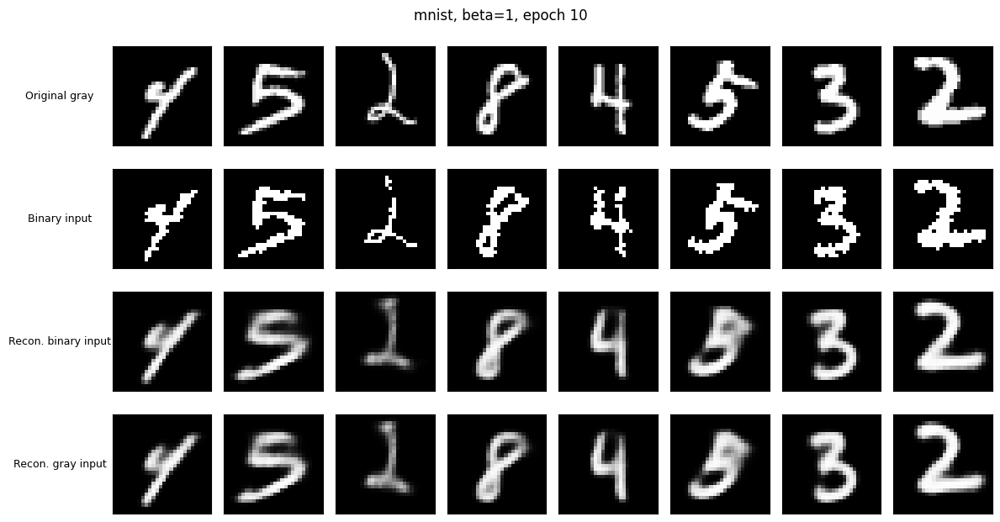

mnist beta=1 | 11/30 | val objective 102.96, recon 81.32, KL 21.64 | 1.5s
mnist beta=1 | 12/30 | val objective 101.81, recon 79.99, KL 21.82 | 1.4s
mnist beta=1 | 13/30 | val objective 100.80, recon 79.21, KL 21.59 | 1.5s
mnist beta=1 | 14/30 | val objective 100.54, recon 79.02, KL 21.52 | 1.5s
mnist beta=1 | 15/30 | val objective 99.93, recon 77.90, KL 22.03 | 1.5s
mnist beta=1 | 16/30 | val objective 99.76, recon 77.86, KL 21.90 | 1.5s
mnist beta=1 | 17/30 | val objective 99.06, recon 76.87, KL 22.18 | 1.5s
mnist beta=1 | 18/30 | val objective 99.09, recon 77.11, KL 21.98 | 1.5s
mnist beta=1 | 19/30 | val objective 98.54, recon 76.14, KL 22.40 | 1.5s
mnist beta=1 | 20/30 | val objective 98.21, recon 75.51, KL 22.70 | 1.5s


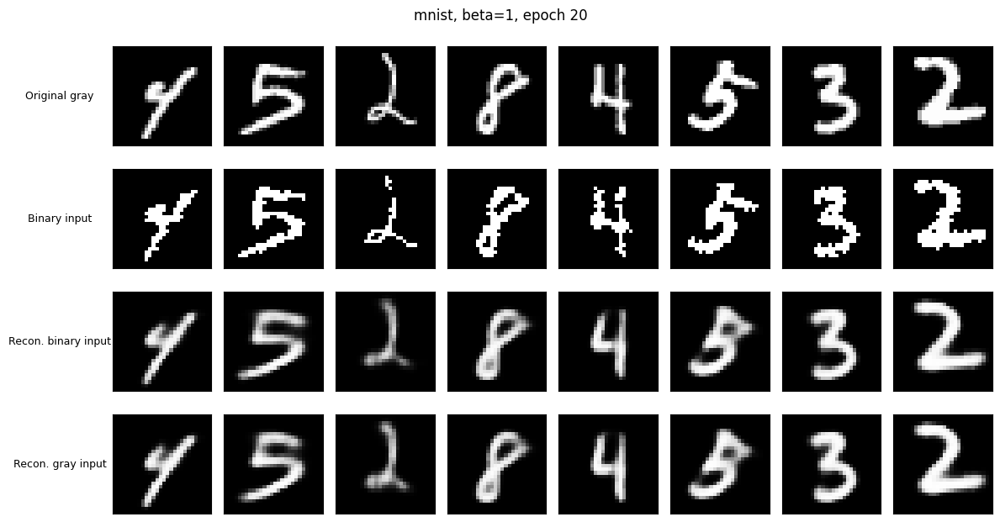

mnist beta=1 | 21/30 | val objective 97.85, recon 75.55, KL 22.30 | 1.5s
mnist beta=1 | 22/30 | val objective 98.15, recon 75.83, KL 22.32 | 1.4s
mnist beta=1 | 23/30 | val objective 97.53, recon 74.40, KL 23.13 | 1.5s
mnist beta=1 | 24/30 | val objective 98.12, recon 75.07, KL 23.05 | 1.4s
mnist beta=1 | 25/30 | val objective 97.46, recon 74.39, KL 23.07 | 1.5s
mnist beta=1 | 26/30 | val objective 97.55, recon 74.60, KL 22.95 | 1.5s
mnist beta=1 | 27/30 | val objective 96.76, recon 73.88, KL 22.88 | 1.5s
mnist beta=1 | 28/30 | val objective 96.45, recon 73.48, KL 22.96 | 1.4s
mnist beta=1 | 29/30 | val objective 96.32, recon 73.26, KL 23.06 | 1.5s
mnist beta=1 | 30/30 | val objective 96.37, recon 73.45, KL 22.92 | 1.4s


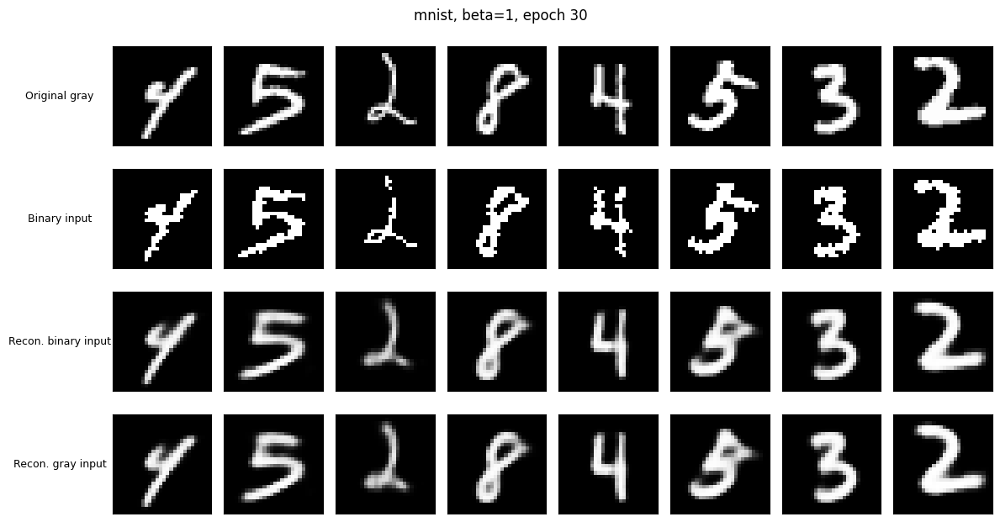

mnist beta=4 | 1/30 | val objective 187.92, recon 176.47, KL 2.86 | 1.5s


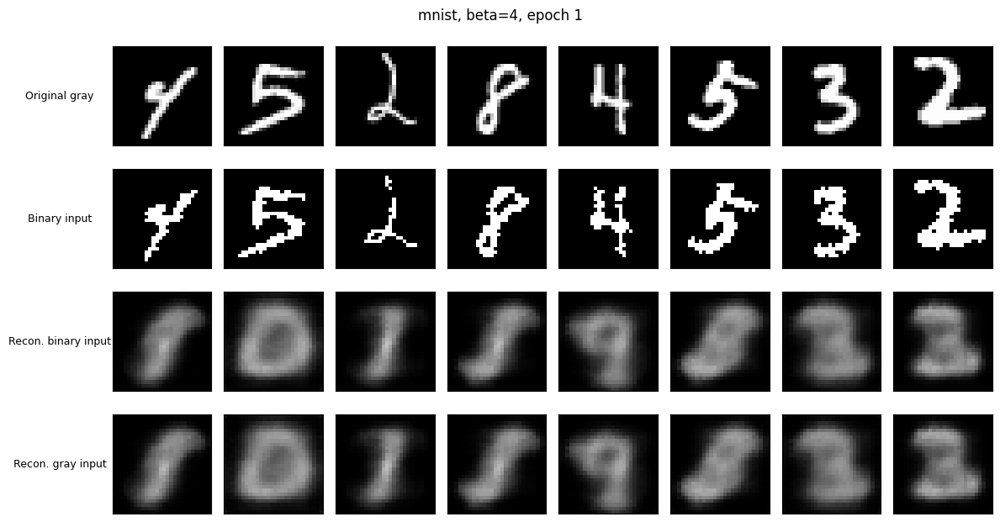

mnist beta=4 | 2/30 | val objective 167.83, recon 145.22, KL 5.65 | 1.5s
mnist beta=4 | 3/30 | val objective 158.70, recon 132.58, KL 6.53 | 1.4s
mnist beta=4 | 4/30 | val objective 155.33, recon 126.75, KL 7.15 | 1.5s
mnist beta=4 | 5/30 | val objective 152.77, recon 122.39, KL 7.60 | 1.5s
mnist beta=4 | 6/30 | val objective 151.39, recon 120.46, KL 7.73 | 1.5s
mnist beta=4 | 7/30 | val objective 149.29, recon 116.32, KL 8.24 | 1.4s
mnist beta=4 | 8/30 | val objective 148.31, recon 115.19, KL 8.28 | 1.4s
mnist beta=4 | 9/30 | val objective 147.60, recon 113.10, KL 8.63 | 1.4s
mnist beta=4 | 10/30 | val objective 146.62, recon 112.33, KL 8.57 | 1.4s


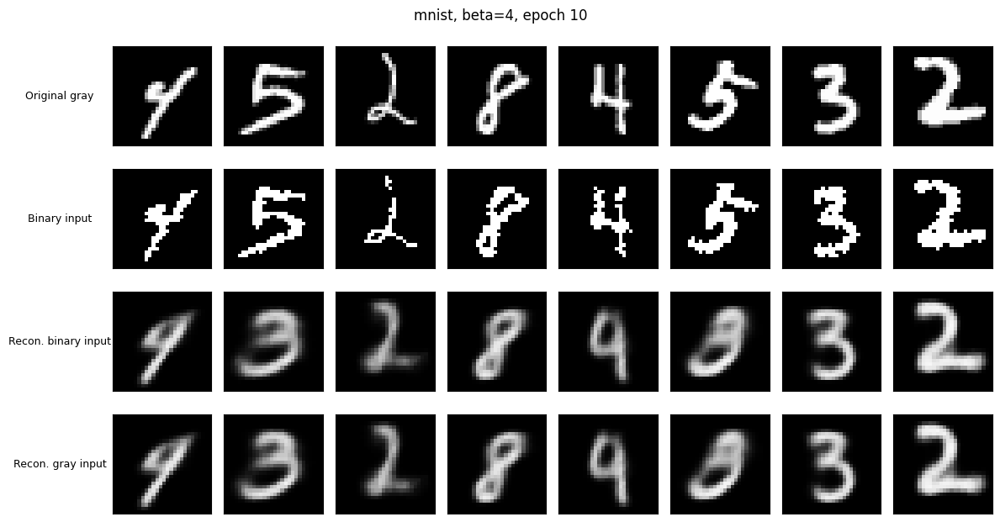

mnist beta=4 | 11/30 | val objective 146.18, recon 110.76, KL 8.85 | 1.5s
mnist beta=4 | 12/30 | val objective 145.63, recon 110.17, KL 8.86 | 1.4s
mnist beta=4 | 13/30 | val objective 145.53, recon 109.97, KL 8.89 | 1.4s
mnist beta=4 | 14/30 | val objective 144.75, recon 110.04, KL 8.68 | 1.5s
mnist beta=4 | 15/30 | val objective 144.32, recon 109.08, KL 8.81 | 1.4s
mnist beta=4 | 16/30 | val objective 144.53, recon 109.05, KL 8.87 | 1.5s
mnist beta=4 | 17/30 | val objective 144.06, recon 109.08, KL 8.75 | 1.5s
mnist beta=4 | 18/30 | val objective 143.82, recon 107.67, KL 9.04 | 1.4s
mnist beta=4 | 19/30 | val objective 143.34, recon 106.94, KL 9.10 | 1.5s
mnist beta=4 | 20/30 | val objective 143.10, recon 106.47, KL 9.16 | 1.5s


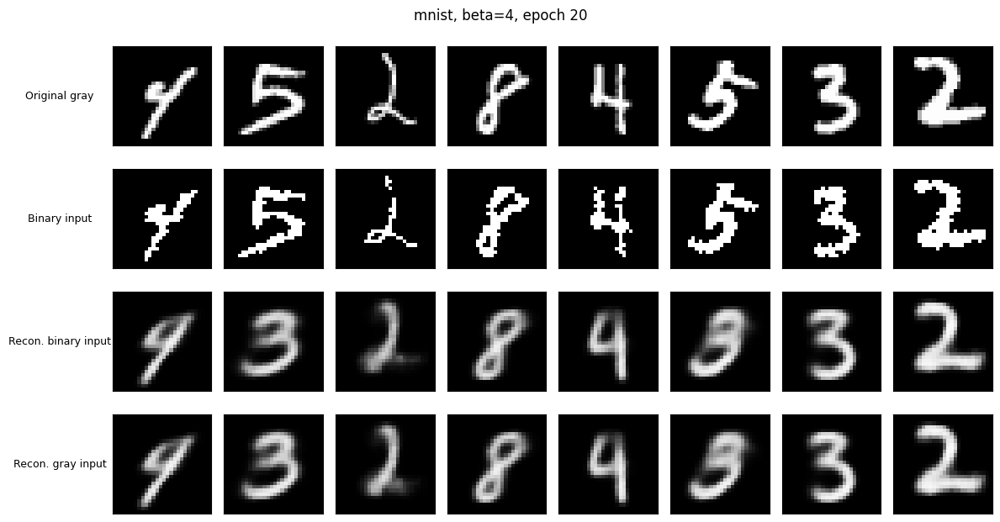

mnist beta=4 | 21/30 | val objective 143.18, recon 107.05, KL 9.03 | 1.5s
mnist beta=4 | 22/30 | val objective 142.78, recon 106.63, KL 9.04 | 1.4s
mnist beta=4 | 23/30 | val objective 142.93, recon 106.07, KL 9.22 | 1.5s
mnist beta=4 | 24/30 | val objective 143.20, recon 106.24, KL 9.24 | 1.5s
mnist beta=4 | 25/30 | val objective 142.67, recon 105.18, KL 9.37 | 1.4s
mnist beta=4 | 26/30 | val objective 142.40, recon 105.80, KL 9.15 | 1.5s
mnist beta=4 | 27/30 | val objective 142.19, recon 103.61, KL 9.65 | 1.4s
mnist beta=4 | 28/30 | val objective 141.91, recon 103.57, KL 9.58 | 1.4s
mnist beta=4 | 29/30 | val objective 141.79, recon 104.25, KL 9.38 | 1.4s
mnist beta=4 | 30/30 | val objective 141.77, recon 104.38, KL 9.35 | 1.4s


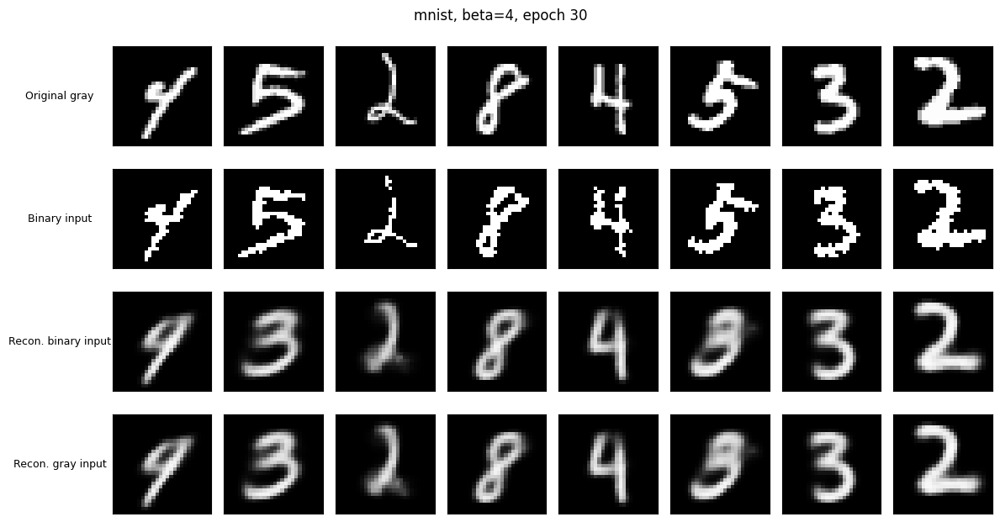

mnist beta=8 | 1/30 | val objective 199.57, recon 190.65, KL 1.12 | 1.5s


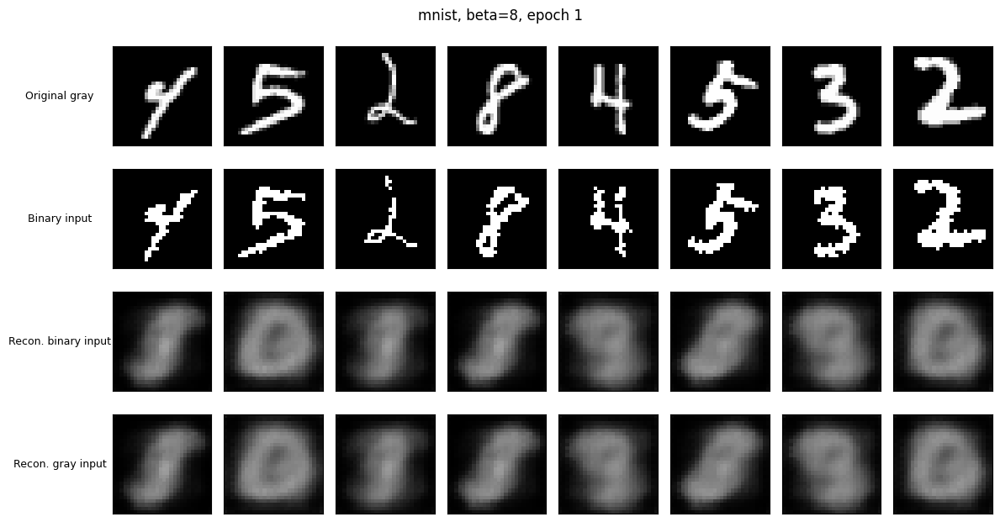

mnist beta=8 | 2/30 | val objective 189.56, recon 170.44, KL 2.39 | 1.5s
mnist beta=8 | 3/30 | val objective 182.99, recon 159.18, KL 2.98 | 1.5s
mnist beta=8 | 4/30 | val objective 180.84, recon 152.56, KL 3.53 | 1.4s
mnist beta=8 | 5/30 | val objective 178.59, recon 147.85, KL 3.84 | 1.4s
mnist beta=8 | 6/30 | val objective 177.63, recon 147.41, KL 3.78 | 1.4s
mnist beta=8 | 7/30 | val objective 176.99, recon 143.74, KL 4.16 | 1.4s
mnist beta=8 | 8/30 | val objective 175.95, recon 144.67, KL 3.91 | 1.5s
mnist beta=8 | 9/30 | val objective 175.17, recon 141.22, KL 4.24 | 1.4s
mnist beta=8 | 10/30 | val objective 174.97, recon 141.51, KL 4.18 | 1.4s


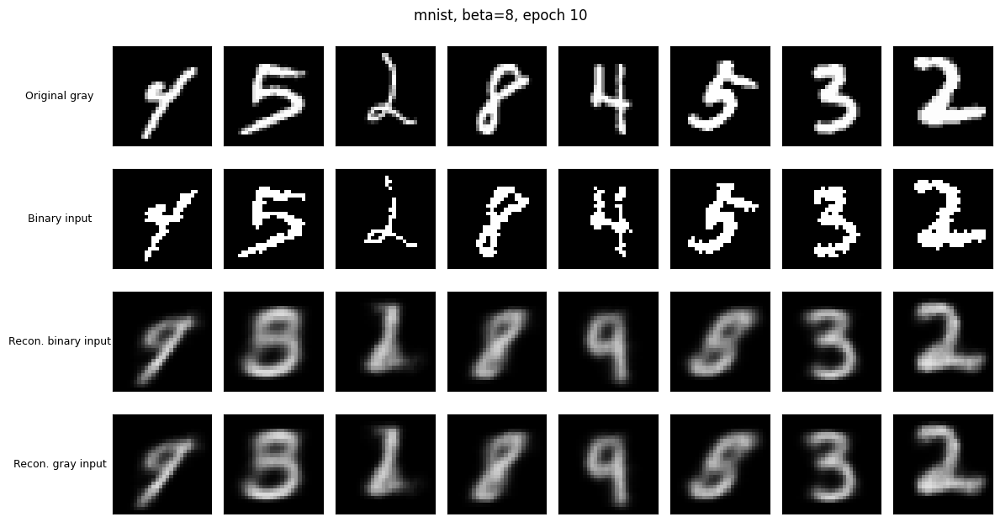

mnist beta=8 | 11/30 | val objective 174.48, recon 140.68, KL 4.22 | 1.5s
mnist beta=8 | 12/30 | val objective 174.11, recon 139.86, KL 4.28 | 1.5s
mnist beta=8 | 13/30 | val objective 173.73, recon 137.80, KL 4.49 | 1.4s
mnist beta=8 | 14/30 | val objective 173.57, recon 137.74, KL 4.48 | 1.5s
mnist beta=8 | 15/30 | val objective 173.37, recon 136.42, KL 4.62 | 1.5s
mnist beta=8 | 16/30 | val objective 173.06, recon 137.78, KL 4.41 | 1.4s
mnist beta=8 | 17/30 | val objective 173.07, recon 138.58, KL 4.31 | 1.4s
mnist beta=8 | 18/30 | val objective 172.62, recon 135.59, KL 4.63 | 1.5s
mnist beta=8 | 19/30 | val objective 172.74, recon 134.79, KL 4.74 | 1.4s
mnist beta=8 | 20/30 | val objective 172.38, recon 135.01, KL 4.67 | 1.5s


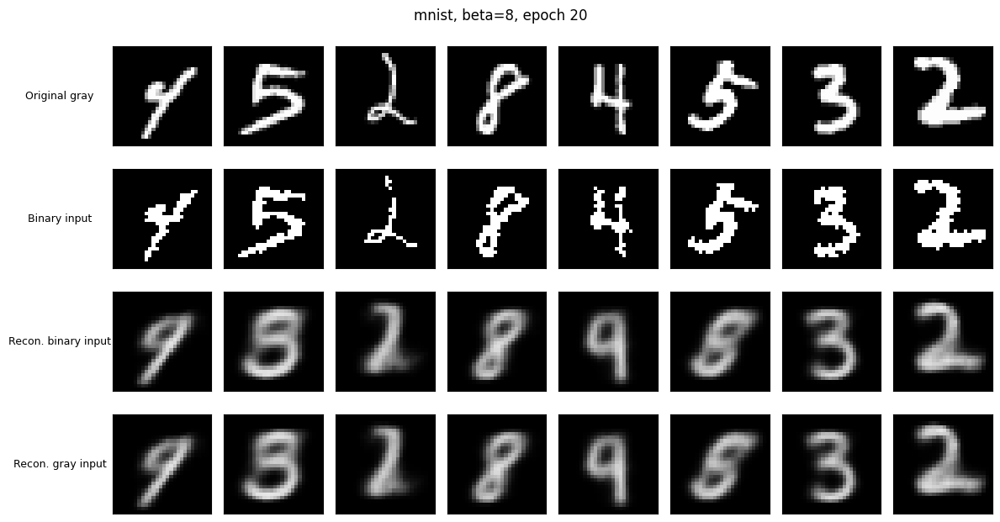

mnist beta=8 | 21/30 | val objective 172.19, recon 135.69, KL 4.56 | 1.5s
mnist beta=8 | 22/30 | val objective 172.23, recon 133.99, KL 4.78 | 1.4s
mnist beta=8 | 23/30 | val objective 172.16, recon 132.68, KL 4.93 | 1.4s
mnist beta=8 | 24/30 | val objective 171.86, recon 134.98, KL 4.61 | 1.5s
mnist beta=8 | 25/30 | val objective 171.78, recon 133.22, KL 4.82 | 1.6s
mnist beta=8 | 26/30 | val objective 171.62, recon 134.10, KL 4.69 | 1.6s
mnist beta=8 | 27/30 | val objective 171.83, recon 133.38, KL 4.81 | 1.6s
mnist beta=8 | 28/30 | val objective 171.52, recon 133.13, KL 4.80 | 1.6s
mnist beta=8 | 29/30 | val objective 171.45, recon 133.62, KL 4.73 | 1.5s
mnist beta=8 | 30/30 | val objective 171.40, recon 132.81, KL 4.82 | 1.6s


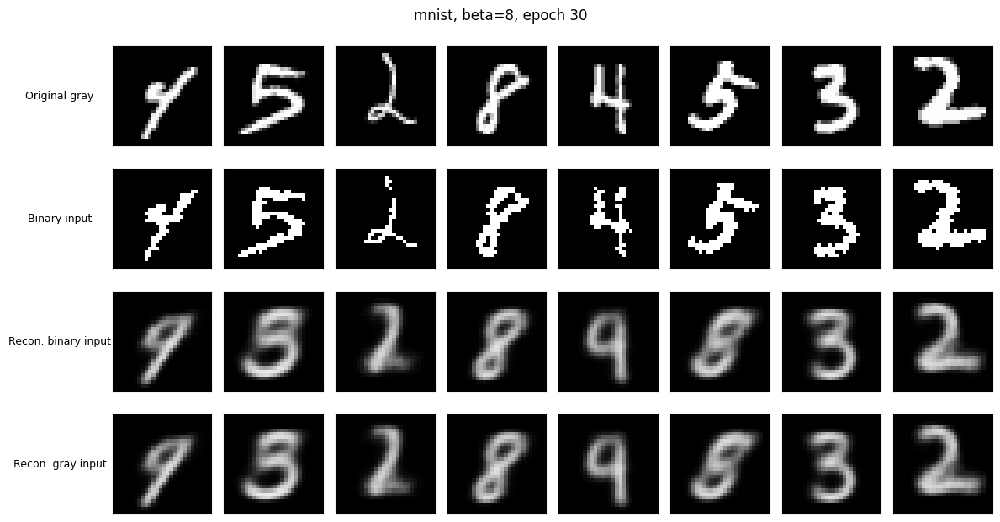

fashion_mnist beta=0.5 | 1/30 | val objective 265.03, recon 254.96, KL 20.15 | 1.6s


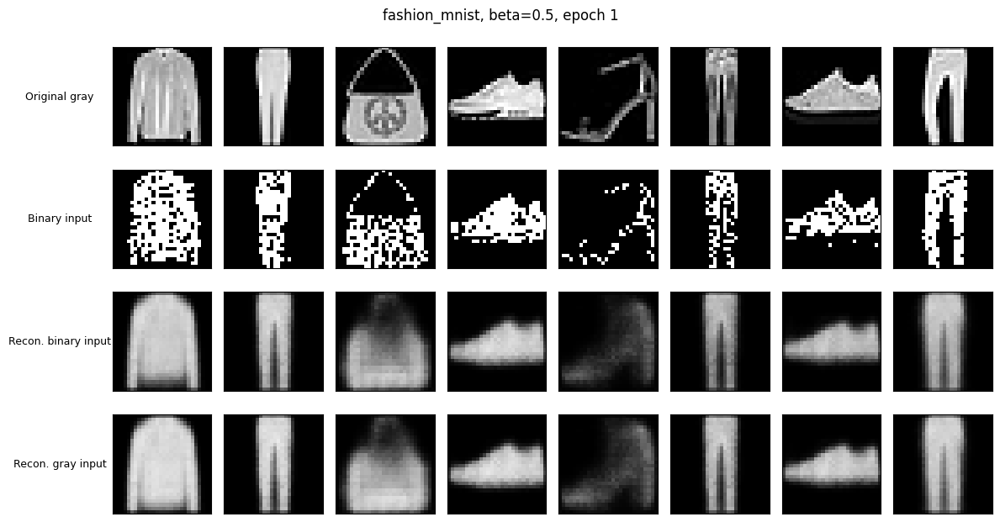

fashion_mnist beta=0.5 | 2/30 | val objective 251.71, recon 241.15, KL 21.12 | 1.6s
fashion_mnist beta=0.5 | 3/30 | val objective 245.44, recon 235.12, KL 20.63 | 1.6s
fashion_mnist beta=0.5 | 4/30 | val objective 241.22, recon 231.16, KL 20.12 | 1.6s
fashion_mnist beta=0.5 | 5/30 | val objective 239.66, recon 229.35, KL 20.62 | 1.5s
fashion_mnist beta=0.5 | 6/30 | val objective 236.42, recon 225.91, KL 21.01 | 1.6s
fashion_mnist beta=0.5 | 7/30 | val objective 235.47, recon 224.84, KL 21.27 | 1.6s
fashion_mnist beta=0.5 | 8/30 | val objective 233.14, recon 222.36, KL 21.55 | 1.6s
fashion_mnist beta=0.5 | 9/30 | val objective 232.14, recon 221.11, KL 22.05 | 1.7s
fashion_mnist beta=0.5 | 10/30 | val objective 231.26, recon 220.30, KL 21.92 | 1.5s


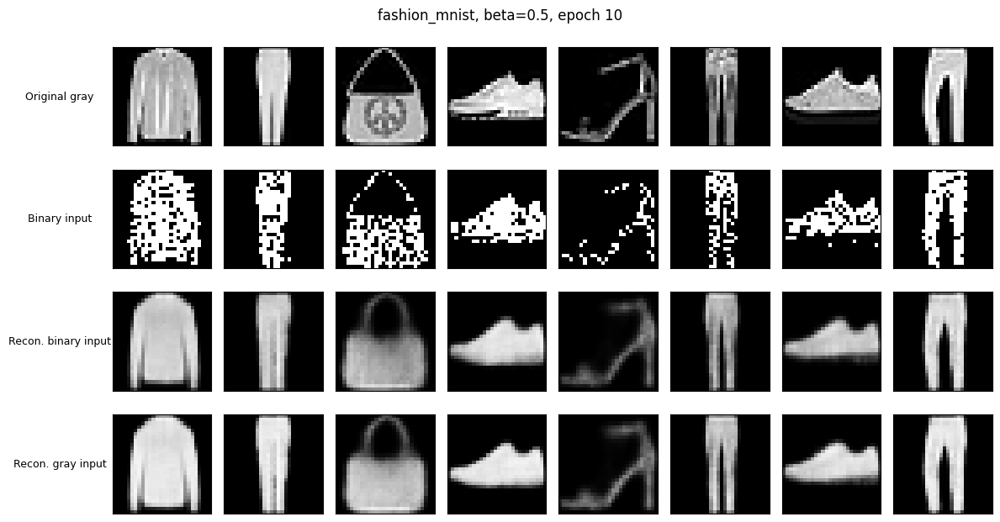

fashion_mnist beta=0.5 | 11/30 | val objective 230.78, recon 219.38, KL 22.80 | 1.5s
fashion_mnist beta=0.5 | 12/30 | val objective 229.96, recon 218.75, KL 22.43 | 1.5s
fashion_mnist beta=0.5 | 13/30 | val objective 229.43, recon 218.05, KL 22.77 | 1.5s
fashion_mnist beta=0.5 | 14/30 | val objective 228.58, recon 217.31, KL 22.56 | 1.5s
fashion_mnist beta=0.5 | 15/30 | val objective 228.59, recon 217.47, KL 22.24 | 1.5s
fashion_mnist beta=0.5 | 16/30 | val objective 227.98, recon 216.63, KL 22.69 | 1.5s
fashion_mnist beta=0.5 | 17/30 | val objective 228.59, recon 217.32, KL 22.55 | 1.5s
fashion_mnist beta=0.5 | 18/30 | val objective 227.74, recon 216.22, KL 23.04 | 1.5s
fashion_mnist beta=0.5 | 19/30 | val objective 227.33, recon 215.82, KL 23.03 | 1.5s
fashion_mnist beta=0.5 | 20/30 | val objective 226.81, recon 215.27, KL 23.07 | 1.5s


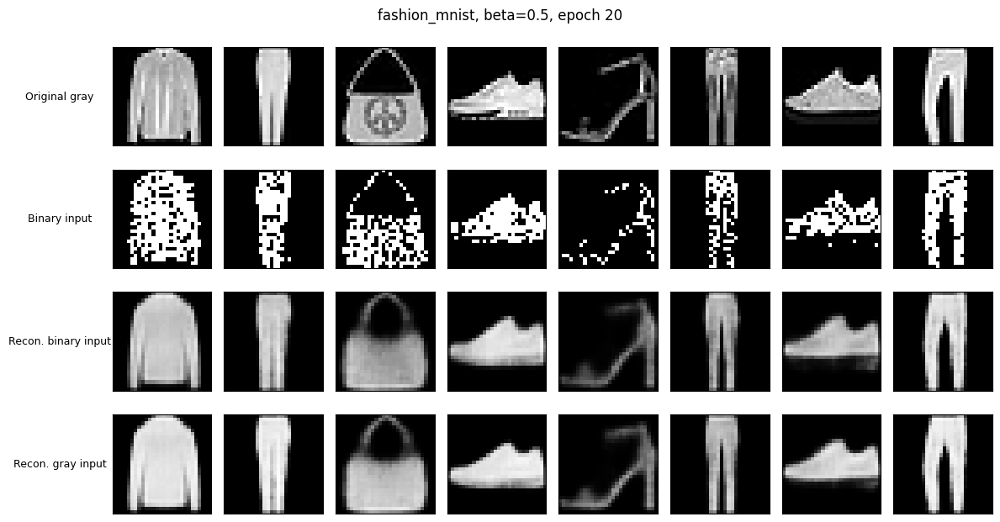

fashion_mnist beta=0.5 | 21/30 | val objective 226.81, recon 215.29, KL 23.05 | 1.5s
fashion_mnist beta=0.5 | 22/30 | val objective 226.69, recon 215.13, KL 23.10 | 1.4s
fashion_mnist beta=0.5 | 23/30 | val objective 226.63, recon 215.19, KL 22.88 | 1.4s
fashion_mnist beta=0.5 | 24/30 | val objective 226.23, recon 214.45, KL 23.55 | 1.4s
fashion_mnist beta=0.5 | 25/30 | val objective 227.01, recon 214.60, KL 24.83 | 1.4s
fashion_mnist beta=0.5 | 26/30 | val objective 226.23, recon 214.61, KL 23.24 | 1.5s
fashion_mnist beta=0.5 | 27/30 | val objective 226.02, recon 214.22, KL 23.61 | 1.4s
fashion_mnist beta=0.5 | 28/30 | val objective 225.69, recon 213.78, KL 23.81 | 1.5s
fashion_mnist beta=0.5 | 29/30 | val objective 225.97, recon 213.76, KL 24.42 | 1.5s
fashion_mnist beta=0.5 | 30/30 | val objective 225.42, recon 213.37, KL 24.09 | 1.5s


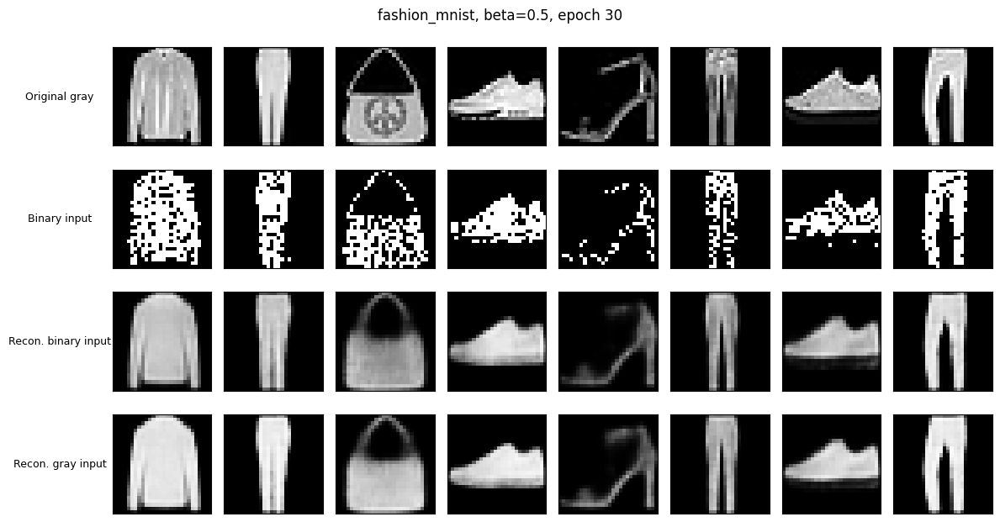

fashion_mnist beta=1 | 1/30 | val objective 273.82, recon 259.35, KL 14.48 | 1.5s


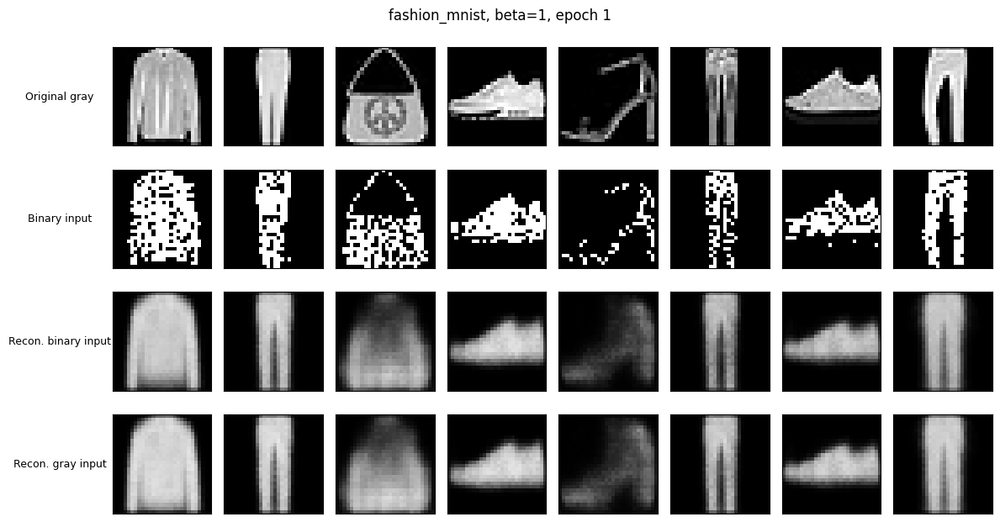

fashion_mnist beta=1 | 2/30 | val objective 259.60, recon 245.61, KL 14.00 | 1.5s
fashion_mnist beta=1 | 3/30 | val objective 253.90, recon 240.27, KL 13.63 | 1.4s
fashion_mnist beta=1 | 4/30 | val objective 249.69, recon 235.56, KL 14.12 | 1.4s
fashion_mnist beta=1 | 5/30 | val objective 247.11, recon 233.02, KL 14.09 | 1.4s
fashion_mnist beta=1 | 6/30 | val objective 245.36, recon 231.50, KL 13.86 | 1.5s
fashion_mnist beta=1 | 7/30 | val objective 243.65, recon 229.65, KL 14.00 | 1.6s
fashion_mnist beta=1 | 8/30 | val objective 242.67, recon 228.38, KL 14.28 | 1.5s
fashion_mnist beta=1 | 9/30 | val objective 241.79, recon 227.03, KL 14.75 | 1.5s
fashion_mnist beta=1 | 10/30 | val objective 241.77, recon 226.82, KL 14.95 | 1.5s


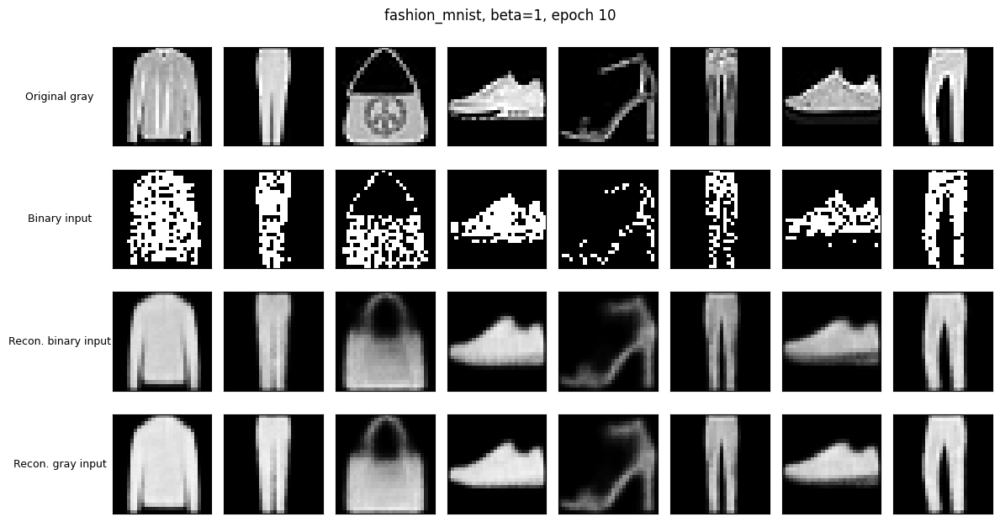

fashion_mnist beta=1 | 11/30 | val objective 240.61, recon 225.56, KL 15.05 | 1.5s
fashion_mnist beta=1 | 12/30 | val objective 240.32, recon 224.89, KL 15.43 | 1.4s
fashion_mnist beta=1 | 13/30 | val objective 239.77, recon 224.97, KL 14.80 | 1.5s
fashion_mnist beta=1 | 14/30 | val objective 239.04, recon 224.27, KL 14.77 | 1.5s
fashion_mnist beta=1 | 15/30 | val objective 238.45, recon 223.06, KL 15.39 | 1.4s
fashion_mnist beta=1 | 16/30 | val objective 238.18, recon 222.77, KL 15.41 | 1.5s
fashion_mnist beta=1 | 17/30 | val objective 237.93, recon 222.89, KL 15.04 | 1.4s
fashion_mnist beta=1 | 18/30 | val objective 237.73, recon 222.26, KL 15.47 | 1.5s
fashion_mnist beta=1 | 19/30 | val objective 237.98, recon 221.61, KL 16.38 | 1.5s
fashion_mnist beta=1 | 20/30 | val objective 237.25, recon 221.84, KL 15.42 | 1.4s


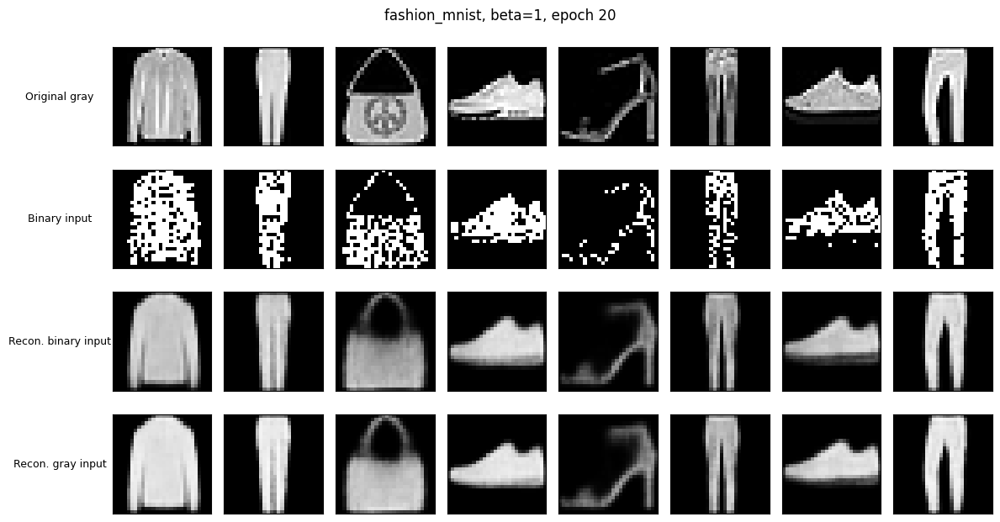

fashion_mnist beta=1 | 21/30 | val objective 237.13, recon 221.32, KL 15.81 | 1.5s
fashion_mnist beta=1 | 22/30 | val objective 236.89, recon 221.72, KL 15.17 | 1.5s
fashion_mnist beta=1 | 23/30 | val objective 237.13, recon 221.73, KL 15.40 | 1.4s
fashion_mnist beta=1 | 24/30 | val objective 237.25, recon 220.92, KL 16.33 | 1.4s
fashion_mnist beta=1 | 25/30 | val objective 236.37, recon 220.30, KL 16.06 | 1.5s
fashion_mnist beta=1 | 26/30 | val objective 237.03, recon 221.41, KL 15.62 | 1.5s
fashion_mnist beta=1 | 27/30 | val objective 236.47, recon 220.65, KL 15.83 | 1.4s
fashion_mnist beta=1 | 28/30 | val objective 236.23, recon 220.95, KL 15.28 | 1.4s
fashion_mnist beta=1 | 29/30 | val objective 235.93, recon 219.71, KL 16.21 | 1.4s
fashion_mnist beta=1 | 30/30 | val objective 235.81, recon 219.81, KL 16.00 | 1.4s


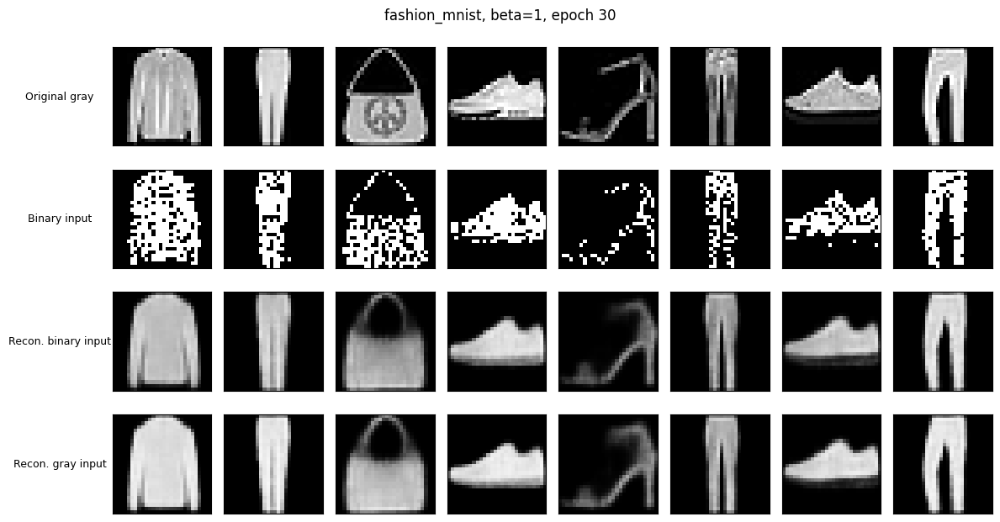

fashion_mnist beta=4 | 1/30 | val objective 300.25, recon 275.67, KL 6.15 | 1.5s


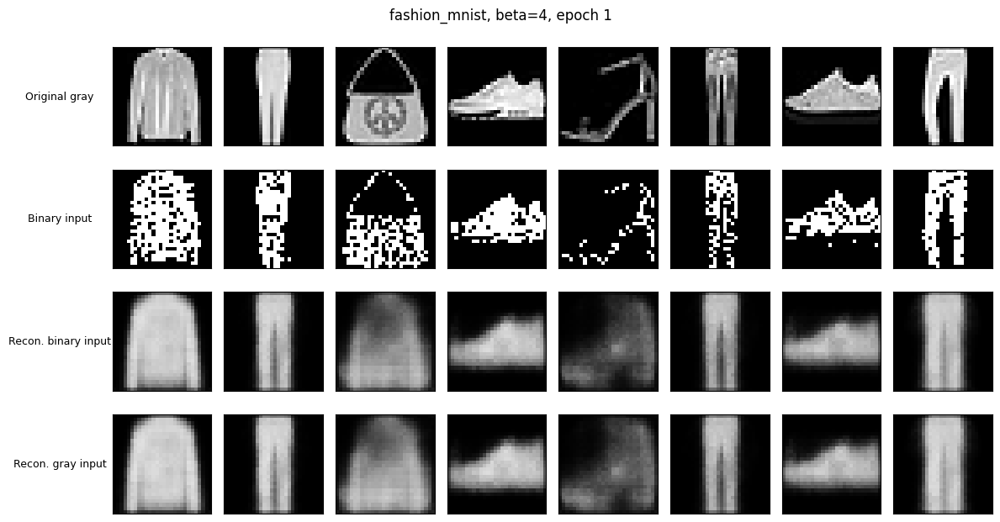

fashion_mnist beta=4 | 2/30 | val objective 284.92, recon 260.90, KL 6.01 | 1.5s
fashion_mnist beta=4 | 3/30 | val objective 280.26, recon 256.50, KL 5.94 | 1.4s
fashion_mnist beta=4 | 4/30 | val objective 275.70, recon 251.66, KL 6.01 | 1.4s
fashion_mnist beta=4 | 5/30 | val objective 273.81, recon 250.03, KL 5.94 | 1.5s
fashion_mnist beta=4 | 6/30 | val objective 273.33, recon 249.36, KL 5.99 | 1.5s
fashion_mnist beta=4 | 7/30 | val objective 271.26, recon 246.47, KL 6.20 | 1.4s
fashion_mnist beta=4 | 8/30 | val objective 270.72, recon 245.42, KL 6.32 | 1.5s
fashion_mnist beta=4 | 9/30 | val objective 270.30, recon 245.81, KL 6.12 | 1.5s
fashion_mnist beta=4 | 10/30 | val objective 269.58, recon 244.55, KL 6.26 | 1.5s


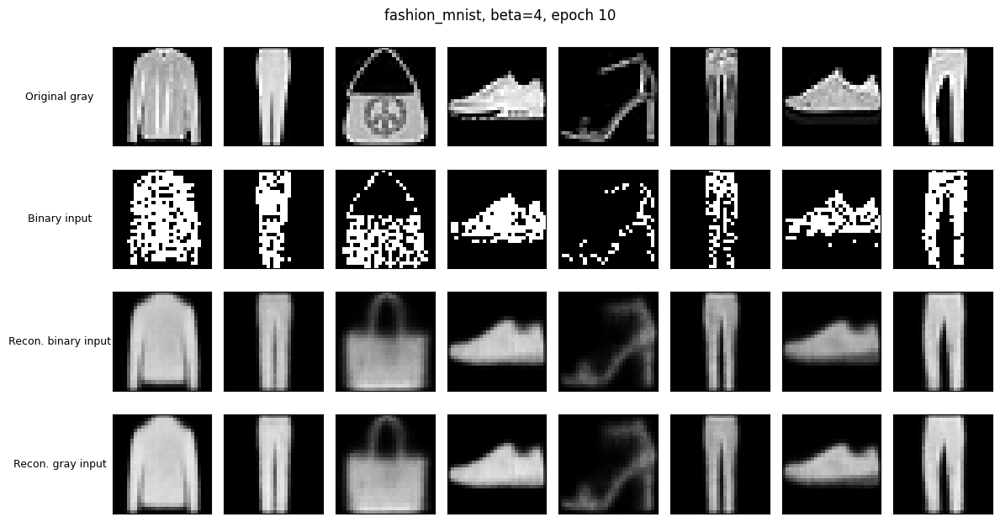

fashion_mnist beta=4 | 11/30 | val objective 269.33, recon 244.31, KL 6.25 | 1.5s
fashion_mnist beta=4 | 12/30 | val objective 268.38, recon 243.17, KL 6.30 | 1.4s
fashion_mnist beta=4 | 13/30 | val objective 268.57, recon 241.30, KL 6.82 | 1.5s
fashion_mnist beta=4 | 14/30 | val objective 268.28, recon 242.60, KL 6.42 | 1.4s
fashion_mnist beta=4 | 15/30 | val objective 268.15, recon 240.86, KL 6.82 | 1.4s
fashion_mnist beta=4 | 16/30 | val objective 269.06, recon 241.26, KL 6.95 | 1.4s
fashion_mnist beta=4 | 17/30 | val objective 267.40, recon 241.52, KL 6.47 | 1.5s
fashion_mnist beta=4 | 18/30 | val objective 267.30, recon 241.38, KL 6.48 | 1.5s
fashion_mnist beta=4 | 19/30 | val objective 267.38, recon 240.44, KL 6.74 | 1.4s
fashion_mnist beta=4 | 20/30 | val objective 267.14, recon 241.03, KL 6.53 | 1.4s


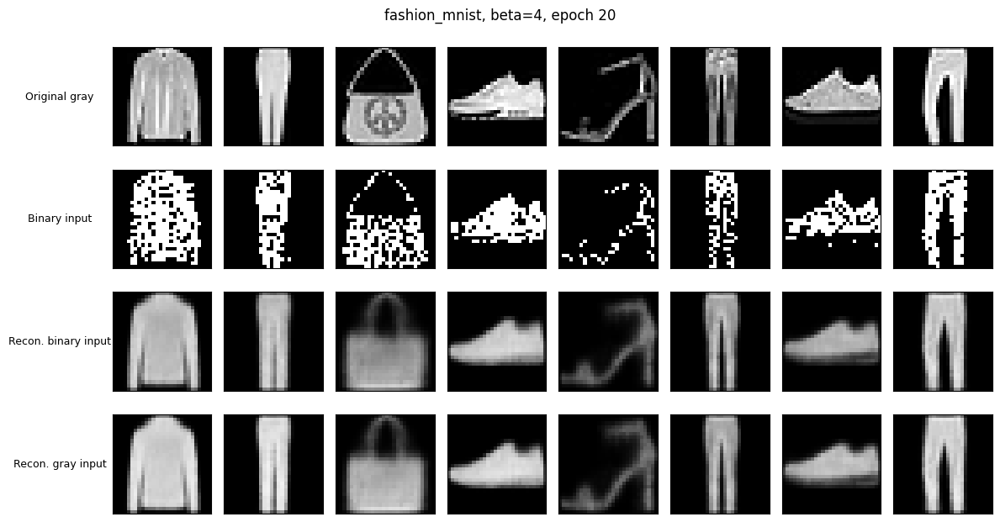

fashion_mnist beta=4 | 21/30 | val objective 266.76, recon 239.93, KL 6.71 | 1.5s
fashion_mnist beta=4 | 22/30 | val objective 266.92, recon 239.23, KL 6.92 | 1.4s
fashion_mnist beta=4 | 23/30 | val objective 266.68, recon 240.22, KL 6.61 | 1.4s
fashion_mnist beta=4 | 24/30 | val objective 266.72, recon 239.19, KL 6.88 | 1.4s
fashion_mnist beta=4 | 25/30 | val objective 266.21, recon 237.88, KL 7.08 | 1.5s
fashion_mnist beta=4 | 26/30 | val objective 266.69, recon 239.94, KL 6.69 | 1.4s
fashion_mnist beta=4 | 27/30 | val objective 266.32, recon 239.28, KL 6.76 | 1.4s
fashion_mnist beta=4 | 28/30 | val objective 266.19, recon 239.56, KL 6.66 | 1.5s
fashion_mnist beta=4 | 29/30 | val objective 266.14, recon 239.83, KL 6.58 | 1.5s
fashion_mnist beta=4 | 30/30 | val objective 265.83, recon 238.83, KL 6.75 | 1.4s


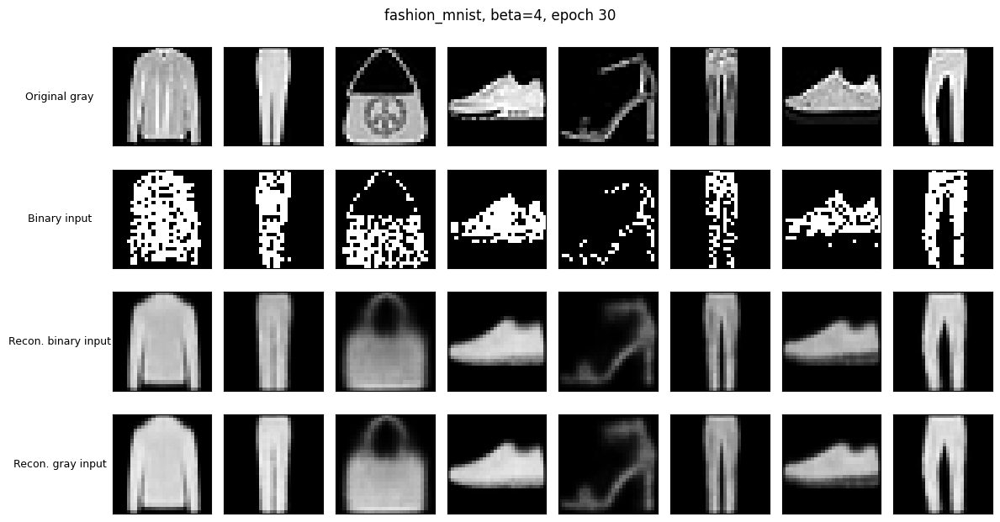

fashion_mnist beta=8 | 1/30 | val objective 322.47, recon 292.92, KL 3.69 | 1.5s


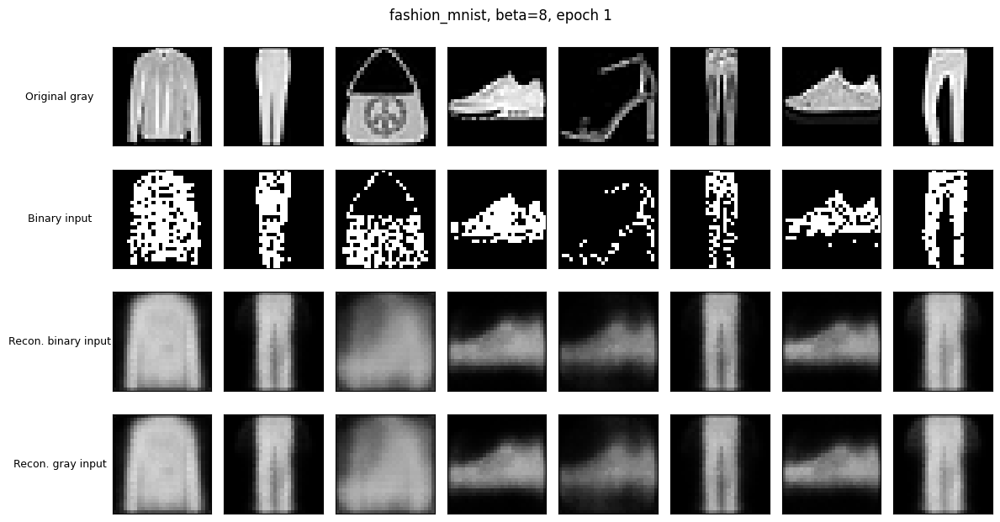

fashion_mnist beta=8 | 2/30 | val objective 305.70, recon 273.20, KL 4.06 | 1.5s
fashion_mnist beta=8 | 3/30 | val objective 298.71, recon 266.62, KL 4.01 | 1.4s
fashion_mnist beta=8 | 4/30 | val objective 296.73, recon 266.67, KL 3.76 | 1.5s
fashion_mnist beta=8 | 5/30 | val objective 294.39, recon 262.60, KL 3.97 | 1.4s
fashion_mnist beta=8 | 6/30 | val objective 293.43, recon 260.13, KL 4.16 | 1.5s
fashion_mnist beta=8 | 7/30 | val objective 293.19, recon 259.14, KL 4.26 | 1.5s
fashion_mnist beta=8 | 8/30 | val objective 292.44, recon 258.76, KL 4.21 | 1.4s
fashion_mnist beta=8 | 9/30 | val objective 291.72, recon 257.49, KL 4.28 | 1.5s
fashion_mnist beta=8 | 10/30 | val objective 291.76, recon 258.46, KL 4.16 | 1.5s


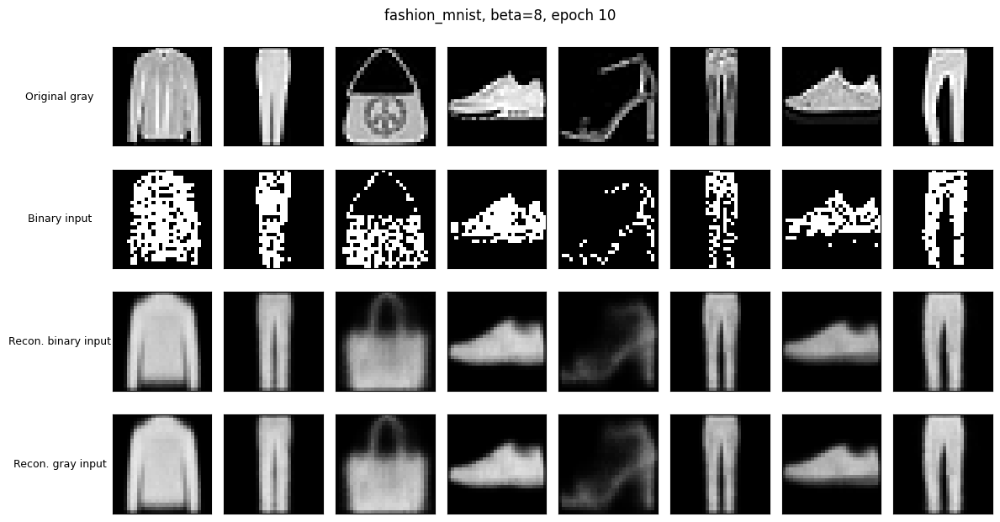

fashion_mnist beta=8 | 11/30 | val objective 291.59, recon 257.50, KL 4.26 | 1.4s
fashion_mnist beta=8 | 12/30 | val objective 290.50, recon 257.07, KL 4.18 | 1.5s
fashion_mnist beta=8 | 13/30 | val objective 291.47, recon 258.45, KL 4.13 | 1.5s
fashion_mnist beta=8 | 14/30 | val objective 290.82, recon 253.75, KL 4.63 | 1.4s
fashion_mnist beta=8 | 15/30 | val objective 289.96, recon 256.73, KL 4.15 | 1.4s
fashion_mnist beta=8 | 16/30 | val objective 289.55, recon 255.36, KL 4.27 | 1.5s
fashion_mnist beta=8 | 17/30 | val objective 289.62, recon 255.24, KL 4.30 | 1.4s
fashion_mnist beta=8 | 18/30 | val objective 289.60, recon 254.29, KL 4.41 | 1.4s
fashion_mnist beta=8 | 19/30 | val objective 289.09, recon 252.91, KL 4.52 | 1.4s
fashion_mnist beta=8 | 20/30 | val objective 289.33, recon 254.01, KL 4.42 | 1.4s


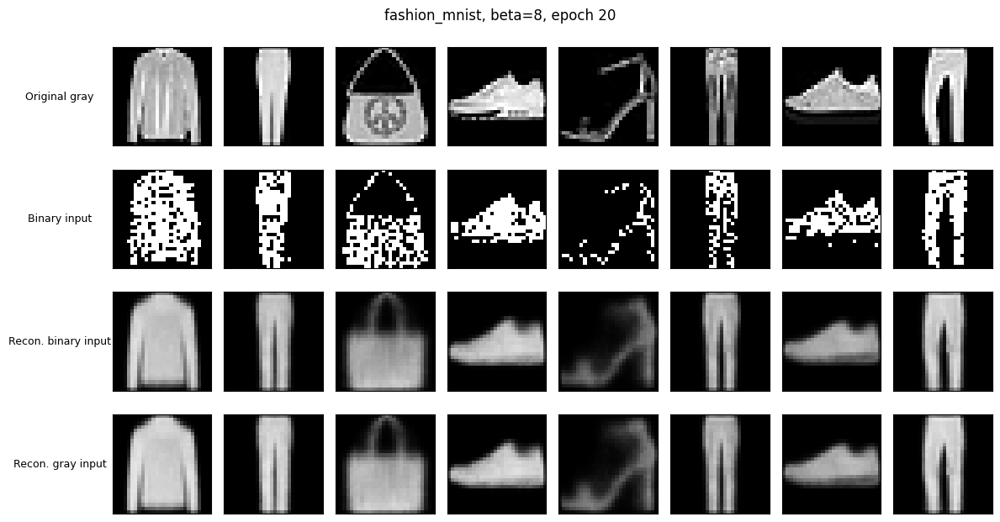

fashion_mnist beta=8 | 21/30 | val objective 288.83, recon 254.82, KL 4.25 | 1.5s
fashion_mnist beta=8 | 22/30 | val objective 289.04, recon 254.62, KL 4.30 | 1.4s
fashion_mnist beta=8 | 23/30 | val objective 289.03, recon 253.71, KL 4.41 | 1.4s
fashion_mnist beta=8 | 24/30 | val objective 288.65, recon 253.23, KL 4.43 | 1.4s
fashion_mnist beta=8 | 25/30 | val objective 288.76, recon 252.00, KL 4.59 | 1.4s
fashion_mnist beta=8 | 26/30 | val objective 288.38, recon 254.26, KL 4.27 | 1.4s
fashion_mnist beta=8 | 27/30 | val objective 288.72, recon 253.60, KL 4.39 | 1.4s
fashion_mnist beta=8 | 28/30 | val objective 288.93, recon 252.82, KL 4.51 | 1.5s
fashion_mnist beta=8 | 29/30 | val objective 288.30, recon 253.05, KL 4.41 | 1.4s
fashion_mnist beta=8 | 30/30 | val objective 288.48, recon 251.73, KL 4.59 | 1.4s


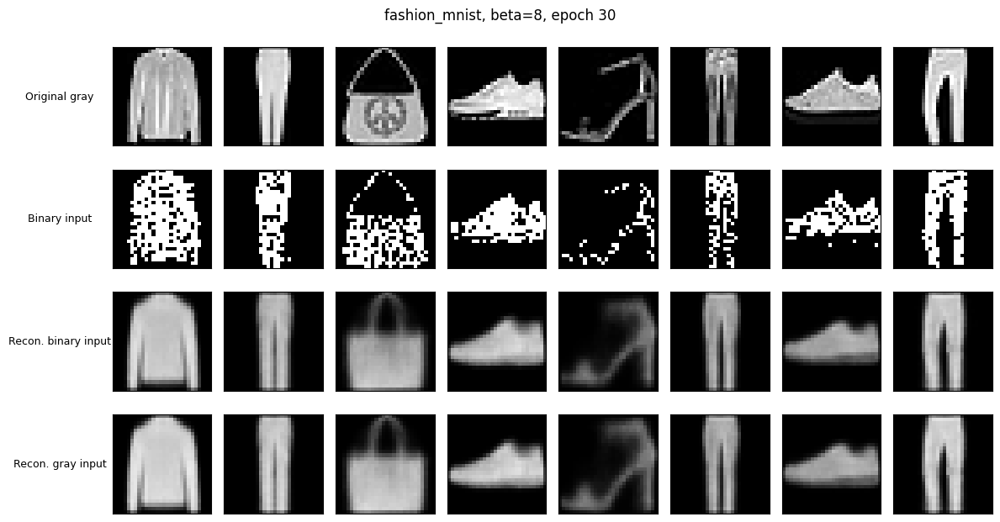

,dataset,beta,best_epoch,val_beta_objective,parameters,seconds
0,mnist,0.5,30,79.922311,1700609,44.784737
1,mnist,1.0,29,96.324648,1700609,44.010309
2,mnist,4.0,30,141.765127,1700609,43.406597
3,mnist,8.0,30,171.400423,1700609,44.093586
4,fashion_mnist,0.5,30,225.419721,1700609,45.415509
5,fashion_mnist,1.0,30,235.810999,1700609,43.919774
6,fashion_mnist,4.0,30,265.825346,1700609,43.335623
7,fashion_mnist,8.0,29,288.298726,1700609,43.299795


In [50]:
def train_beta_vae(dataset,beta):
    seed_all()
    train,val=training_loaders(dataset)
    model=ConvVAE(BETA_LATENT_DIM).to(DEVICE)
    seed_all()
    optimizer=torch.optim.Adam(model.parameters(),lr=BETA_LEARNING_RATE)
    folder=BETA_RESULTS/dataset/f'beta_{beta_tag(beta)}'
    folder.mkdir(parents=True,exist_ok=True)
    checkpoint=BETA_CHECKPOINTS/f'{dataset}_beta_{beta_tag(beta)}.pt'
    epochs=2 if SMOKE_TEST else BETA_EPOCHS
    config=dict(dataset=dataset,beta=beta,latent_dim=BETA_LATENT_DIM,epochs=epochs,
                learning_rate=BETA_LEARNING_RATE,batch_size=BATCH_SIZE,seed=SEED,
                train_size=len(train.dataset),validation_size=len(val.dataset),
                checkpoint_metric='validation reconstruction_nll + beta * kl',
                observation_model='Bernoulli on dynamically binarized images',
                parameters=sum(p.numel() for p in model.parameters()),smoke_test=SMOKE_TEST)
    (folder/'config.json').write_text(json.dumps(config,indent=2))
    examples=next(iter(val))[0][:8]
    best,history=float('inf'),[]
    for epoch in range(1,epochs+1):
        started=time.perf_counter()
        model.train()
        totals=dict(reconstruction_nll=0.,kl=0.,negative_elbo=0.,beta_objective=0.)
        count=0
        for gray,_ in train:
            x=torch.bernoulli(gray.to(DEVICE))
            optimizer.zero_grad(set_to_none=True)
            logits,mu,lv=model(x)
            recon,kl,objective=beta_loss_terms(logits,x,mu,lv,beta)
            loss=objective.mean()
            if not torch.isfinite(loss): raise FloatingPointError('Non-finite beta loss')
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(),5.,error_if_nonfinite=True)
            optimizer.step()
            for key,value in [('reconstruction_nll',recon),('kl',kl),
                              ('negative_elbo',recon+kl),('beta_objective',objective)]:
                totals[key]+=value.sum().item()
            count+=len(x)
        validation=evaluate_beta_vae(model,val,beta)
        row=dict(epoch=epoch,**{'train_'+key:value/count for key,value in totals.items()},
                 **{'val_'+key:value for key,value in validation.items()},
                 seconds=time.perf_counter()-started)
        history.append(row)
        pd.DataFrame(history).to_csv(folder/'history.csv',index=False)
        if validation['beta_objective']<best:
            best=validation['beta_objective']
            torch.save(dict(model=model.state_dict(),epoch=epoch,config=config),checkpoint)
        print(f'{dataset} beta={beta:g} | {epoch}/{epochs} | val objective {validation["beta_objective"]:.2f}, recon {validation["reconstruction_nll"]:.2f}, KL {validation["kl"]:.2f} | {row["seconds"]:.1f}s',flush=True)
        if epoch==1 or epoch%10==0 or epoch==epochs:
            vae_reconstruction_preview(model,examples,f'{dataset}, beta={beta:g}, epoch {epoch}',
                                       folder/f'reconstruction_epoch_{epoch:03d}.png')
    saved=torch.load(checkpoint,map_location=DEVICE,weights_only=True)
    return dict(dataset=dataset,beta=beta,checkpoint=str(checkpoint),best_epoch=saved['epoch'],
                val_beta_objective=best,parameters=config['parameters'],
                seconds=sum(row['seconds'] for row in history))

beta_runs=[]
for dataset in DATASET_NAMES:
    for beta in BETA_VALUES:
        beta_runs.append(train_beta_vae(dataset,beta))
        pd.DataFrame([{k:v for k,v in r.items() if k!='checkpoint'} for r in beta_runs]).to_csv(BETA_RESULTS/'validation_comparison.csv',index=False)
display(pd.DataFrame([{k:v for k,v in r.items() if k!='checkpoint'} for r in beta_runs]))


### 4.3 Reconstruction, likelihood bounds and diversity

The results separate reconstruction error, unweighted KL, ordinary ELBO and importance-weighted bounds from the beta-weighted training objective. Matched prior grids and pairwise pixel MSE describe generation changes. Pixel variation is not a measure of semantic diversity or class coverage.


In [51]:
beta_test_rows=[]
for run in beta_runs:
    model=ConvVAE(BETA_LATENT_DIM).to(DEVICE)
    model.load_state_dict(torch.load(run['checkpoint'],map_location=DEVICE,weights_only=True)['model'])
    ds=testing_loader(run['dataset']).dataset
    loader=DataLoader(ds,batch_size=64,shuffle=False,num_workers=0)
    k=2 if SMOKE_TEST else BETA_IMPORTANCE_SAMPLES
    values=evaluate_beta_vae(model,loader,run['beta'],importance_samples=k,seed=3030)
    probabilities,_=model.sample(n=64,seed=123)
    pairwise_mse=torch.pdist(probabilities.flatten(1),p=2).square().mean().item()/784
    beta_test_rows.append(dict(dataset=run['dataset'],beta=run['beta'],best_epoch=run['best_epoch'],
                               importance_samples=k,**values,prior_pairwise_pixel_mse=pairwise_mse,
                               smoke_test=SMOKE_TEST))
beta_test_results=pd.DataFrame(beta_test_rows)
beta_test_results.to_csv(BETA_RESULTS/'test_results.csv',index=False)
display(beta_test_results)


,dataset,beta,best_epoch,importance_samples,reconstruction_nll,kl,negative_elbo,negative_iwae_estimate,gray_mse,beta_objective,prior_pairwise_pixel_mse,smoke_test
0,mnist,0.5,30,16,61.586980,35.644679,97.231660,93.806649,0.006360,79.409320,0.099261,False
1,mnist,1.0,29,16,72.614591,23.043220,95.657810,91.929830,0.009116,95.657811,0.092374,False
2,mnist,4.0,30,16,103.658912,9.366543,113.025454,103.465634,0.018186,141.125082,0.082659,False
3,mnist,8.0,30,16,132.626607,4.824788,137.451395,123.963071,0.029530,171.224913,0.051775,False
4,fashion_mnist,0.5,30,16,214.497832,24.045486,238.543316,235.956572,0.017166,226.520574,0.129051,False
5,fashion_mnist,1.0,30,16,221.044617,15.948320,236.992935,234.615776,0.018464,236.992936,0.124261,False
6,fashion_mnist,4.0,30,16,239.966025,6.716133,246.682157,240.329088,0.021895,266.830555,0.133997,False
7,fashion_mnist,8.0,29,16,254.363336,4.383610,258.746946,249.012206,0.024790,289.432217,0.121264,False


### 4.4 Latent usage on validation data

For all 32 coordinates, the analysis measured mean KL and posterior-mean variance $\mathrm{Var}_x[\mu_j(x)]$ using fixed validation binarization. A coordinate was counted as active when this variance exceeded 0.01.

Mean absolute off-diagonal correlation was calculated among active coordinates, or reported as NaN when fewer than two were active. Higher beta reduced active-unit counts in the saved runs. These statistics describe latent usage and linear dependence, not independent semantic factors.


In [52]:
@torch.no_grad()
def beta_latent_diagnostics(model,loader):
    model.eval()
    generator=torch.Generator(device=DEVICE).manual_seed(2026)
    means,kls=[],[]
    for gray,_ in loader:
        binary=torch.bernoulli(gray.to(DEVICE),generator=generator)
        mu,lv=model.encode(binary)
        means.append(mu.cpu())
        kls.append((0.5*(mu.square()+lv.exp()-1-lv)).cpu())
    means=torch.cat(means)
    mean_kl=torch.cat(kls).mean(0)
    variance=means.var(0,unbiased=False)
    active=variance>BETA_ACTIVE_THRESHOLD
    active_count=int(active.sum())
    correlation=float('nan')
    if active_count>=2:
        corr=np.corrcoef(means[:,active].numpy(),rowvar=False)
        correlation=float(np.abs(corr[np.triu_indices(active_count,k=1)]).mean())
    per_dimension=pd.DataFrame(dict(dimension=np.arange(model.latent_dim),
                                    mean_kl_nats=mean_kl.numpy(),posterior_mean_variance=variance.numpy(),
                                    active_by_variance=active.numpy()))
    top=per_dimension.sort_values(['mean_kl_nats','dimension'],ascending=[False,True]).dimension.tolist()
    return per_dimension,dict(active_units=active_count,mean_abs_active_correlation=correlation),top

beta_diagnostic_rows=[]
beta_traversal_dimensions={}
for run in beta_runs:
    dataset,beta=run['dataset'],run['beta']
    model=ConvVAE(BETA_LATENT_DIM).to(DEVICE)
    model.load_state_dict(torch.load(run['checkpoint'],map_location=DEVICE,weights_only=True)['model'])
    _,validation=training_loaders(dataset)
    per_dimension,values,top=beta_latent_diagnostics(model,validation)
    folder=BETA_RESULTS/dataset/f'beta_{beta_tag(beta)}'
    per_dimension.to_csv(folder/'validation_latent_dimensions.csv',index=False)
    selected=top[:(3 if SMOKE_TEST else BETA_TRAVERSAL_DIMS)]
    beta_traversal_dimensions[(dataset,beta)]=selected
    (folder/'traversal_dimensions.json').write_text(json.dumps(dict(selection='highest validation mean KL',
                                                                  dimensions=selected,
                                                                  active_variance_threshold=BETA_ACTIVE_THRESHOLD),indent=2))
    beta_diagnostic_rows.append(dict(dataset=dataset,beta=beta,**values))
beta_diagnostics=pd.DataFrame(beta_diagnostic_rows)
beta_diagnostics.to_csv(BETA_RESULTS/'latent_diagnostics.csv',index=False)
display(beta_diagnostics)


,dataset,beta,active_units,mean_abs_active_correlation
0,mnist,0.5,20,0.035879
1,mnist,1.0,14,0.033376
2,mnist,4.0,14,0.186227
3,mnist,8.0,5,0.024695
4,fashion_mnist,0.5,24,0.155071
5,fashion_mnist,1.0,20,0.252230
6,fashion_mnist,4.0,6,0.021088
7,fashion_mnist,8.0,4,0.017083


### 4.5 One-coordinate latent traversals

Eight coordinates were selected by validation mean KL. Each was varied from -3 to 3 while the others stayed fixed, using both a zero prior anchor and the same validation-image anchor. The panels show changes in shape and style, but several properties can change together.


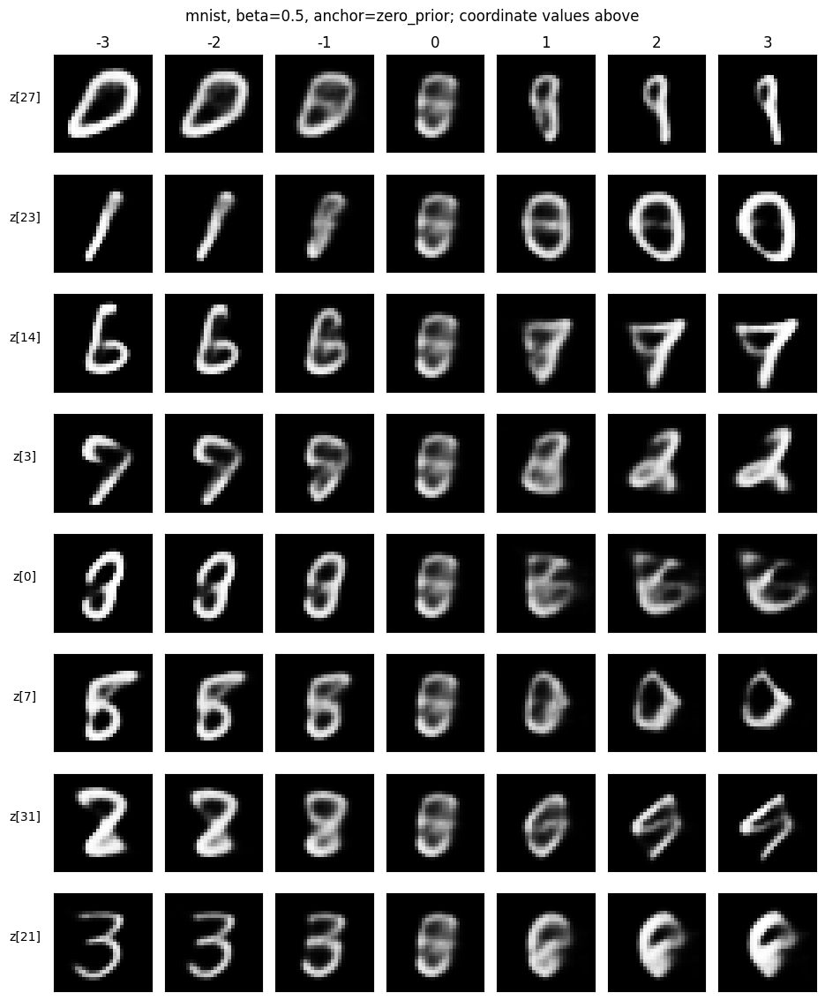

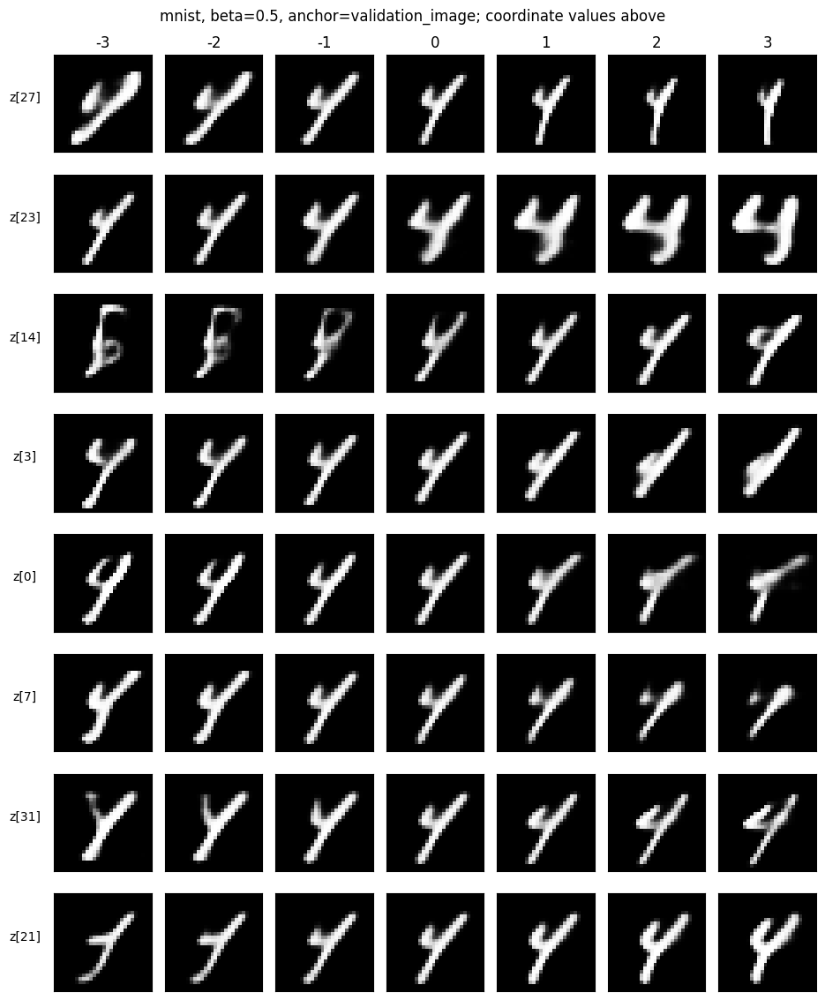

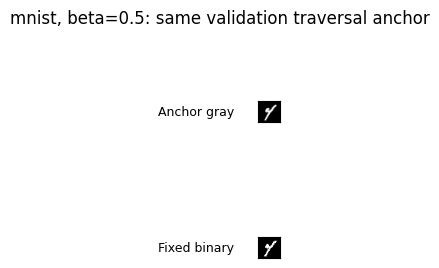

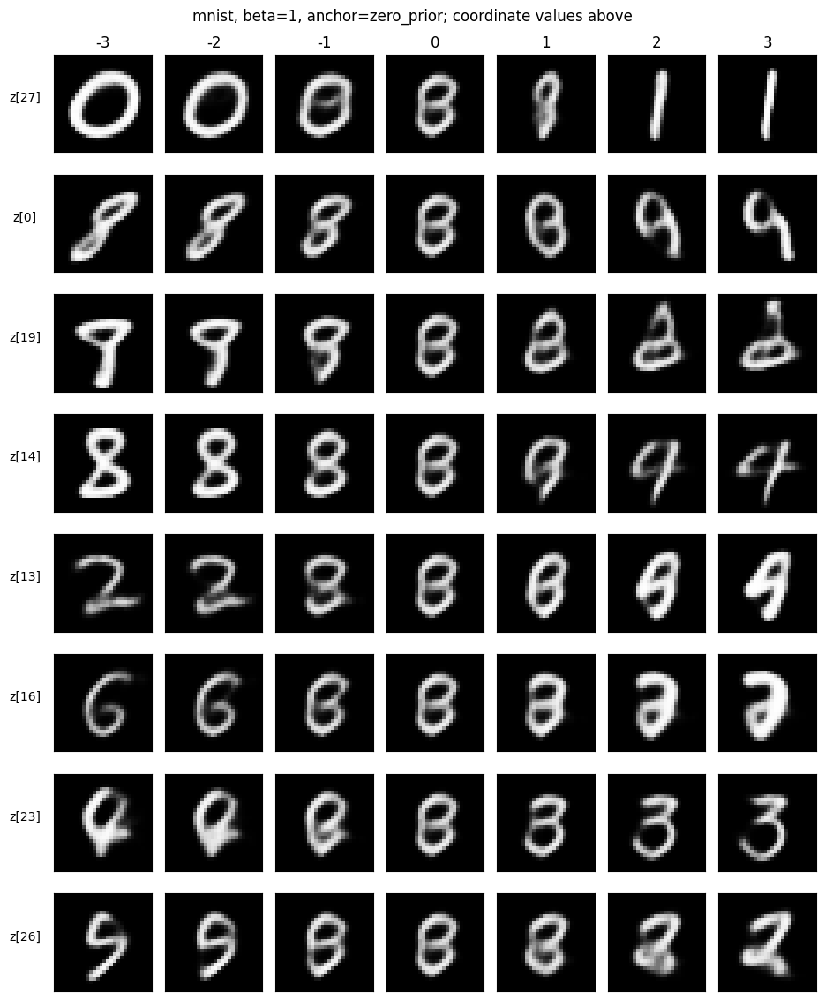

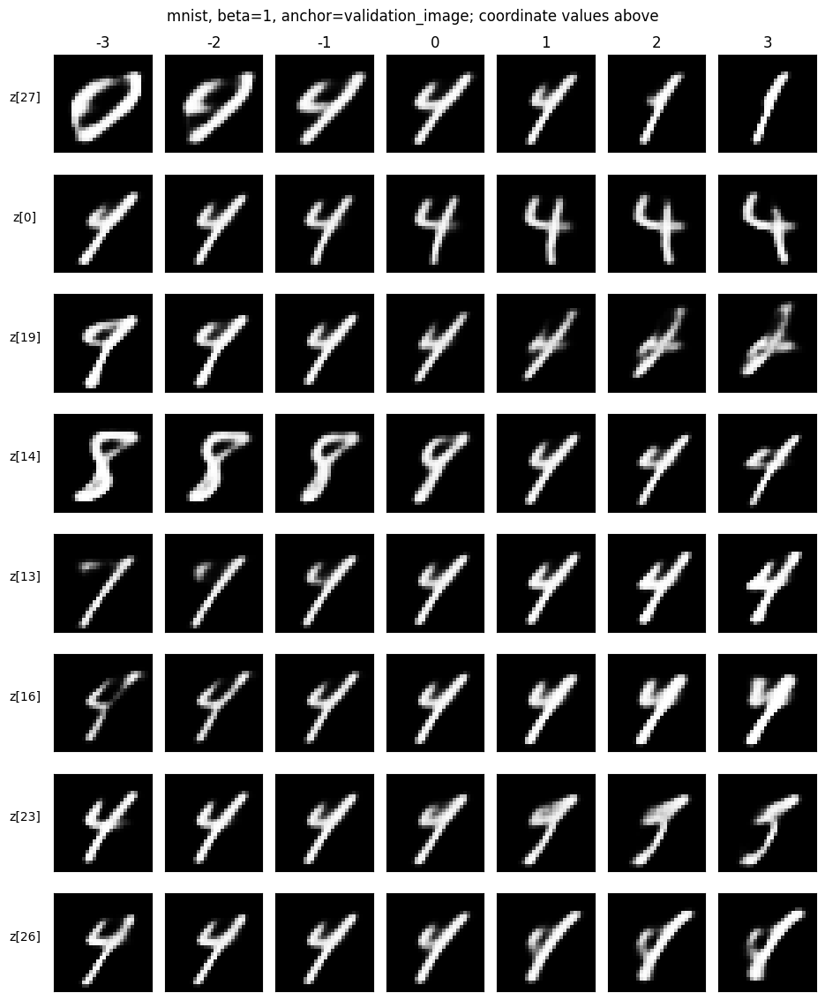

...

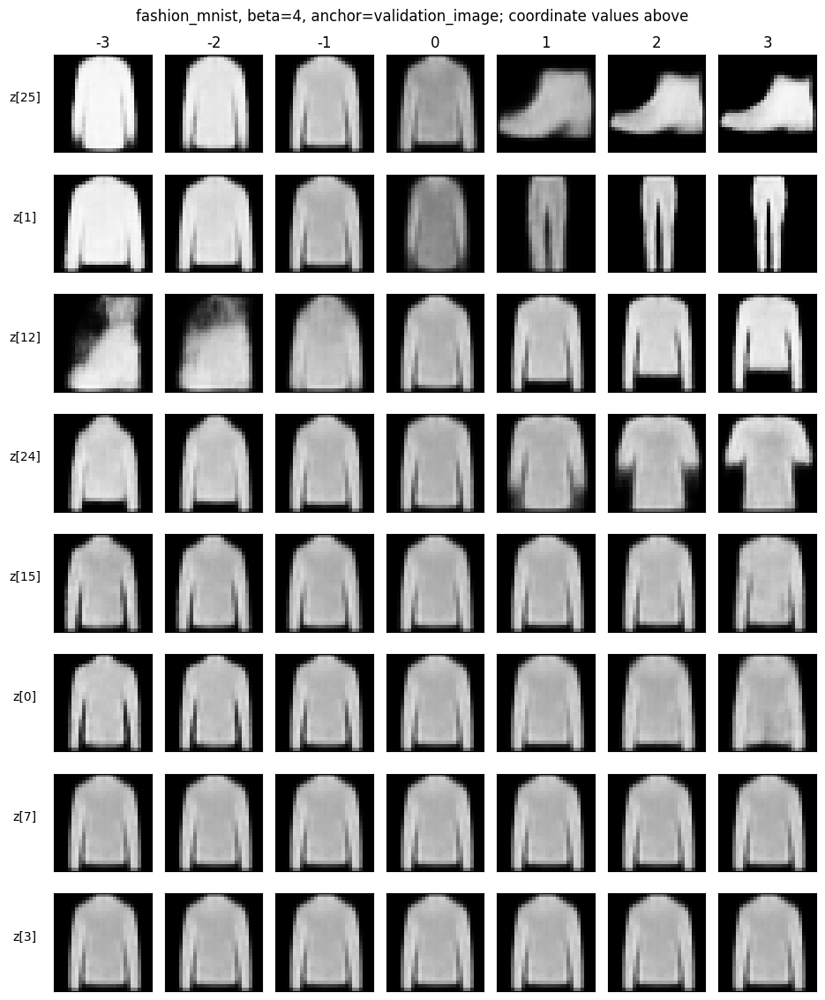

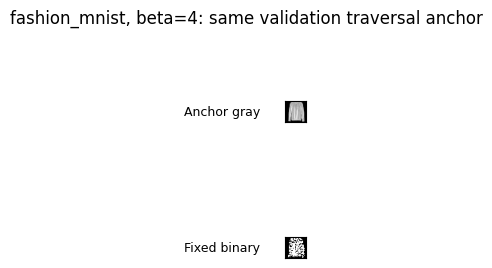

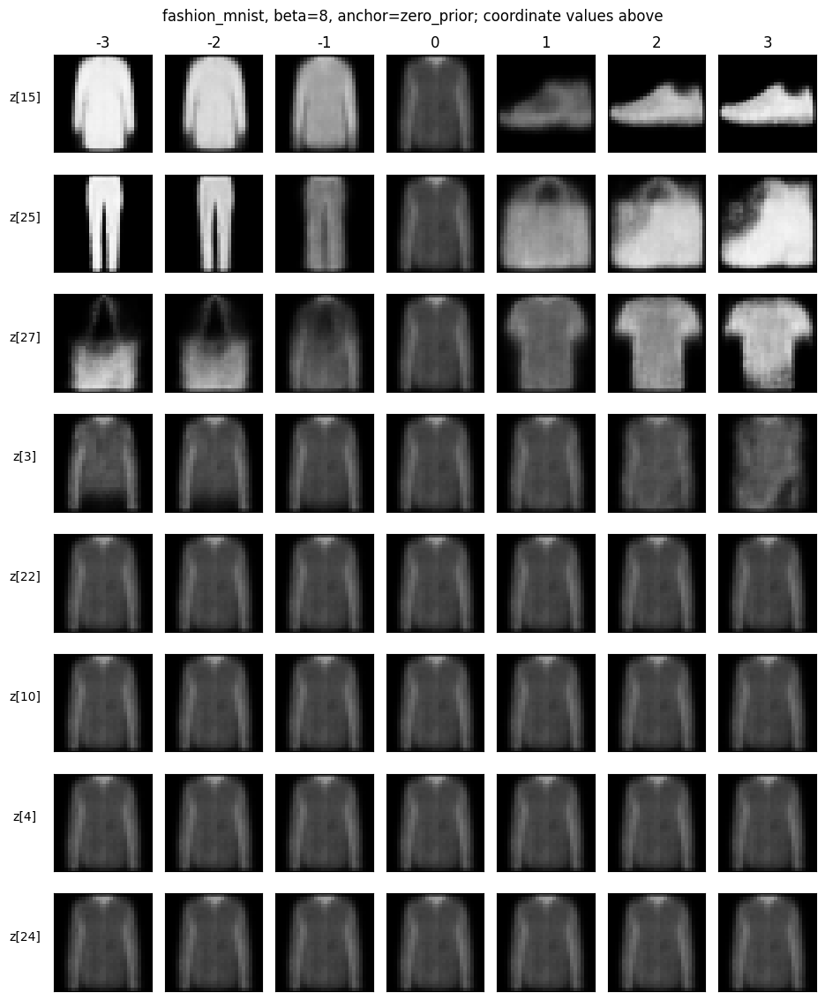

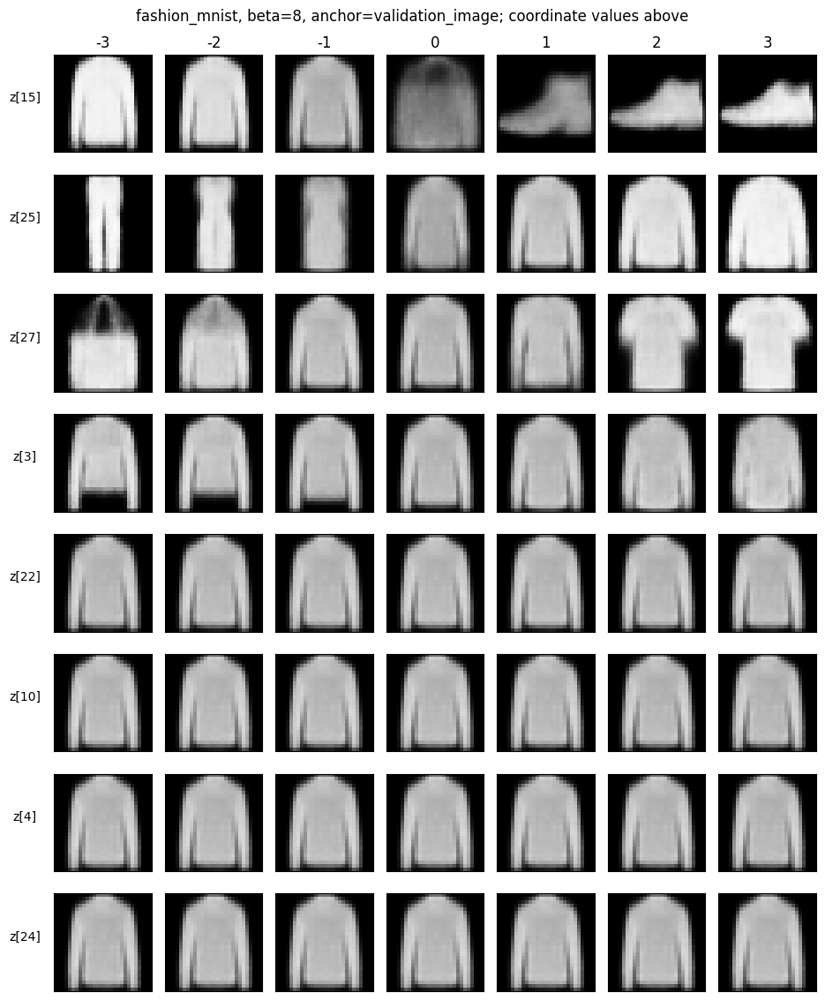

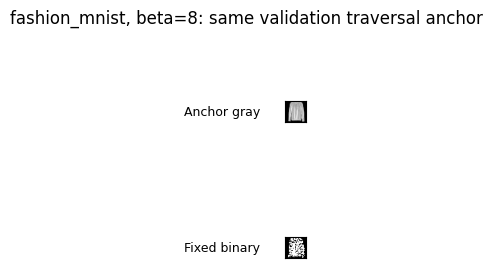

In [53]:
def traversal_codes(anchor,dimension,values):
    codes=anchor.reshape(1,-1).repeat(len(values),1)
    codes[:,dimension]=torch.as_tensor(values,device=codes.device,dtype=codes.dtype)
    return codes

@torch.no_grad()
def plot_beta_traversal(model,anchor,dimensions,values,title,path):
    model.eval()
    fig,axes=plt.subplots(len(dimensions),len(values),
                          figsize=(1.35*len(values),1.45*len(dimensions)),squeeze=False)
    for row,dimension in enumerate(dimensions):
        images=torch.sigmoid(model.decode(traversal_codes(anchor,dimension,values))).cpu()
        for column,(ax,image) in enumerate(zip(axes[row],images)):
            ax.imshow(image.squeeze(),cmap='gray',vmin=0,vmax=1)
            ax.set_xticks([])
            ax.set_yticks([])
            if row==0: ax.set_title(f'{values[column]:g}')
        axes[row,0].set_ylabel(f'z[{dimension}]',rotation=0,labelpad=24)
    fig.suptitle(('SMOKE TEST | ' if SMOKE_TEST else '')+title)
    fig.tight_layout()
    fig.savefig(path,dpi=130,bbox_inches='tight')
    plt.show()
    plt.close(fig)

for run in beta_runs:
    dataset,beta=run['dataset'],run['beta']
    model=ConvVAE(BETA_LATENT_DIM).to(DEVICE)
    model.load_state_dict(torch.load(run['checkpoint'],map_location=DEVICE,weights_only=True)['model'])
    model.eval()
    _,validation=training_loaders(dataset)
    gray=validation.dataset[0][0].unsqueeze(0)
    binary=torch.bernoulli(gray,generator=torch.Generator().manual_seed(1234)).to(DEVICE)
    with torch.no_grad(): encoded_anchor,_=model.encode(binary)
    folder=BETA_RESULTS/dataset/f'beta_{beta_tag(beta)}'
    values=[-2.,0.,2.] if SMOKE_TEST else BETA_TRAVERSAL_VALUES
    dimensions=beta_traversal_dimensions[(dataset,beta)]
    for name,anchor in [('zero_prior',torch.zeros(BETA_LATENT_DIM,device=DEVICE)),
                        ('validation_image',encoded_anchor[0])]:
        plot_beta_traversal(model,anchor,dimensions,values,
                            f'{dataset}, beta={beta:g}, anchor={name}; coordinate values above',
                            folder/f'traversal_{name}.png')
    vae_panel([('Anchor gray',gray),('Fixed binary',binary)],
              f'{dataset}, beta={beta:g}: same validation traversal anchor',folder/'traversal_anchor.png',columns=1)


### 4.6 Final comparison across beta values

The final panels compare the same original images, reconstructions and matched prior generations. Higher beta increased reconstruction error and left fewer active coordinates. This shows a regularization tradeoff, rather than proof that the latent factors became fully disentangled.


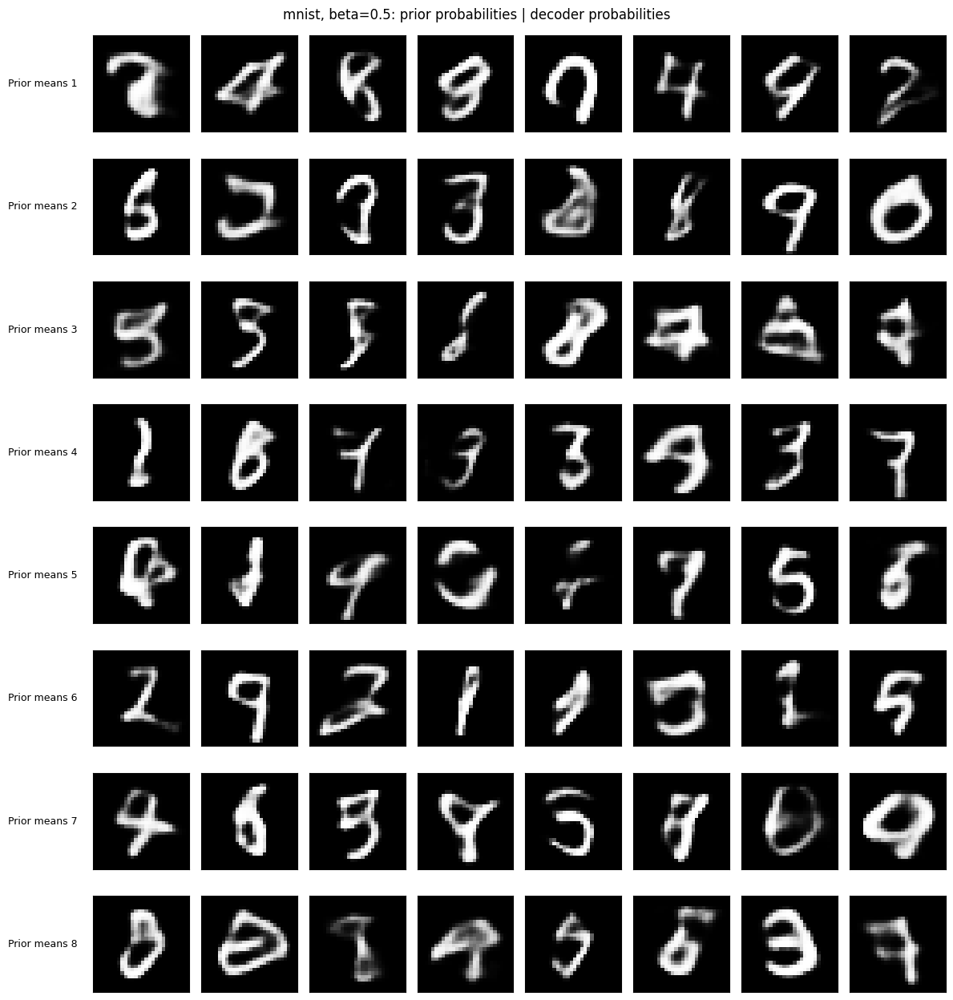

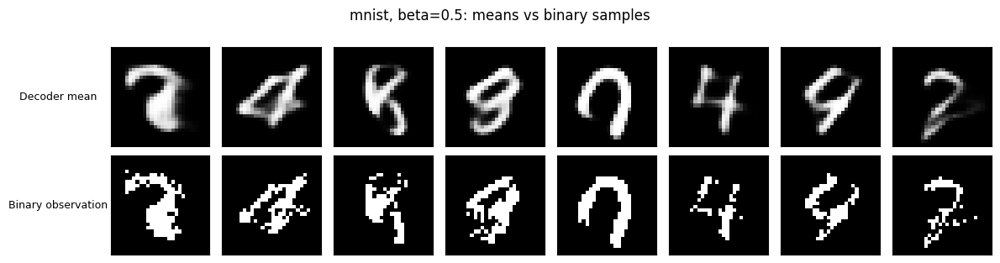

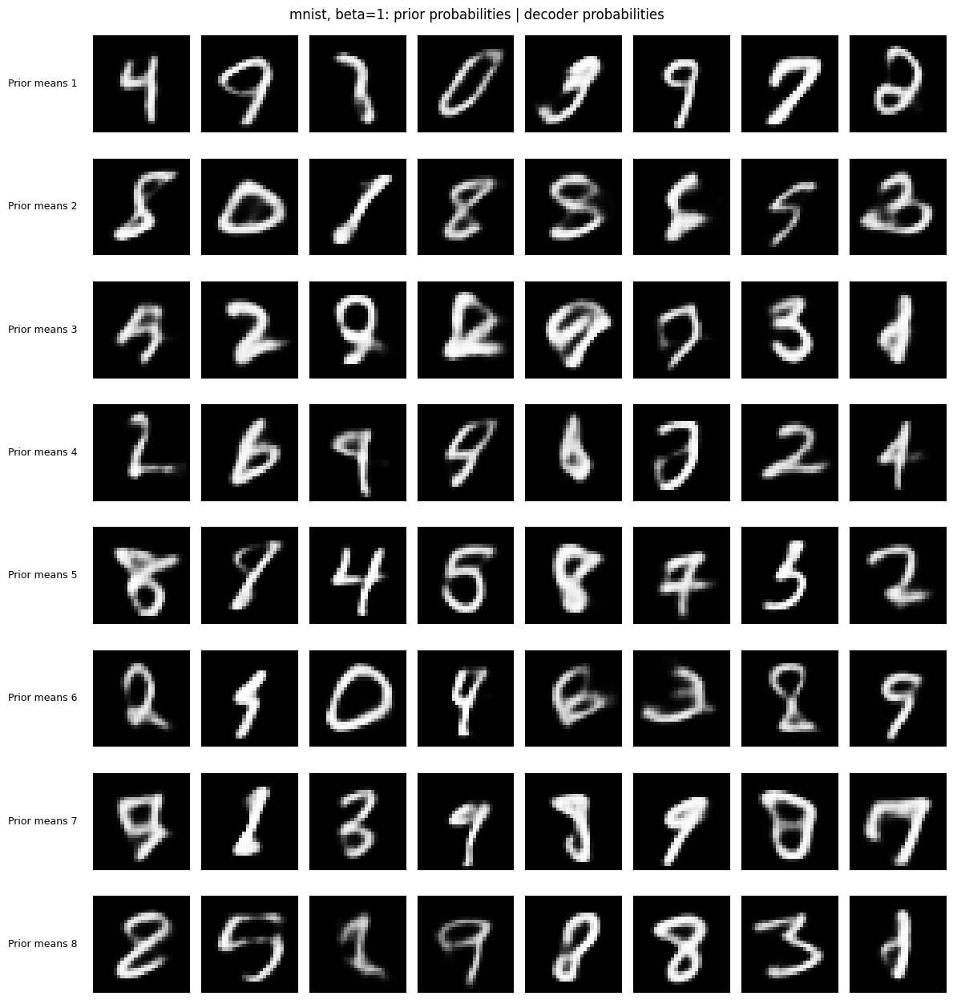

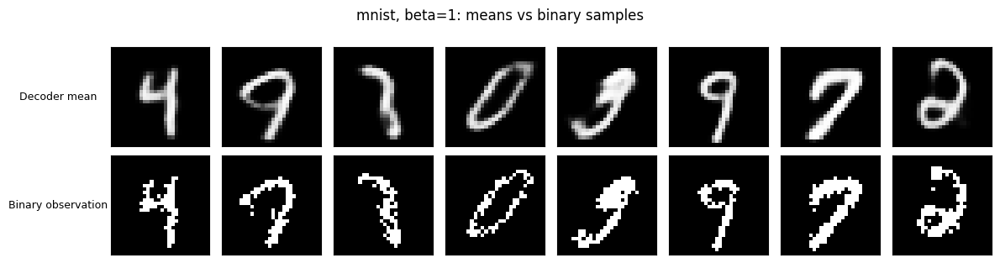

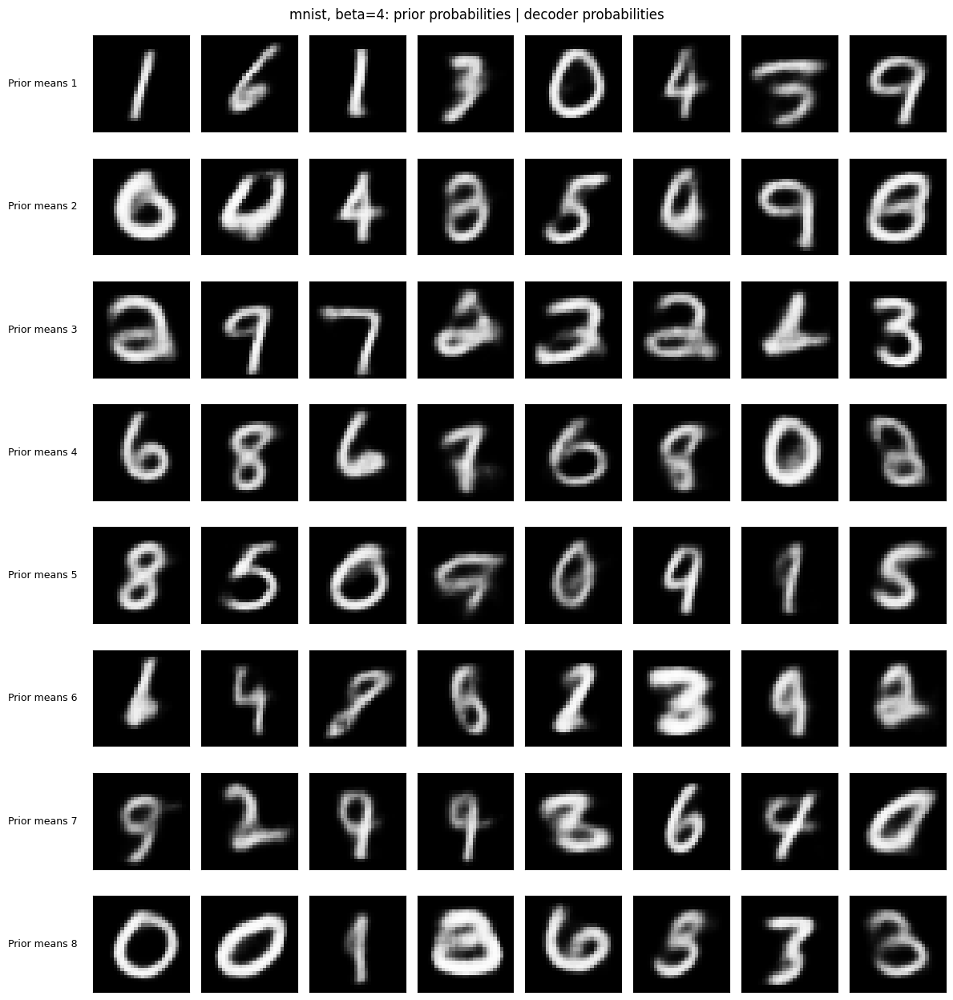

...

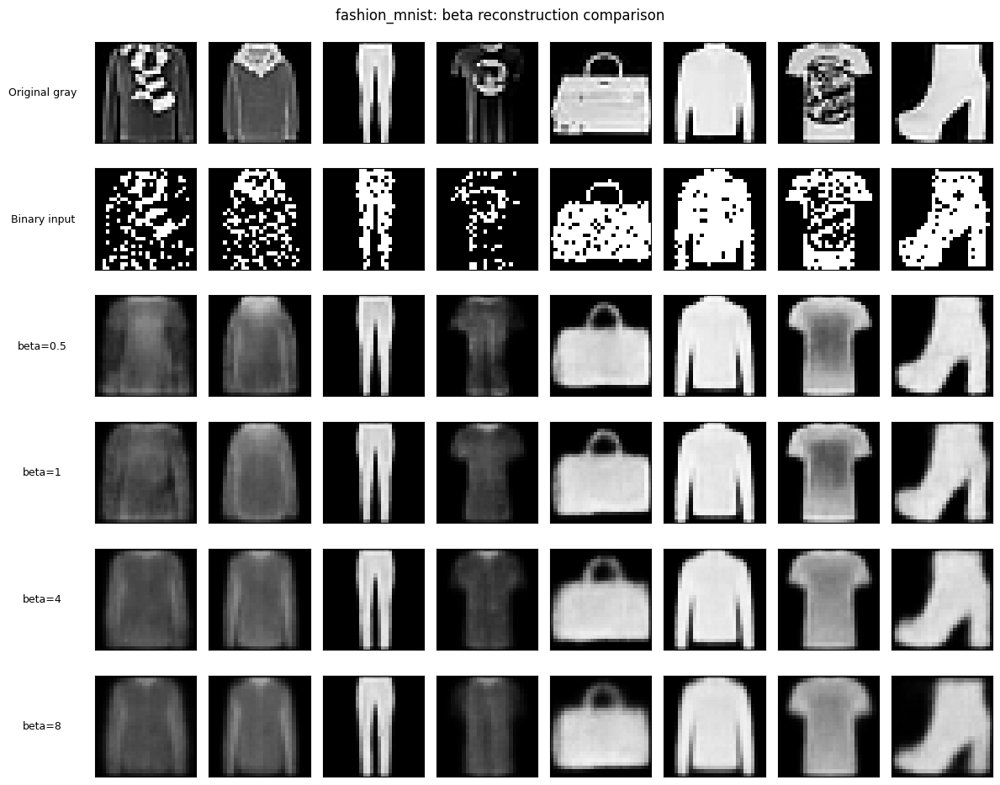

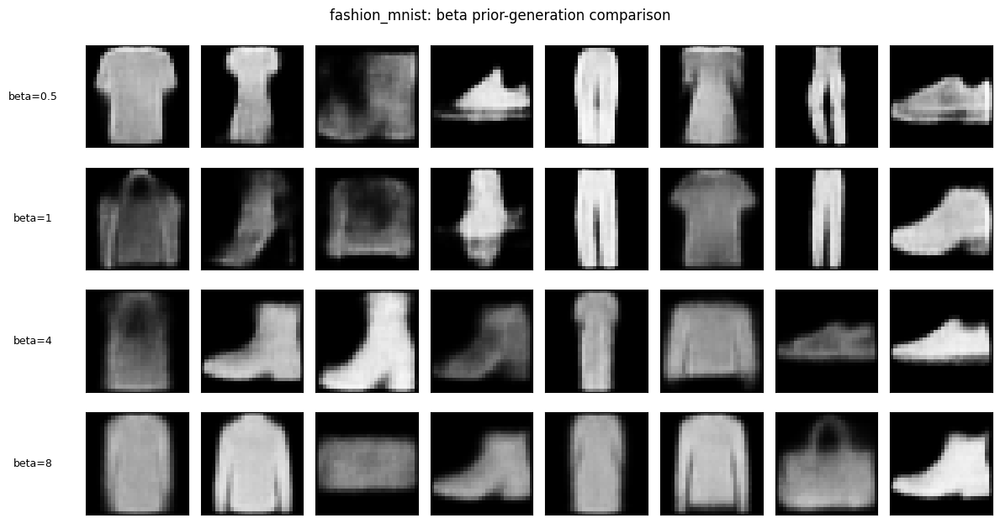

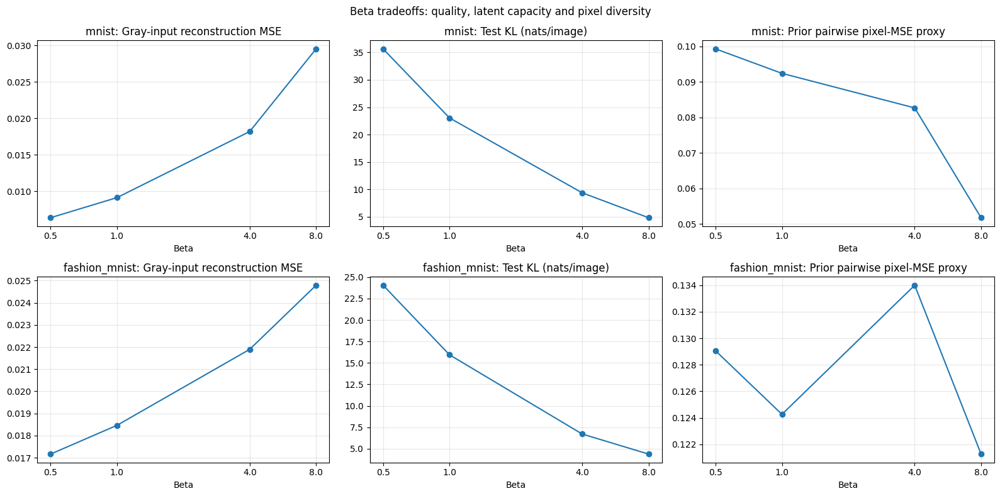

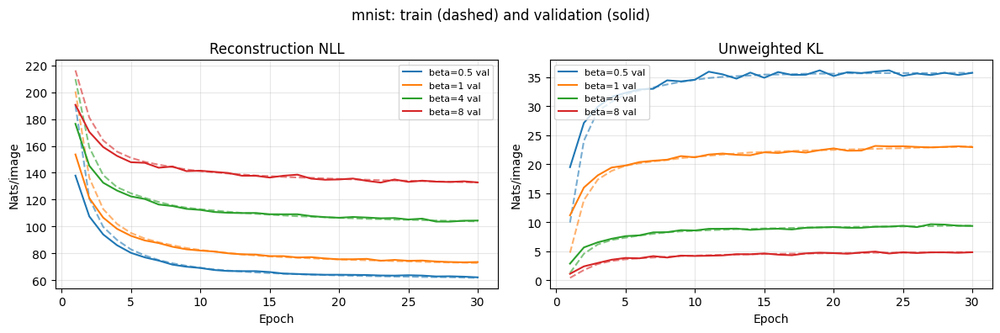

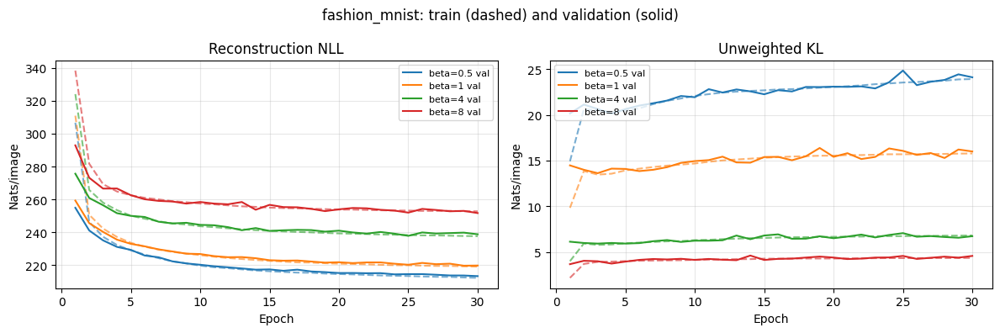

In [54]:
for dataset in DATASET_NAMES:
    ds=testing_loader(dataset).dataset
    indices=torch.randperm(len(ds),generator=torch.Generator().manual_seed(123))[:8]
    gray=torch.stack([ds[int(index)][0] for index in indices])
    binary=torch.bernoulli(gray,generator=torch.Generator().manual_seed(1234))
    reconstruction_rows=[('Original gray',gray),('Binary input',binary)]
    generation_rows=[]
    for run in (r for r in beta_runs if r['dataset']==dataset):
        beta=run['beta']
        model=ConvVAE(BETA_LATENT_DIM).to(DEVICE)
        model.load_state_dict(torch.load(run['checkpoint'],map_location=DEVICE,weights_only=True)['model'])
        model.eval()
        with torch.no_grad():
            mu,_=model.encode(binary.to(DEVICE))
            reconstruction=torch.sigmoid(model.decode(mu)).cpu()
        reconstruction_rows.append((f'beta={beta:g}',reconstruction))
        probabilities,pixels=vae_sample_grid(model,f'{dataset}, beta={beta:g}: prior probabilities',
                                             BETA_RESULTS/f'{dataset}_beta_{beta_tag(beta)}_prior.png')
        generation_rows.append((f'beta={beta:g}',probabilities[:8]))
        vae_panel([('Decoder mean',probabilities[:8]),('Binary observation',pixels[:8])],
                  f'{dataset}, beta={beta:g}: means vs binary samples',
                  BETA_RESULTS/f'{dataset}_beta_{beta_tag(beta)}_observations.png')
    vae_panel(reconstruction_rows,dataset+': beta reconstruction comparison',
              BETA_RESULTS/f'{dataset}_reconstruction_comparison.png')
    vae_panel(generation_rows,dataset+': beta prior-generation comparison',
              BETA_RESULTS/f'{dataset}_generation_comparison.png')

fig,axes=plt.subplots(len(DATASET_NAMES),3,figsize=(16,4*len(DATASET_NAMES)),squeeze=False)
for row,dataset in enumerate(DATASET_NAMES):
    table=beta_test_results.loc[beta_test_results.dataset==dataset].sort_values('beta')
    for ax,column,title in zip(axes[row],['gray_mse','kl','prior_pairwise_pixel_mse'],
                                ['Gray-input reconstruction MSE','Test KL (nats/image)','Prior pairwise pixel-MSE proxy']):
        ax.plot(table.beta,table[column],'o-')
        ax.set_xscale('log',base=2)
        ax.set_xticks(BETA_VALUES,labels=[str(b) for b in BETA_VALUES])
        ax.set(title=dataset+': '+title,xlabel='Beta')
        ax.grid(alpha=0.3)
fig.suptitle(('SMOKE TEST | ' if SMOKE_TEST else '')+'Beta tradeoffs: quality, latent capacity and pixel diversity')
fig.tight_layout()
fig.savefig(BETA_RESULTS/'beta_tradeoffs.png',dpi=130)
plt.show()
plt.close(fig)

for dataset in DATASET_NAMES:
    fig,axes=plt.subplots(1,2,figsize=(12,4))
    for beta in BETA_VALUES:
        history=pd.read_csv(BETA_RESULTS/dataset/f'beta_{beta_tag(beta)}'/'history.csv')
        for ax,metric,title in zip(axes,['reconstruction_nll','kl'],['Reconstruction NLL','Unweighted KL']):
            line,=ax.plot(history.epoch,history['val_'+metric],label=f'beta={beta:g} val')
            ax.plot(history.epoch,history['train_'+metric],'--',color=line.get_color(),alpha=0.6)
            ax.set(title=title,xlabel='Epoch',ylabel='Nats/image')
            ax.grid(alpha=0.3)
            ax.legend(fontsize=8)
    fig.suptitle(dataset+': train (dashed) and validation (solid)')
    fig.tight_layout()
    fig.savefig(BETA_RESULTS/f'{dataset}_learning_curves.png',dpi=130)
    plt.show()
    plt.close(fig)
